# Data Exploration & Dashboard Development
## Music Listening Habits and Reported Music Effects  
**Student:** Lama Mansour Aldhalaan
  

### Notebook roadmap
This notebook follows eda in order and gives each requirement its own labeled section.

1. **Choose Dataset**
2. **Problem Definition**
3. **Data Loading & Structure**
4. **Data Cleaning & Preprocessing**
5. **Exploratory Data Analysis (EDA)**
6. **Insights Summary**
7. **Final Summary**


---

## Navigation

| Step | What it covers | Jump |
|---|---|---|
| 1 | Choose a dataset (title, source, description, why) | [Step 1](#step1) |
| 2 | Problem definition | [Step 2](#step2) |
| 3 | Data loading & structure (`head`, `shape`, `info`, `describe`, missing values) | [Step 3](#step3) |
| 4 | Data cleaning & preprocessing (and saving `clean_data.csv`) | [Step 4](#step4) |
| 5 | Exploratory data analysis: [univariate](#eda-univariate) and [bivariate / multivariate](#eda-bivariate) | [Step 5](#step5) |
| 6 | Insights summary | [Step 6](#step6) |
| 7 | Final summary | [Step 7](#step7) |

> **How to run:** put the dataset CSV next to this notebook, then use *Run → Run all cells* (Colab: *Runtime → Run all*). Everything is written to the folder `music_eda_project_outputs/`.

##EDA flow

| Requirements                                | steps|
|---|---|
| Dataset title, source link, 3–4 line description, why selected | [Step 1](#step1) |
| What the data is about, main questions, expected insights | [Step 2](#step2) |
| `df.head()`, `df.shape`, `df.info()`, `df.describe()`, `df.isnull().sum()` | [Step 3](#step3) |
| Missing values, duplicates, data types, renamed columns, saved clean CSV | [Step 4](#step4) |
| Univariate: histograms, countplots, boxplots | [5.1](#eda-univariate) |
| Bivariate / multivariate: scatter plots, bar plots, correlation heatmap | [5.2](#eda-bivariate) |
| Insights: patterns, relationships, outliers, key takeaways | [Step 6](#step6) |
| Final summary, limitations, recommendations | [Step 7](#step7) |


<a id="step1"></a>

# Step 1 — Choose a Dataset

## Dataset title

**Music & Mental Health Survey topic: Music Listening Habits and Reported Music Effects**

## Source

The original dataset is based on the MXMH (Music & Mental Health) Survey by Catherine Rasgaitis on Kaggle. Additional research papers informed the dataset's expansion and the selection of variables.

- [Original MXMH survey dataset on Kaggle](https://www.kaggle.com/datasets/catherinerasgaitis/mxmh-survey-results)
- [Creator’s Music x Mental Health project](https://crasgaitis.github.io/mental_music/)
- [Music Therapy Practices and Perspectives Regarding the Mental Health Needs of People With Intellectual Disabilities (2026)](https://doi.org/10.1093/mtp/miag005)
- [Clinical Implications of College Students’ Music Listening Habits and Perceptions of Personal Impact (2025)](https://doi.org/10.1093/mtp/miaf008)

## Dataset description

The original MXMH survey explores music-listening habits, music preferences, and perceived music effects. The dataset was expanded using supplementary survey responses and insights from two research papers: *Music Therapy Practices and Perspectives Regarding the Mental Health Needs of People With Intellectual Disabilities* and *Clinical Implications of College Students’ Music Listening Habits and Perceptions of Personal Impact*.

Additional variables include `music_genre`, `listening_time`, `listening_setting`, `vibe_reason`, and `mental_disorder`. The expanded dataset supports exploring relationships between music habits and perceived effects.

## Why this topic was selected

Music can influence how people express emotions, cope with stress, and connect with others. I wanted to explore why music affects people differently, whether people with different mental-health conditions show different music preferences, and how listening habits and personal motivations relate to the perceived effects of music.


<a id="step2"></a>

# Step 2 — Problem Definition

## What is the dataset about?
The dataset describes music-listening habits and reported music effects. It includes demographic information (such as age), listening duration and time, music genre, streaming service, listening purpose, and a reported effects category.

## Main questions to explore
1. Does people with mental disorders have different preferences in music than others and do they follow a specific pattern?
1. What are the distributions of age, daily listening hours, and BPM?
2. Which music genres, listening times, and listening purposes appear most frequently?
3. How do daily listening hours vary across the reported music-effect categories?
4. Does the distribution of reported music effects differ across listening times or music genres?
5. Is there a visible association between age and daily listening hours?
6. Which numerical variables have the strongest pairwise correlations?
7. Which listening purposes and vibe reasons are most strongly associated with the reported effect?
8. What data-quality issues, outliers, and limitations should be documented?




In [78]:
project_questions = [
    "What do age, daily listening hours, and BPM distributions look like?",
    "Which music genres and listening times are most common?",
    "How do listening hours vary by reported music effects?",
    "Do reported music effects vary across listening times or music genres?",
    "Is age associated with daily listening duration?",
    "What numerical correlations and potential outliers are present?",
    "Which listening purposes and vibe reasons go with Improve / No effect / Worsen reports?",
]
for number, question in enumerate(project_questions, start=1):
    print(f"{number}. {question}")

1. What do age, daily listening hours, and BPM distributions look like?
2. Which music genres and listening times are most common?
3. How do listening hours vary by reported music effects?
4. Do reported music effects vary across listening times or music genres?
5. Is age associated with daily listening duration?
6. What numerical correlations and potential outliers are present?
7. Which listening purposes and vibe reasons go with Improve / No effect / Worsen reports?


<a id="step3"></a>

# Step 3 — Data Loading & Structure

## 3.1 Import the libraries
We use **Pandas** to load and inspect the data, **NumPy** for numerical handling, and **Matplotlib/Seaborn** for charts. `pathlib` manages the output folders.

In [79]:
from pathlib import Path
import re
import shutil
import textwrap
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
PURPLE_PALETTE = ["#4c00b0", "#7600bc", "#8a00c2", "#a000c8", "#b100cd", "#be2ed6", "#ca5cdd", "#da8ee7", "#e8bcf0"]
from matplotlib.colors import LinearSegmentedColormap
PURPLE_CMAP = LinearSegmentedColormap.from_list("user_purple", PURPLE_PALETTE, N=256)
PURPLE_DIVERGING = LinearSegmentedColormap.from_list("user_purple_diverging", [PURPLE_PALETTE[0], PURPLE_PALETTE[4], PURPLE_PALETTE[8]], N=256)
sns.set_theme(style="whitegrid", context="notebook", palette=PURPLE_PALETTE, rc={"axes.edgecolor": "#da8ee7", "grid.color": "#e8bcf0", "grid.alpha": 0.45, "axes.labelcolor": "#4c00b0", "xtick.color": "#4c00b0", "ytick.color": "#4c00b0"})

# path of the entire project
PROJECT_DIR = Path("music_eda_project_outputs")
OUTPUT_DIR = PROJECT_DIR / "eda_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project output folder:", PROJECT_DIR.resolve())
print("EDA chart folder:", OUTPUT_DIR.resolve())

Project output folder: /content/music_eda_project_outputs
EDA chart folder: /content/music_eda_project_outputs/eda_outputs


## 3.2 Load the CSV file
The notebook looks for `Music.csv` (the project file) or `mxmh_music_dataset_renamed.csv` beside the notebook, in `/content` (Colab), or in `/mnt/data`. If none is found in Colab, it asks you to upload the CSV.

In [3]:
INPUT_FILENAMES = ["Music_Mental_Health.csv", "clean_music_data.csv", "Music_eda_engineered_transport_social(1).csv", "Music_eda_engineered_transport_social.csv", "Music.csv", "Music(1).csv", "mxmh_music_dataset_renamed.csv"]
search_paths = [Path(folder) / name for name in INPUT_FILENAMES
                for folder in (".", "/content", "/mnt/data", "/mnt/user-data/uploads")]
input_path = next((p for p in search_paths if p.exists()), None)

if input_path is None:
    try:
        from google.colab import files
        print("Upload the approved project CSV file (for example, Music.csv).")
        uploaded = files.upload()
        csv_names = [name for name in uploaded if name.lower().endswith(".csv")]
        if not csv_names:
            raise FileNotFoundError("No CSV was uploaded. Please upload your project dataset.")
        input_path = Path(csv_names[0])
    except ImportError as exc:
        raise FileNotFoundError(
            f"Could not find {INPUT_FILENAMES}. Put the CSV beside this notebook or upload it in Google Colab."
        ) from exc

df_raw = pd.read_csv(input_path)
print("Loaded file:", input_path)
print("Raw data shape:", df_raw.shape)

Upload the approved project CSV file (for example, Music.csv).


Saving Music_Mental_Health.csv to Music_Mental_Health (1).csv
Loaded file: Music_Mental_Health (1).csv
Raw data shape: (1000, 15)


## 3.3 Display the first five rows — `df.head()`
This is the first visual check that the CSV loaded correctly and the columns contain the expected type of information.

In [4]:
df_raw.head()

,Age,Primary streaming service,Hours per day,Listening_Time,Listening_Setting,Instrumentalist,Composer,Exploratory,Foreign languages,BPM,Music effects,Mental_Disorder,Music_Genre,Vibe_Reason,Repeats_Songs_Often
0,39,Apple Music,4.43,Late night,Home / relaxing,No,Yes,No,No,75.7,Improve,Anxiety,Lofi,Calming/relaxation,Yes
1,21,I do not use a streaming service.,3.60,Evening,Home / relaxing,No,No,No,No,84.2,Improve,Autism (ASD),Electronic,Familiarity and emotional comfort,Yes
2,29,Other streaming service,4.65,Afternoon,Other,No,No,No,No,99.7,No effect,No reported condition,Instrumental,Familiarity and emotional comfort,No
3,17,Spotify,6.80,Late night,Home / relaxing,Yes,No,Yes,Yes,71.7,Improve,Anxiety,Lofi,Calming/relaxation,No
4,25,Spotify,4.79,Late night,Gym / exercising,Yes,No,Yes,Yes,52.7,Improve,Anxiety,Classical,Calming/relaxation,No


## 3.4 Check the dataset shape — `df.shape`
`shape` returns a tuple of **(rows, columns)**. Rows represent records and columns represent variables.

In [5]:
print("Rows:", df_raw.shape[0])
print("Columns:", df_raw.shape[1])
print("Shape:", df_raw.shape)

Rows: 1000
Columns: 15
Shape: (1000, 15)


## 3.5 Inspect column data types — `df.info()`
This identifies numerical columns, text/categorical columns, and non-null counts before cleaning.

In [6]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 15 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Age                        1000 non-null   int64  
 1   Primary streaming service  1000 non-null   object 
 2   Hours per day              1000 non-null   float64
 3   Listening_Time             1000 non-null   object 
 4   Listening_Setting          1000 non-null   object 
 5   Instrumentalist            1000 non-null   object 
 6   Composer                   1000 non-null   object 
 7   Exploratory                1000 non-null   object 
 8   Foreign languages          1000 non-null   object 
 9   BPM                        1000 non-null   float64
 10  Music effects              1000 non-null   object 
 11  Mental_Disorder            1000 non-null   object 
 12  Music_Genre                1000 non-null   object 
 13  Vibe_Reason                1000 non-null   object

## 3.6 Descriptive statistics — `df.describe()`
The default `describe()` summarizes numerical columns. The second view includes categorical columns so we can see category counts and the most common values too.

In [7]:
display(df_raw.describe().T)
display(df_raw.describe(include="all").T)

,count,mean,std,min,25%,50%,75%,max
Age,1000.0,24.67900,11.336422,13.00,18.000,21.00,27.000,82.0
Hours per day,1000.0,5.18311,1.752998,1.01,3.975,4.85,6.870,7.8
BPM,1000.0,90.42760,23.582978,50.00,72.500,86.20,105.625,159.3


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,1000.0,NaN,NaN,NaN,24.679,11.336422,13.0,18.0,21.0,27.0,82.0
Primary streaming service,1000,6,Spotify,612,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Hours per day,1000.0,NaN,NaN,NaN,5.18311,1.752998,1.01,3.975,4.85,6.87,7.8
Listening_Time,1000,4,Late night,501,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Listening_Setting,1000,8,Home / relaxing,418,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Instrumentalist,1000,2,No,667,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Composer,1000,2,No,862,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Exploratory,1000,2,Yes,755,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Foreign languages,1000,2,Yes,735,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BPM,1000.0,NaN,NaN,NaN,90.4276,23.582978,50.0,72.5,86.2,105.625,159.3


## 3.7 Check missing values — `df.isnull().sum()`
We check missing values per column and calculate their percentage. Do not fill or remove values before understanding where missingness occurs.

In [8]:
missing_before = pd.DataFrame({
    "missing_count": df_raw.isnull().sum(),
    "missing_percent": (df_raw.isnull().mean() * 100).round(2),
})
display(missing_before.sort_values("missing_count", ascending=False))
print("Total missing cells:", int(df_raw.isnull().sum().sum()))

,missing_count,missing_percent
Age,0,0.0
Primary streaming service,0,0.0
Hours per day,0,0.0
Listening_Time,0,0.0
Listening_Setting,0,0.0
Instrumentalist,0,0.0
Composer,0,0.0
Exploratory,0,0.0
Foreign languages,0,0.0
BPM,0,0.0


Total missing cells: 0


<a id="step4"></a>

# Step 4 — Data Cleaning & Preprocessing

This section standardizes names, removes the columns that are not needed, checks duplicates, trims text, converts numeric fields, validates obvious impossible values, handles missing values only when needed, and exports `clean_data.csv`.

Potential outliers are not deleted after checking, values such as older ages or high BPM could be valid observations; those will investigated later in EDA.

## 4.1 Standardize column names
All columns are converted to lowercase.

- `preferred_music_genre` / `fav_genre` → `music_genre`
- `simulated_mental_health_group` → `mental_disorder`
- `music_preference_reason` → `vibe_reason`

Columns `mood_before_listening`, `mood_after_listening`, and `listening_context` are removed.

In [9]:
def normalize_name(name):
    """Convert a column label to lowercase snake_case."""
    name = str(name).strip().lower()
    name = re.sub(r"[^a-z0-9]+", "_", name)
    return name.strip("_")

alias_map = {
    "preferred_music_genre": "music_genre",
    "fav_genre": "music_genre",
    "music_genre": "music_genre",
    "simulated_mental_health_group": "mental_disorder",
    "mental_disorder": "mental_disorder",
    "music_preference_reason": "vibe_reason",
    "vibe_reason": "vibe_reason",
}

# Uses a fresh copy
df_work = df_raw.copy()
df_work.columns = [normalize_name(c) for c in df_work.columns]
df_work = df_work.rename(columns={c: alias_map[c] for c in df_work.columns if c in alias_map})

requested_removals = {"mood_before_listening", "mood_after_listening", "listening_context"}
columns_to_remove = [c for c in df_work.columns if normalize_name(c) in requested_removals]
df_work = df_work.drop(columns=columns_to_remove, errors="ignore")

# Checking if two source columns map to the same standardized name, combine non-missing values,
# then keep one column to avoid ambiguous duplicate labels.
if df_work.columns.duplicated().any():
    for duplicate_name in pd.Index(df_work.columns[df_work.columns.duplicated()]).unique():
        duplicate_block = df_work.loc[:, df_work.columns == duplicate_name]
        df_work = df_work.loc[:, df_work.columns != duplicate_name]
        df_work[duplicate_name] = duplicate_block.bfill(axis=1).iloc[:, 0]

print("Removed columns:", columns_to_remove if columns_to_remove else "None present")
print("Standardized columns:")
print(df_work.columns.tolist())
display(pd.DataFrame({"standardized_column": df_work.columns}))

Removed columns: None present
Standardized columns:
['age', 'primary_streaming_service', 'hours_per_day', 'listening_time', 'listening_setting', 'instrumentalist', 'composer', 'exploratory', 'foreign_languages', 'bpm', 'music_effects', 'mental_disorder', 'music_genre', 'vibe_reason', 'repeats_songs_often']


,standardized_column
0,age
1,primary_streaming_service
2,hours_per_day
3,listening_time
4,listening_setting
5,instrumentalist
6,composer
7,exploratory
8,foreign_languages
9,bpm


## 4.2 Clean text values and standardize missing-value markers
Leading/trailing spaces are removed. Empty strings and common missing-value placeholders are converted to actual `NaN` values so Pandas can count them correctly.

In [10]:
missing_markers = {"", "na", "n/a", "null", "none"}
for col in df_work.select_dtypes(include=["object", "string"]).columns:
    df_work[col] = df_work[col].astype("string").str.strip()
    df_work[col] = df_work[col].mask(
        df_work[col].str.lower().isin(missing_markers), pd.NA
    )

print("Missing values after text cleanup:", int(df_work.isna().sum().sum()))

Missing values after text cleanup: 0


## 4.3 Check duplicate rows and remove exact duplicates
We report the number of exact duplicate rows before removing them. Repeated category values (for example, many respondents choosing the same genre) are normal and are not considered duplicate records.

In [11]:
duplicates_before = int(df_work.duplicated().sum())
df_work = df_work.drop_duplicates().copy()
duplicates_removed = duplicates_before - int(df_work.duplicated().sum())
print("Exact duplicate rows before cleaning:", duplicates_before)
print("Exact duplicate rows removed:", duplicates_removed)
print("Rows remaining:", len(df_work))

Exact duplicate rows before cleaning: 0
Exact duplicate rows removed: 0
Rows remaining: 1000


## 4.4 Convert relevant columns to numeric data types
`age`, `hours_per_day`, and `bpm` should be numeric if present. Invalid text entries are converted to missing values and handled in the next step.

In [12]:
numeric_columns = [c for c in ["age", "hours_per_day", "bpm"] if c in df_work.columns]
for col in numeric_columns:
    df_work[col] = pd.to_numeric(df_work[col], errors="coerce")

print("Numeric columns converted:", numeric_columns)
display(df_work[numeric_columns].dtypes.to_frame("dtype") if numeric_columns else pd.DataFrame(columns=["dtype"]))

Numeric columns converted: ['age', 'hours_per_day', 'bpm']


,dtype
age,int64
hours_per_day,float64
bpm,float64


## 4.5 Validate obvious impossible values
This check flags values that are outside broad plausible input ranges. The thresholds are checks for data-entry errors, not rules for deleting statistically unusual observations. Any value changed to missing is reported before imputation.

In [13]:
invalid_value_counts = {}
range_checks = {
    "age": (0, 100),
    "hours_per_day": (0, 24),
    "bpm": (1, 300),
}
for col, (low, high) in range_checks.items():
    if col in df_work.columns:
        invalid_mask = df_work[col].notna() & ~df_work[col].between(low, high)
        invalid_value_counts[col] = int(invalid_mask.sum())
        if invalid_mask.any():
            print(f"{col}: {invalid_mask.sum()} values outside [{low}, {high}] converted to missing.")
            df_work.loc[invalid_mask, col] = np.nan
        else:
            print(f"{col}: no values outside [{low}, {high}].")

display(pd.Series(invalid_value_counts, name="values_outside_review_range").to_frame())

age: no values outside [0, 100].
hours_per_day: no values outside [0, 24].
bpm: no values outside [1, 300].


,values_outside_review_range
age,0
hours_per_day,0
bpm,0


## 4.6 Handle remaining missing values
If a numerical column has missing values, fill them with its median. If a categorical/text column has missing values, we label them `Unknown`. This approach is applied when missing values actually exist, and its use is documented in the cleaning summary.

In [14]:
missing_before_imputation = int(df_work.isna().sum().sum())
imputation_log = []

for col in df_work.columns:
    count_missing = int(df_work[col].isna().sum())
    if count_missing == 0:
        continue

    if pd.api.types.is_numeric_dtype(df_work[col]):
        median_value = df_work[col].median()
        if pd.isna(median_value):
            df_work[col] = df_work[col].fillna(0)
            method = "filled with 0 because no numeric median was available"
        else:
            df_work[col] = df_work[col].fillna(median_value)
            method = f"filled with median ({median_value})"
    else:
        df_work[col] = df_work[col].fillna("Unknown")
        method = "filled with 'Unknown'"
    imputation_log.append({"column": col, "missing_filled": count_missing, "method": method})

imputation_summary = pd.DataFrame(imputation_log, columns=["column", "missing_filled", "method"])
if imputation_summary.empty:
    print("No missing values required imputation.")
else:
    display(imputation_summary)
print("Missing cells before imputation:", missing_before_imputation)
print("Missing cells after imputation:", int(df_work.isna().sum().sum()))

No missing values required imputation.
Missing cells before imputation: 0
Missing cells after imputation: 0


## 4.7 Standardize key category labels and confirm data types
The target `music_effects` is standardized to the categories `Improve`, `No effect`, and `Worsen` when the corresponding labels are present. Other values are preserved rather than silently discarded.

In [15]:
if "music_effects" in df_work.columns:
    effect_map = {
        "improve": "Improve",
        "improved": "Improve",
        "no effect": "No effect",
        "no effects": "No effect",
        "worsen": "Worsen",
        "worsened": "Worsen",
    }
    df_work["music_effects"] = df_work["music_effects"].map(
        lambda value: effect_map.get(str(value).strip().lower(), str(value).strip())
        if pd.notna(value) else value
    )

# Whole-number ages are stored as integers after missing-value handling.
if "age" in df_work.columns:
    df_work["age"] = pd.to_numeric(df_work["age"], errors="coerce")
    if df_work["age"].notna().all() and np.allclose(df_work["age"], df_work["age"].round()):
        df_work["age"] = df_work["age"].round().astype("int64")

if "hours_per_day" in df_work.columns:
    df_work["hours_per_day"] = pd.to_numeric(df_work["hours_per_day"], errors="coerce")
if "bpm" in df_work.columns:
    df_work["bpm"] = pd.to_numeric(df_work["bpm"], errors="coerce")

clean_df = df_work.copy()
print("Final shape:", clean_df.shape)
print("Final column names:", clean_df.columns.tolist())
clean_df.info()

Final shape: (1000, 15)
Final column names: ['age', 'primary_streaming_service', 'hours_per_day', 'listening_time', 'listening_setting', 'instrumentalist', 'composer', 'exploratory', 'foreign_languages', 'bpm', 'music_effects', 'mental_disorder', 'music_genre', 'vibe_reason', 'repeats_songs_often']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 15 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   age                        1000 non-null   int64  
 1   primary_streaming_service  1000 non-null   string 
 2   hours_per_day              1000 non-null   float64
 3   listening_time             1000 non-null   string 
 4   listening_setting          1000 non-null   string 
 5   instrumentalist            1000 non-null   string 
 6   composer                   1000 non-null   string 
 7   exploratory                1000 non-null   string 
 8   foreign_languages          10

## 4.8 Saving the cleaned dataset to CSV

In [16]:
clean_csv_path = Path("clean_data.csv")
clean_df.to_csv(clean_csv_path, index=False)
project_clean_path = PROJECT_DIR / "clean_data.csv"
clean_df.to_csv(project_clean_path, index=False)
print("Cleaned dataset saved to:", clean_csv_path.resolve())
print("Project copy saved to:", project_clean_path.resolve())
print("Rows:", clean_df.shape[0], "| Columns:", clean_df.shape[1])

Cleaned dataset saved to: /content/clean_data.csv
Project copy saved to: /content/music_eda_project_outputs/clean_data.csv
Rows: 1000 | Columns: 15


## 4.9 Post-cleaning quality audit
The output below documents the remaining missing values, duplicates, and updated data types.

In [17]:
quality_summary = pd.DataFrame({
    "check": [
        "Rows after cleaning",
        "Columns after cleaning",
        "Missing cells after cleaning",
        "Exact duplicate rows after cleaning",
        "Duplicate rows removed",
        "Invalid-range values converted to missing",
    ],
    "result": [
        len(clean_df),
        clean_df.shape[1],
        int(clean_df.isna().sum().sum()),
        int(clean_df.duplicated().sum()),
        duplicates_removed,
        int(sum(invalid_value_counts.values())),
    ],
})
display(quality_summary)
display(pd.DataFrame({
    "dtype": clean_df.dtypes.astype(str),
    "missing_count": clean_df.isna().sum(),
}).sort_values("missing_count", ascending=False))

,check,result
0,Rows after cleaning,1000
1,Columns after cleaning,15
2,Missing cells after cleaning,0
3,Exact duplicate rows after cleaning,0
4,Duplicate rows removed,0
5,Invalid-range values converted to missing,0


,dtype,missing_count
age,int64,0
primary_streaming_service,string,0
hours_per_day,float64,0
listening_time,string,0
listening_setting,string,0
instrumentalist,string,0
composer,string,0
exploratory,string,0
foreign_languages,string,0
bpm,float64,0


<a id="step5"></a>

# Step 5 — Exploratory Data Analysis (EDA)

This section explores each of the **15 dataset variables** and the possible relationships. Each plot is in its **own code cell**.

**Univariate:** numeric variables receive a histogram with KDE and a boxplot. Categorical variables receive a countplot and a second bar chart of **raw counts** (raw counts). **Relationship:** numeric–numeric uses a scatterplot plus correlation heatmap; categorical–numeric uses boxplots; categorical–categorical uses grouped count bars plus a count heatmap.

Each plotting cell includes code comments and prints an observation calculated from the current cleaned dataset.


### Plots index

**5.1 Univariate: 15 variables** (histogram + KDE and boxplot for numbers, countplot and sorted bar for categories)

- [Univariate 01 — Age](#u01)
- [Univariate 02 — Hours per day](#u02)
- [Univariate 03 — BPM](#u03)
- [Univariate 04 — Primary streaming service](#u04)
- [Univariate 05 — Listening time](#u05)
- [Univariate 06 — Listening setting](#u06)
- [Univariate 07 — Instrumentalist](#u07)
- [Univariate 08 — Composer](#u08)
- [Univariate 09 — Exploratory](#u09)
- [Univariate 10 — Foreign languages](#u10)
- [Univariate 11 — Music effects](#u11)
- [Univariate 12 — Mental disorder](#u12)
- [Univariate 13 — Music genre](#u13)
- [Univariate 14 — Vibe reason](#u14)
- [Univariate 15 — Repeats songs often](#u15)

**5.2 Bivariate / multivariate: 15 relationships and the numeric correlation matrix**

- [Relationship 01 — Age vs. hours per day](#r01)
- [Relationship 02 — Age vs. listening time](#r02)
- [Relationship 03 — Age vs. listening setting](#r03)
- [Relationship 04 — Instrumentalist vs. foreign languages](#r04)
- [Relationship 05 — Exploratory vs. foreign languages](#r05)
- [Relationship 06 — Composer vs. listening setting](#r06)
- [Relationship 07 — Instrumentalist vs. hours per day](#r07)
- [Relationship 08 — Composer vs. listening time](#r08)
- [Relationship 09 — Mental disorder vs. music genre](#r09)
- [Relationship 10 — Mental disorder vs. vibe reason](#r10)
- [Relationship 11 — Mental disorder vs. repeats songs often](#r11)
- [Relationship 12 — Mental disorder vs. BPM](#r12)
- [Relationship 13 — Mental disorder vs. listening time](#r13)
- [Relationship 14 — Mental disorder vs. music effects](#r14)
- [Relationship 15 — Music effects vs. music genre](#r15)
- [Overall numeric correlation matrix](#r-corr)

In [18]:
# EDA plotting setup
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display

PURPLE_PALETTE = ["#4c00b0", "#7600bc", "#8a00c2", "#a000c8", "#b100cd", "#be2ed6", "#ca5cdd", "#da8ee7", "#e8bcf0"]
PURPLE_CMAP = LinearSegmentedColormap.from_list("project_purple", PURPLE_PALETTE, N=256)
PURPLE_DIVERGING = LinearSegmentedColormap.from_list("project_purple_diverging", [PURPLE_PALETTE[0], PURPLE_PALETTE[4], PURPLE_PALETTE[8]], N=256)
PLOT_DIR = Path("plots")
PLOT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(
    style="whitegrid", context="notebook", palette=PURPLE_PALETTE,
    rc={"figure.facecolor": "white", "axes.facecolor": "#fffaff", "axes.edgecolor": "#da8ee7",
        "axes.labelcolor": "#4c00b0", "text.color": "#4c00b0", "xtick.color": "#4c00b0",
        "ytick.color": "#4c00b0", "grid.color": "#e8bcf0", "grid.alpha": .45,
        "axes.titleweight": "bold", "axes.titlesize": 13, "axes.labelsize": 10,
        "savefig.facecolor": "white"}
)

PRETTY = {
    "age": "Age", "primary_streaming_service": "Primary streaming service",
    "hours_per_day": "Hours per day", "listening_time": "Listening time",
    "listening_setting": "Listening setting", "instrumentalist": "Instrumentalist",
    "composer": "Composer", "exploratory": "Exploratory", "foreign_languages": "Foreign languages",
    "bpm": "BPM", "music_effects": "Music effects", "mental_disorder": "Mental disorder (simulated/engineered where applicable)",
    "music_genre": "Music genre", "vibe_reason": "Vibe reason", "repeats_songs_often": "Repeats songs often",
    "listening_purpose": "Listening purpose",
}
NUMERIC_COLS = [c for c in ["age", "hours_per_day", "bpm"] if c in clean_df.columns]
CATEGORICAL_COLS = [c for c in [
    "primary_streaming_service", "listening_time", "listening_setting", "instrumentalist", "composer",
    "exploratory", "foreign_languages", "music_effects", "mental_disorder", "music_genre", "vibe_reason",
    "repeats_songs_often", "listening_purpose"
] if c in clean_df.columns]

CATEGORY_ORDERS = {
    "listening_time": ["Morning", "Afternoon", "Evening", "Late night"],
    "listening_setting": ["Home / relaxing", "Work / study", "Gym / exercising", "Public / Private Transport", "Car / commuting", "While gaming", "Social / with friends", "Anywhere / varies", "Other"],
    "music_effects": ["Improve", "No effect", "Worsen"],
    "instrumentalist": ["No", "Yes"], "composer": ["No", "Yes"], "exploratory": ["No", "Yes"],
    "foreign_languages": ["No", "Yes"], "repeats_songs_often": ["No", "Yes"],
    "mental_disorder": ["Anxiety", "Depression", "ADHD", "Autism (ASD)", "Bipolar disorder", "PTSD", "OCD", "Social anxiety", "Schizophrenia", "No reported condition"],
}


def nice(col):
    return PRETTY.get(col, col.replace("_", " ").title())


def category_order(series, col):
    values = series.dropna().astype(str).unique().tolist()
    preferred = CATEGORY_ORDERS.get(col, [])
    return [v for v in preferred if v in values] + sorted(v for v in values if v not in preferred)


def save_and_show(fig, filename):
    """Save each chart at 300 DPI and display that one chart in this code cell."""
    fig.tight_layout()
    filepath = PLOT_DIR / filename
    filepath.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(filepath, dpi=300, bbox_inches="tight", facecolor="white")

    try:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(OUTPUT_DIR / filename, dpi=300, bbox_inches="tight", facecolor="white")
    except Exception:
        pass
    display(fig)
    plt.close(fig)
    print(f"Saved: {filepath.resolve()}")


def numeric_observation(series, col):
    x = pd.to_numeric(series, errors="coerce").dropna()
    if x.empty:
        return f"{nice(col)} has no valid numeric values to summarize."
    q1, median, q3 = x.quantile([.25, .5, .75])
    iqr = q3 - q1
    n_out = int(((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum())
    skew = x.skew() if len(x) > 2 else 0.0
    shape = "right-skewed" if skew > .5 else "left-skewed" if skew < -.5 else "roughly symmetric"
    return f"{nice(col)}: n={len(x):,}, mean={x.mean():.2f}, median={median:.2f}, IQR={iqr:.2f}; {n_out} observations are flagged by the IQR rule, and the distribution is {shape} (skew={skew:.2f})."


def categorical_observation(series, col):
    s = series.dropna().astype(str)
    if s.empty:
        return f"{nice(col)} has no non-missing categories."
    counts = s.value_counts()
    return f"{nice(col)} has {s.nunique()} observed categories. Most common: {counts.index[0]} (n={int(counts.iloc[0])}); least common: {counts.index[-1]} (n={int(counts.iloc[-1])}). Counts reflect the number of records in each category."


def plot_histogram(df, col):
    x = pd.to_numeric(df[col], errors="coerce").dropna()
    fig, ax = plt.subplots(figsize=(9, 5.2))
    sns.histplot(x=x, bins="fd", kde=True, color=PURPLE_PALETTE[3], edgecolor="white", linewidth=.7, ax=ax)
    for line in ax.lines:
        line.set_color(PURPLE_PALETTE[0]); line.set_linewidth(2.5)
    ax.set(title=f"Distribution of {nice(col)} — Histogram and KDE", xlabel=nice(col), ylabel="Number of records")
    return fig, numeric_observation(x, col)


def plot_numeric_box(df, col):
    x = pd.to_numeric(df[col], errors="coerce").dropna()
    fig, ax = plt.subplots(figsize=(9, 3.8))
    sns.boxplot(x=x, color=PURPLE_PALETTE[7], width=.42,
                flierprops={"marker": "o", "markersize": 4, "markerfacecolor": PURPLE_PALETTE[3], "markeredgecolor": PURPLE_PALETTE[0], "alpha": .75}, ax=ax)
    ax.set(title=f"Spread and Potential Outliers in {nice(col)}", xlabel=nice(col), ylabel="")
    return fig, numeric_observation(x, col)


def plot_countplot(df, col):
    s = df[col].dropna().astype(str)
    order = s.value_counts().index.tolist()
    pal = {v: PURPLE_PALETTE[i % len(PURPLE_PALETTE)] for i, v in enumerate(order)}
    horizontal = len(order) > 8 or (len(order) and max(len(v) for v in order) > 17)
    if horizontal:
        fig, ax = plt.subplots(figsize=(12, max(5.2, .38 * len(order))))
        sns.countplot(data=df, y=col, hue=col, order=order, hue_order=order, palette=pal, dodge=False, legend=False, edgecolor="white", linewidth=.5, ax=ax)
        ax.set(xlabel="Number of records", ylabel=nice(col), title=f"Countplot of {nice(col)}")
        for container in ax.containers: ax.bar_label(container, fmt="%d", padding=3, fontsize=8, color=PURPLE_PALETTE[0])
    else:
        fig, ax = plt.subplots(figsize=(9, 5.2))
        sns.countplot(data=df, x=col, hue=col, order=order, hue_order=order, palette=pal, dodge=False, legend=False, edgecolor="white", linewidth=.5, ax=ax)
        ax.set(ylabel="Number of records", xlabel=nice(col), title=f"Countplot of {nice(col)}")
        ax.tick_params(axis="x", labelrotation=32)
        for label in ax.get_xticklabels(): label.set_horizontalalignment("right")
        for container in ax.containers: ax.bar_label(container, fmt="%d", padding=3, fontsize=8, color=PURPLE_PALETTE[0])
    return fig, categorical_observation(s, col)


def plot_count_bar(df, col):
    """A second univariate view with raw category counts, raw category counts."""
    s = df[col].dropna().astype(str)
    counts = s.value_counts().sort_values(ascending=True)
    colors = [PURPLE_PALETTE[i % len(PURPLE_PALETTE)] for i in range(len(counts))]
    fig, ax = plt.subplots(figsize=(12, max(5.2, .38 * len(counts))))
    bars = ax.barh(counts.index.astype(str), counts.values, color=colors, edgecolor="white", linewidth=.7)
    ax.bar_label(bars, fmt="%d", padding=3, fontsize=8, color=PURPLE_PALETTE[0])
    ax.set_xlim(0, max(1, float(counts.max()) * 1.14))
    ax.set(title=f"Category Counts for {nice(col)}", xlabel="Number of records", ylabel=nice(col))
    obs = f"The highest count is {counts.index[-1]} (n={int(counts.iloc[-1])}); the lowest count is {counts.index[0]} (n={int(counts.iloc[0])}). This chart shows raw counts only, raw category counts."
    return fig, obs


def plot_numeric_pair_scatter(df, xcol, ycol):
    d = df[[xcol, ycol]].apply(pd.to_numeric, errors="coerce").dropna()
    r = d[xcol].corr(d[ycol]) if len(d) > 1 and d[xcol].nunique() > 1 and d[ycol].nunique() > 1 else np.nan
    fig, ax = plt.subplots(figsize=(9, 5.8))
    sns.regplot(data=d, x=xcol, y=ycol, scatter_kws={"alpha": .62, "s": 38, "color": PURPLE_PALETTE[3], "edgecolor": "white", "linewidths": .4}, line_kws={"color": PURPLE_PALETTE[0], "linewidth": 2.5}, ci=95, ax=ax)
    ax.set(title=f"{nice(ycol)} vs. {nice(xcol)}", xlabel=nice(xcol), ylabel=nice(ycol))
    if pd.notna(r):
        ax.text(.02, .97, f"Pearson r = {r:.3f}", transform=ax.transAxes, va="top", color=PURPLE_PALETTE[0], bbox={"boxstyle": "round,pad=.35", "facecolor": "#e8bcf0", "edgecolor": "#ca5cdd"})
        strength = "strong" if abs(r) >= .7 else "moderate" if abs(r) >= .4 else "weak"
        direction = "positive" if r > 0 else "negative" if r < 0 else "near-zero"
        obs = f"Age and hours per day have a {strength} {direction} linear association (Pearson r={r:.3f}, n={len(d):,}). Correlation does not imply causation."
    else:
        obs = "A Pearson correlation could not be estimated for this pair because there are insufficient or constant values."
    return fig, obs


def plot_pair_corr_heatmap(df, xcol, ycol):
    d = df[[xcol, ycol]].apply(pd.to_numeric, errors="coerce").dropna()
    corr = d.corr(method="pearson")
    fig, ax = plt.subplots(figsize=(6.5, 5.2))
    sns.heatmap(corr, cmap=PURPLE_DIVERGING, annot=True, fmt=".2f", vmin=-1, vmax=1, center=0, square=True, linewidths=1.2, linecolor="white", cbar_kws={"label": "Pearson correlation"}, ax=ax)
    ax.set(title=f"Pairwise Correlation Heatmap: {nice(xcol)} and {nice(ycol)}")
    r = corr.loc[xcol, ycol] if xcol in corr and ycol in corr else np.nan
    obs = f"Pearson correlation between {nice(xcol).lower()} and {nice(ycol).lower()} is r={r:.3f} based on {len(d):,} complete pairs. This measures linear association, not causation." if pd.notna(r) else "Correlation could not be computed for this pair."
    return fig, obs


def plot_numeric_by_category_box(df, catcol, numcol):
    d = df[[catcol, numcol]].copy()
    d[numcol] = pd.to_numeric(d[numcol], errors="coerce")
    d = d.dropna()
    medians = d.groupby(catcol, observed=False)[numcol].median().sort_values()
    present = medians.index.astype(str).tolist()
    order = category_order(d[catcol], catcol)
    order = [v for v in order if v in present]
    if len(order) > 10:
        order = sorted(order, key=lambda v: medians.get(v, np.nan))
    fig, ax = plt.subplots(figsize=(max(10, min(16, .8 * len(order) + 4)), 5.8))
    palette = {v: PURPLE_PALETTE[i % len(PURPLE_PALETTE)] for i, v in enumerate(order)}
    sns.boxplot(data=d, x=catcol, y=numcol, hue=catcol, order=order, hue_order=order, palette=palette, dodge=False, legend=False, fliersize=3, linewidth=1.1, ax=ax)
    ax.set(title=f"{nice(numcol)} by {nice(catcol)}", xlabel=nice(catcol), ylabel=nice(numcol))
    ax.tick_params(axis="x", labelrotation=35)
    for label in ax.get_xticklabels(): label.set_horizontalalignment("right")
    if len(medians):
        obs = f"Median {nice(numcol).lower()} ranges from {medians.index[0]} ({medians.iloc[0]:.2f}) to {medians.index[-1]} ({medians.iloc[-1]:.2f}) across {len(medians)} {nice(catcol).lower()} groups. Compare spread and group sizes as well as medians."
    else:
        obs = "No valid numerical values were available for the groups."
    return fig, obs


def pair_crosstab(df, xcol, ycol):
    d = df[[xcol, ycol]].dropna().copy()
    d[xcol] = d[xcol].astype(str); d[ycol] = d[ycol].astype(str)
    return d, pd.crosstab(d[xcol], d[ycol])


def plot_category_pair_bar(df, xcol, ycol, top_n=6):
    """Grouped bar chart of counts. High-cardinality hue variables use top categories for readability."""
    d, ct = pair_crosstab(df, xcol, ycol)
    order_x = category_order(d[xcol], xcol)
    order_y = ct.sum(axis=0).sort_values(ascending=False).index.tolist()
    all_y = len(order_y)
    if all_y > top_n and (xcol == "mental_disorder" or len(order_x) <= 4):
        order_y = order_y[:top_n]
    d = d[d[ycol].isin(order_y)]
    fig_w = max(10, min(20, 6 + .65 * len(order_x) + .4 * len(order_y)))
    fig_h = max(5.5, 0.48 * len(order_y) if len(order_y) > 10 else 5.5)
    fig, ax = plt.subplots(figsize=(fig_w, fig_h))
    palette = {v: PURPLE_PALETTE[i % len(PURPLE_PALETTE)] for i, v in enumerate(order_y)}
    sns.countplot(data=d, x=xcol, hue=ycol, order=[x for x in order_x if x in d[xcol].unique()], hue_order=order_y, palette=palette, edgecolor="white", linewidth=.4, ax=ax)
    ax.set(title=f"Grouped Counts: {nice(ycol)} by {nice(xcol)}", xlabel=nice(xcol), ylabel="Number of records")
    ax.tick_params(axis="x", labelrotation=35)
    for label in ax.get_xticklabels(): label.set_horizontalalignment("right")
    if len(order_y) > 8:
        ax.legend(title=nice(ycol), bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8, ncol=1)
    else:
        ax.legend(title=nice(ycol), fontsize=9)
    counts_all = ct.stack()
    if len(counts_all):
        idx = counts_all.idxmax()
        suffix = f" The grouped bar chart displays the {len(order_y)} most common {nice(ycol).lower()} categories for readability; the heatmap retains all observed categories." if len(order_y) < all_y else ""
        obs = f"Most frequent pair: {idx[0]} × {idx[1]} (n={int(ct.loc[idx[0], idx[1]])}). Raw counts are influenced by the number of records in each group.{suffix}"
    else:
        obs = "No paired non-missing categories were available."
    return fig, obs


def plot_category_pair_heatmap(df, xcol, ycol):
    """Count heatmap for all observed categorical combinations (not percentages)."""
    d, ct = pair_crosstab(df, xcol, ycol)
    fig_w = min(19, max(8, .68 * len(ct.columns) + 4))
    fig_h = min(15, max(5, .48 * len(ct.index) + 2))
    fig, ax = plt.subplots(figsize=(fig_w, fig_h))
    annotate = ct.size <= 100
    sns.heatmap(ct, cmap=PURPLE_CMAP, annot=annotate, fmt="d", linewidths=.45, linecolor="white", cbar_kws={"label": "Number of records"}, ax=ax)
    ax.set(title=f"Count Heatmap: {nice(xcol)} × {nice(ycol)}", xlabel=nice(ycol), ylabel=nice(xcol))
    ax.tick_params(axis="x", labelrotation=40)
    for label in ax.get_xticklabels(): label.set_horizontalalignment("right")
    if ct.size:
        idx = ct.stack().idxmax()
        obs = f"Highest-count cell: {idx[0]} × {idx[1]} (n={int(ct.loc[idx[0], idx[1]])}). The heatmap shows raw counts for every category pair; group size matters when interpreting differences."
    else:
        obs = "No paired non-missing categories were available."
    return fig, obs


def plot_numeric_corr_heatmap(df):
    numeric = df[NUMERIC_COLS].apply(pd.to_numeric, errors="coerce")
    corr = numeric.corr(method="pearson")
    fig, ax = plt.subplots(figsize=(7.5, 6.2))
    sns.heatmap(corr, cmap=PURPLE_DIVERGING, annot=True, fmt=".2f", vmin=-1, vmax=1, center=0, square=True, linewidths=1.2, linecolor="white", cbar_kws={"label": "Pearson correlation"}, ax=ax)
    ax.set(title="Overall Numeric Correlation Matrix: Age, Hours per Day and BPM")
    pairs = []
    for i, c1 in enumerate(corr.columns):
        for c2 in corr.columns[i+1:]:
            if pd.notna(corr.loc[c1, c2]): pairs.append((abs(float(corr.loc[c1, c2])), c1, c2, float(corr.loc[c1, c2])))
    if pairs:
        _, c1, c2, r = sorted(pairs, reverse=True)[0]
        obs = f"Largest absolute correlation among numeric variables: {nice(c1)} × {nice(c2)} (r={r:.3f}). Correlations summarize linear association, not causation."
    else: obs = "There were insufficient numeric data to compute a correlation matrix."
    return fig, obs


<a id="eda-univariate"></a>

## 5.1 Univariate analysis — one variable at a time

Univariate analysis describes the distribution of each column independently. Numeric histograms show shape, while boxplots show the median, spread, and potential outliers. Categorical countplots and count bar charts show how many records fall into each category; they use raw counts.

<a id="u01"></a>

### Univariate 01 — Age

Age describes the respondents' age distribution. Look for the main age range, skewness, and unusually high or low observations.

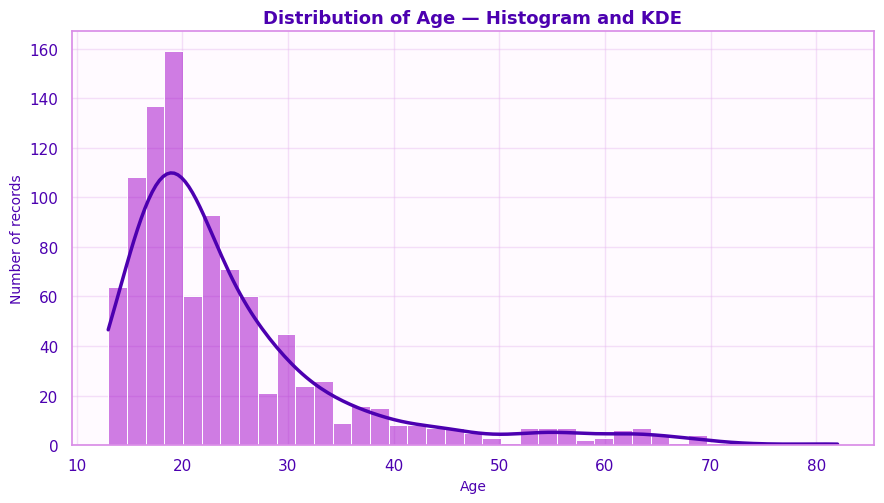

Saved: /content/plots/univ_01_age_hist.png
Observation: Age: n=1,000, mean=24.68, median=21.00, IQR=9.00; 87 observations are flagged by the IQR rule, and the distribution is right-skewed (skew=2.07).


In [19]:
# Feature: Age — histogram with KDE. This shows the shape and concentration of values.
# OBSERVATION: Age ranges from 13 to 82 years; the median is 21 while the mean is 24.7, and skewness is
#     +2.07.
# INTERPRETATION: The right-skew indicates most records are concentrated at younger ages, with a smaller older-
#     age tail pulling the mean above the median; 468/1,000 records (46.8%) are ages 13–20.
fig, observation = plot_histogram(clean_df, "age")
save_and_show(fig, "univ_01_age_hist.png")
print("Observation:", observation)

#### Age — boxplot

The box marks the middle 50% of values; the line is the median and points beyond whiskers are potential IQR outliers, not automatic data errors.

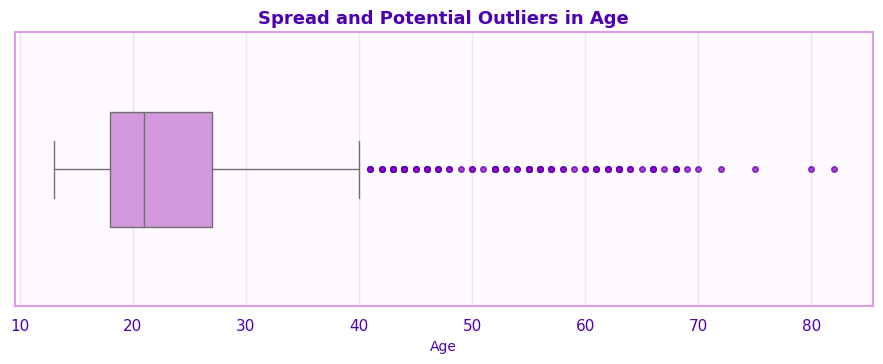

Saved: /content/plots/univ_01_age_box.png
Observation: Age: n=1,000, mean=24.68, median=21.00, IQR=9.00; 87 observations are flagged by the IQR rule, and the distribution is right-skewed (skew=2.07).


In [20]:
# Feature: Age — boxplot. This highlights median, interquartile range, whiskers, and potential outliers.
# OBSERVATION: The median age is 21 years; Q1=18 and Q3=27, so the middle 50% spans ages 18–27 (IQR=9 years).
# INTERPRETATION: The IQR rule flags 87 ages above the upper fence of 40.5; these are statistically unusual in
#     this young-skewed sample, not automatically invalid ages.
fig, observation = plot_numeric_box(clean_df, "age")
save_and_show(fig, "univ_01_age_box.png")
print("Observation:", observation)

<a id="u02"></a>

### Univariate 02 — Hours per day

Daily listening hours describe how much time respondents report listening to music. The distribution may reveal typical listening duration and unusually large values.

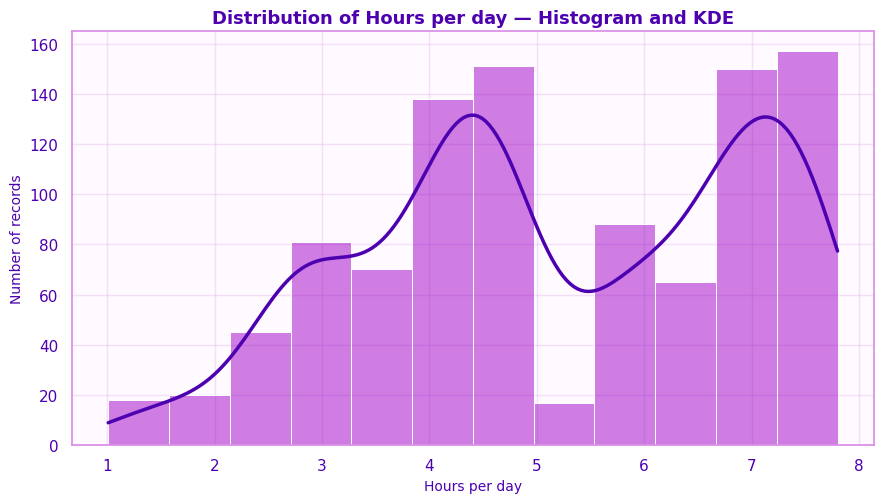

Saved: /content/plots/univ_02_hours_per_day_hist.png
Observation: Hours per day: n=1,000, mean=5.18, median=4.85, IQR=2.90; 0 observations are flagged by the IQR rule, and the distribution is roughly symmetric (skew=-0.19).


In [21]:
# Feature: Hours per day — histogram with KDE. This shows the shape and concentration of values.
# ACTUAL DATA OBSERVATION: Daily listening averages 5.18 hours (median=4.85); the middle 50% runs from 3.98 to 6.87
#     hours.
# INTERPRETATION: The distribution is approximately symmetric with slight left skew (−0.19), spanning 1.01–7.80
#     hours; many records cluster around roughly 4–7 hours.
fig, observation = plot_histogram(clean_df, "hours_per_day")
save_and_show(fig, "univ_02_hours_per_day_hist.png")
print("Observation:", observation)

#### Hours per day — boxplot

The box marks the middle 50% of values; the line is the median and points beyond whiskers are potential IQR outliers, not automatic data errors.

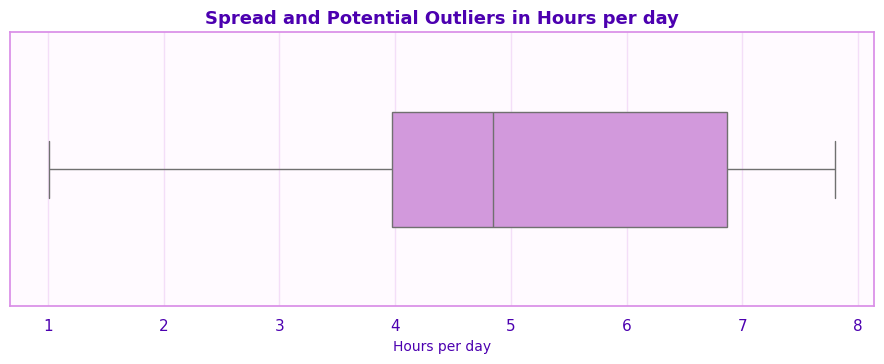

Saved: /content/plots/univ_02_hours_per_day_box.png
Observation: Hours per day: n=1,000, mean=5.18, median=4.85, IQR=2.90; 0 observations are flagged by the IQR rule, and the distribution is roughly symmetric (skew=-0.19).


In [22]:
# Feature: Hours per day — boxplot. This highlights median, interquartile range, whiskers, and potential outliers.
# OBSERVATION: The median is 4.85 hours/day, with Q1=3.98 and Q3=6.87 (IQR=2.90 hours).
# INTERPRETATION: No values fall outside the 1.5×IQR fences in this dataset; the observed range is 1.01–7.80
#     hours, so there are no IQR-flagged extreme durations.
fig, observation = plot_numeric_box(clean_df, "hours_per_day")
save_and_show(fig, "univ_02_hours_per_day_box.png")
print("Observation:", observation)

<a id="u03"></a>

### Univariate 03 — BPM

BPM represents the reported tempo of music in beats per minute. This plot reveals common tempo ranges and unusually slow or fast entries.

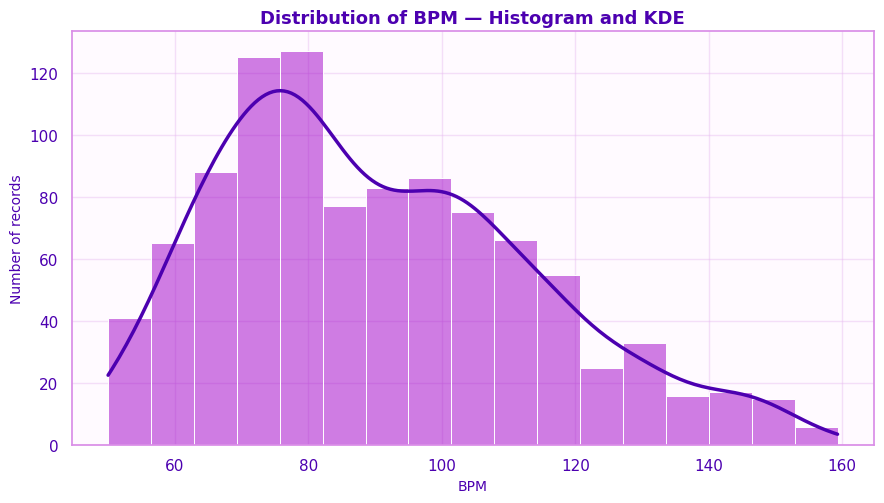

Saved: /content/plots/univ_03_bpm_hist.png
Observation: BPM: n=1,000, mean=90.43, median=86.20, IQR=33.12; 2 observations are flagged by the IQR rule, and the distribution is right-skewed (skew=0.57).


In [23]:
# Feature: BPM — histogram with KDE. This shows the shape and concentration of values.
# OBSERVATION: BPM averages 90.4 with a median of 86.2; the middle half falls between 72.5 and 105.6 BPM.
# INTERPRETATION: Positive skew (+0.57) means a tail of faster tempos pulls the mean above the median; the full
#     observed range is 50.0–159.3 BPM.
fig, observation = plot_histogram(clean_df, "bpm")
save_and_show(fig, "univ_03_bpm_hist.png")
print("Observation:", observation)

#### BPM — boxplot

The box marks the middle 50% of values; the line is the median and points beyond whiskers are potential IQR outliers, not automatic data errors.

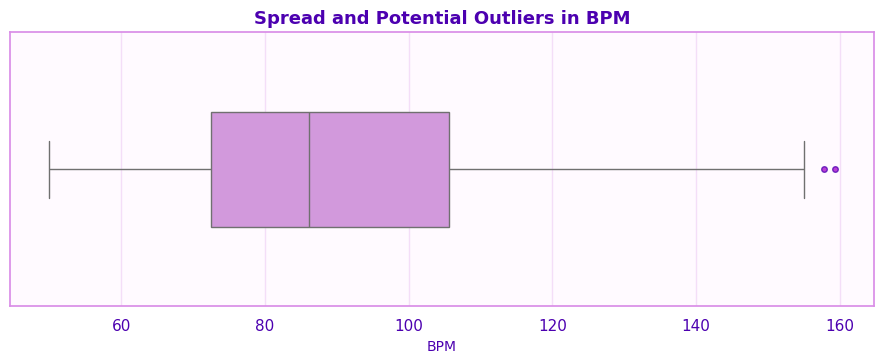

Saved: /content/plots/univ_03_bpm_box.png
Observation: BPM: n=1,000, mean=90.43, median=86.20, IQR=33.12; 2 observations are flagged by the IQR rule, and the distribution is right-skewed (skew=0.57).


In [24]:
# Feature: BPM — boxplot. This highlights median, interquartile range, whiskers, and potential outliers.
# OBSERVATION: The median tempo is 86.2 BPM; Q1=72.5 and Q3=105.6 BPM (IQR=33.1 BPM).
# INTERPRETATION: Two BPM observations exceed the upper IQR fence (~155.3 BPM). They are unusually fast relative
#     to the sample but still within the dataset’s observed maximum of 159.3 BPM.
fig, observation = plot_numeric_box(clean_df, "bpm")
save_and_show(fig, "univ_03_bpm_box.png")
print("Observation:", observation)

<a id="u04"></a>

### Univariate 04 — Primary streaming service

Streaming service shows which platform respondents report using most often.

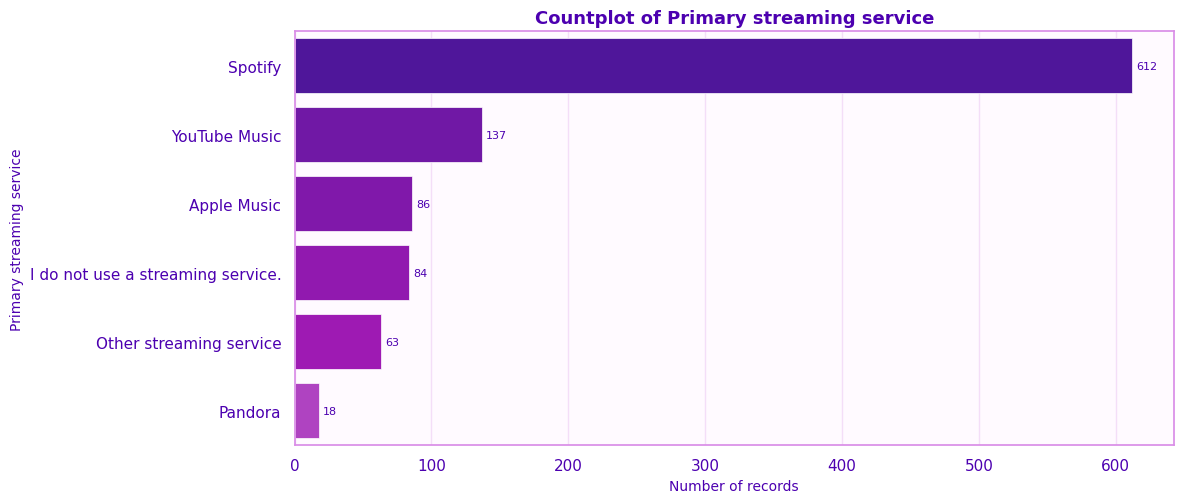

Saved: /content/plots/univ_04_primary_streaming_service.png
Observation: Primary streaming service has 6 observed categories. Most common: Spotify (n=612); least common: Pandora (n=18). Counts reflect the number of records in each category.


In [25]:
# Feature: Primary streaming service — countplot. It shows the number of records in each category; the most frequent category is printed below the chart.
# OBSERVATION: Spotify accounts for 612/1000 records (61.2%), far ahead of YouTube Music (137; 13.7%).
# INTERPRETATION: Pandora is rarest (18 records, 1.8%), showing a strongly concentrated service distribution.
#     Read bar height as the number of records.
fig, observation = plot_countplot(clean_df, "primary_streaming_service")
save_and_show(fig, "univ_04_primary_streaming_service.png")
print("Observation:", observation)

#### Primary streaming service — sorted count bar chart

This second view ranks categories by **raw number of records** so common and uncommon categories are easy to spot. It displays raw category counts.

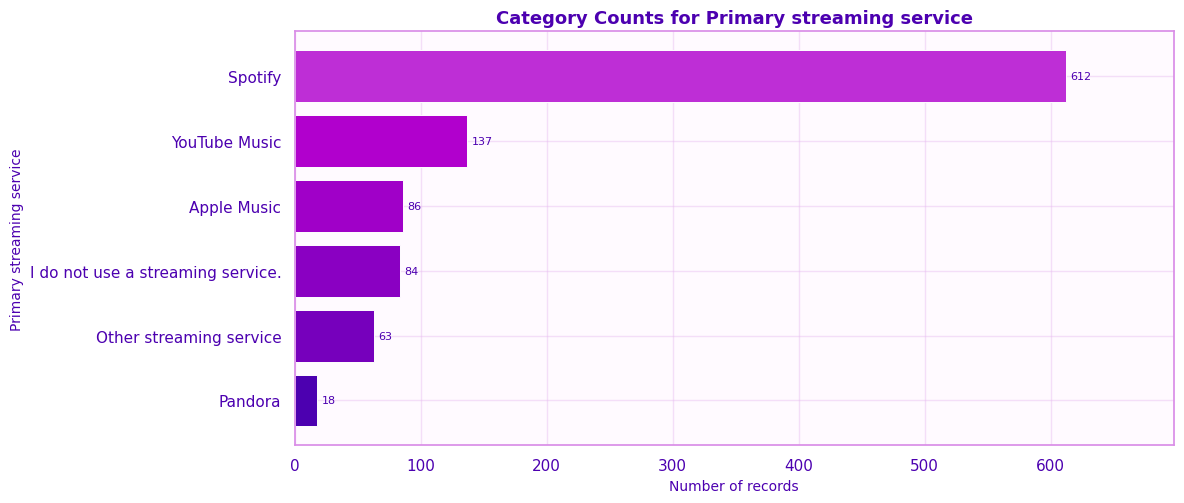

Saved: /content/plots/univ_04_primary_streaming_service_bar.png
Observation: The highest count is Spotify (n=612); the lowest count is Pandora (n=18). This chart shows raw counts only, raw category counts.


In [26]:
# Feature: Primary streaming service — sorted raw-count bar chart. It ranks the categories by record count without converting counts to shares.
# OBSERVATION: Spotify accounts for 612/1000 records (61.2%), far ahead of YouTube Music (137; 13.7%).
# INTERPRETATION: Pandora is rarest (18 records, 1.8%), showing a strongly concentrated service distribution.
#     The axis shows raw counts, not percentages.
fig, observation = plot_count_bar(clean_df, "primary_streaming_service")
save_and_show(fig, "univ_04_primary_streaming_service_bar.png")
print("Observation:", observation)

<a id="u05"></a>

### Univariate 05 — Listening time

Listening time shows when respondents prefer to listen: morning, afternoon, evening, or late night.

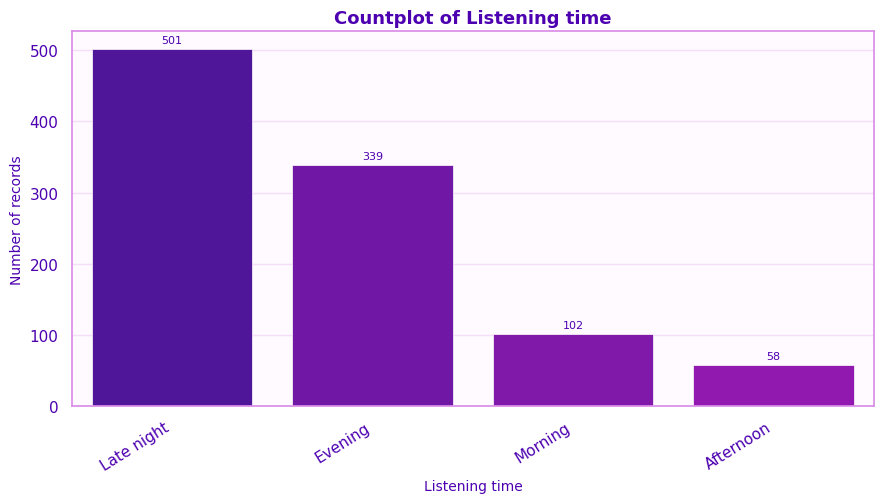

Saved: /content/plots/univ_05_listening_time.png
Observation: Listening time has 4 observed categories. Most common: Late night (n=501); least common: Afternoon (n=58). Counts reflect the number of records in each category.


In [27]:
# Feature: Listening time — countplot. It shows the number of records in each category; the most frequent category is printed below the chart.
# OBSERVATION: Late night is the dominant category (501 records, 50.1%); Evening is second (339 records,
#     33.9%).
# INTERPRETATION: Afternoon is least common (58 records, 5.8%), so listening times are not evenly distributed.
#     Read bar height as the number of records.
fig, observation = plot_countplot(clean_df, "listening_time")
save_and_show(fig, "univ_05_listening_time.png")
print("Observation:", observation)

#### Listening time — sorted count bar chart

This second view ranks categories by **raw number of records** so common and uncommon categories are easy to spot. It displays raw category counts.

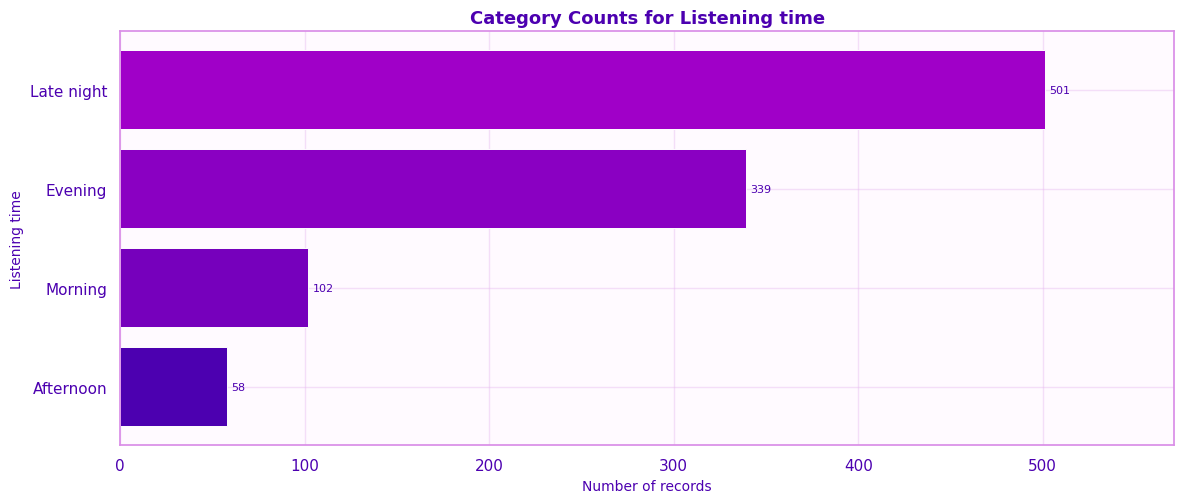

Saved: /content/plots/univ_05_listening_time_bar.png
Observation: The highest count is Late night (n=501); the lowest count is Afternoon (n=58). This chart shows raw counts only, raw category counts.


In [28]:
# Feature: Listening time — sorted raw-count bar chart. It ranks the categories by record count without converting counts to shares.
# OBSERVATION: Late night is the dominant category (501 records, 50.1%); Evening is second (339 records,
#     33.9%).
# INTERPRETATION: Afternoon is least common (58 records, 5.8%), so listening times are not evenly distributed.
#     The axis shows raw counts, not percentages.
fig, observation = plot_count_bar(clean_df, "listening_time")
save_and_show(fig, "univ_05_listening_time_bar.png")
print("Observation:", observation)

<a id="u06"></a>

### Univariate 06 — Listening setting

Listening setting describes where people typically listen, including home, work or study, gym, transport, social settings, gaming, and other contexts.

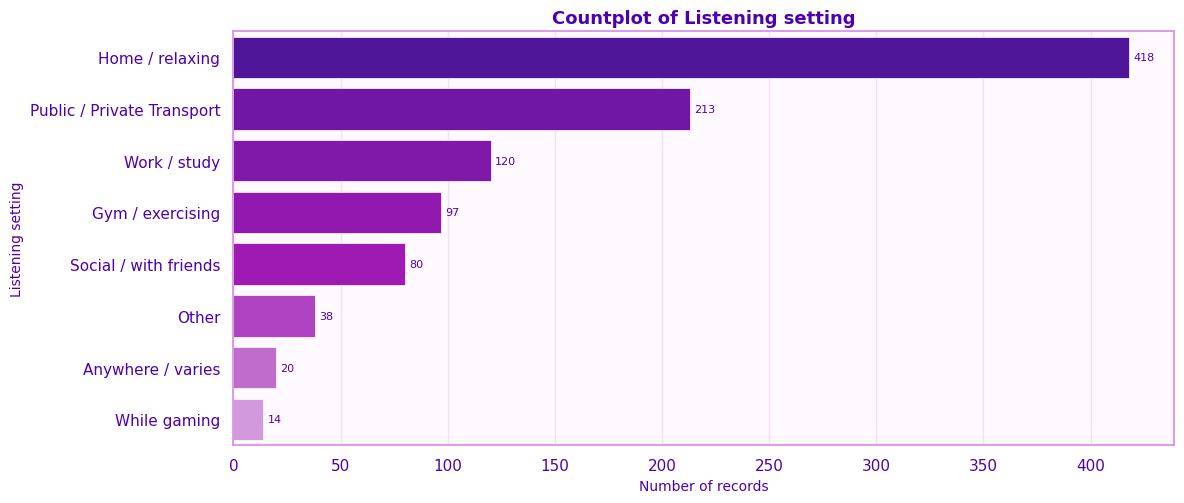

Saved: /content/plots/univ_06_listening_setting.png
Observation: Listening setting has 8 observed categories. Most common: Home / relaxing (n=418); least common: While gaming (n=14). Counts reflect the number of records in each category.


In [29]:
# Feature: Listening setting — countplot. It shows the number of records in each category; the most frequent category is printed below the chart.
# OBSERVATION: Home / relaxing leads (418 records, 41.8%), followed by Public / Private Transport (213
#     records, 21.3%).
# INTERPRETATION: While gaming is the least common setting (14 records, 1.4); Social / with friends accounts for
#     80 records (8.0%). Read bar height as the number of records.
fig, observation = plot_countplot(clean_df, "listening_setting")
save_and_show(fig, "univ_06_listening_setting.png")
print("Observation:", observation)

#### Listening setting — sorted count bar chart

This second view ranks categories by **raw number of records** so common and uncommon categories are easy to spot. It displays raw category counts.

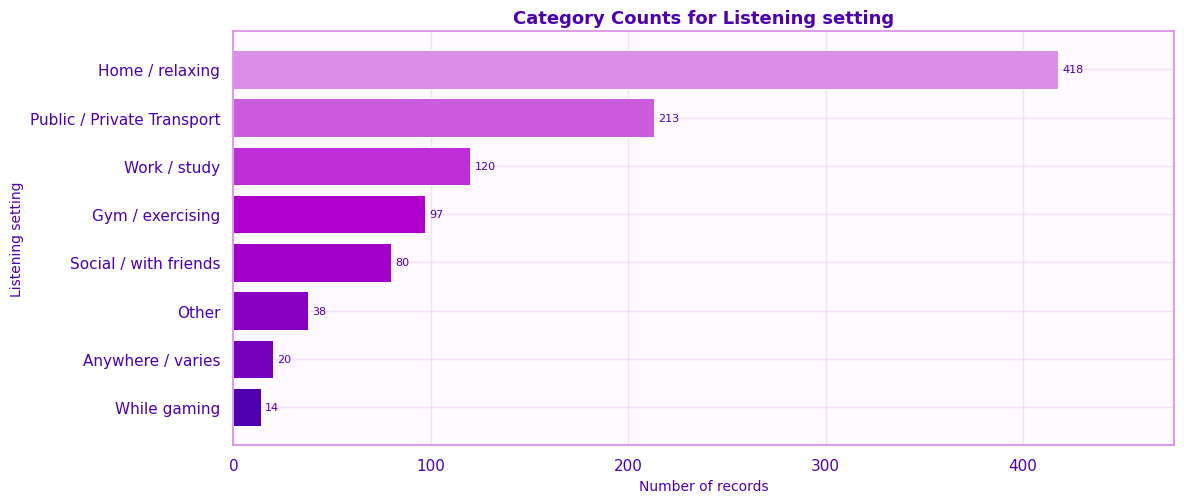

Saved: /content/plots/univ_06_listening_setting_bar.png
Observation: The highest count is Home / relaxing (n=418); the lowest count is While gaming (n=14). This chart shows raw counts only, raw category counts.


In [30]:
# Feature: Listening setting — sorted raw-count bar chart. It ranks the categories by record count without converting counts to shares.
# OBSERVATION: Home / relaxing leads (418 records, 41.8%), followed by Public / Private Transport (213
#     records, 21.3%).
# INTERPRETATION: While gaming is the least common setting (14 records, 1.4); Social / with friends accounts for
#     80 records (8.0%). The axis shows raw counts, not percentages.
fig, observation = plot_count_bar(clean_df, "listening_setting")
save_and_show(fig, "univ_06_listening_setting_bar.png")
print("Observation:", observation)

<a id="u07"></a>

### Univariate 07 — Instrumentalist

Instrumentalist indicates whether a respondent plays a musical instrument.

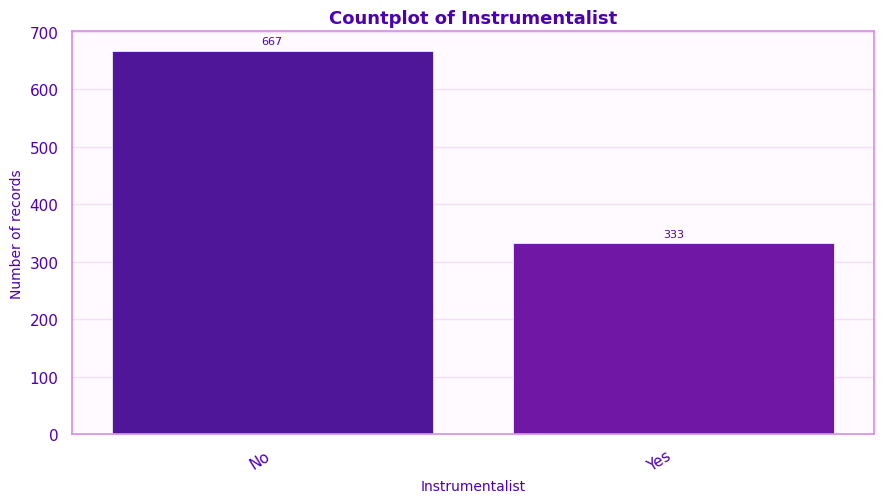

Saved: /content/plots/univ_07_instrumentalist.png
Observation: Instrumentalist has 2 observed categories. Most common: No (n=667); least common: Yes (n=333). Counts reflect the number of records in each category.


In [31]:
# Feature: Instrumentalist — countplot. It shows the number of records in each category; the most frequent category is printed below the chart.
# OBSERVATION: No is reported by 667 respondents (66.7%), compared with 333 (33.3%) who selected Yes.
# INTERPRETATION: The groups are not equal in size (about two-thirds No and one-third Yes), which matters when
#     interpreting comparisons with other variables. Read bar height as the number of records.
fig, observation = plot_countplot(clean_df, "instrumentalist")
save_and_show(fig, "univ_07_instrumentalist.png")
print("Observation:", observation)

#### Instrumentalist — sorted count bar chart

This second view ranks categories by **raw number of records** so common and uncommon categories are easy to spot. It displays raw category counts.

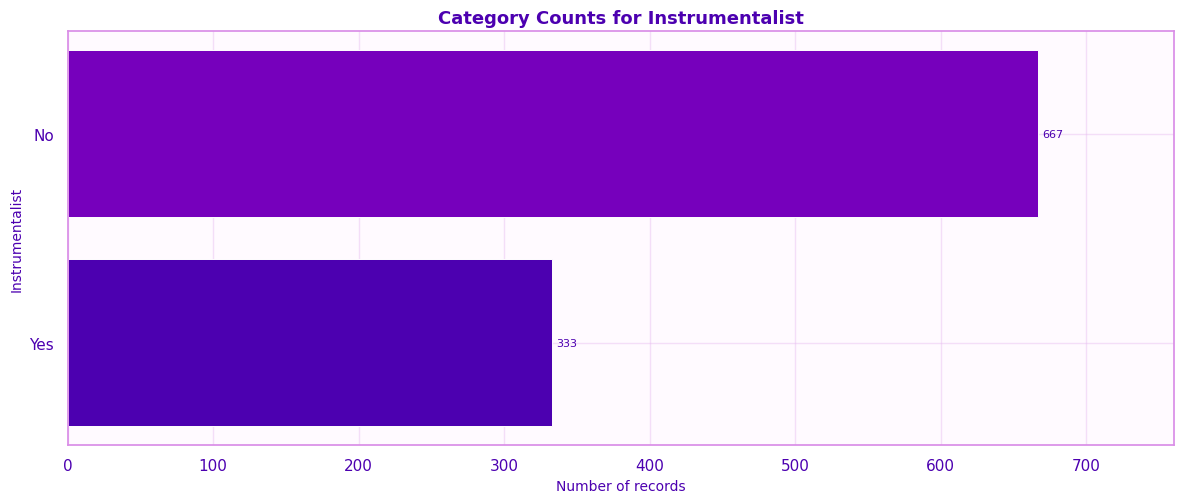

Saved: /content/plots/univ_07_instrumentalist_bar.png
Observation: The highest count is No (n=667); the lowest count is Yes (n=333). This chart shows raw counts only, raw category counts.


In [32]:
# Feature: Instrumentalist — sorted raw-count bar chart. It ranks the categories by record count without converting counts to shares.
# OBSERVATION: No is reported by 667 respondents (66.7%), compared with 333 (33.3%) who selected Yes.
# INTERPRETATION: The groups are not equal in size (about two-thirds No and one-third Yes), which matters when
#     interpreting comparisons with other variables. The axis shows raw counts, not percentages.
fig, observation = plot_count_bar(clean_df, "instrumentalist")
save_and_show(fig, "univ_07_instrumentalist_bar.png")
print("Observation:", observation)

<a id="u08"></a>

### Univariate 08 — Composer

Composer indicates whether a respondent creates or composes music.

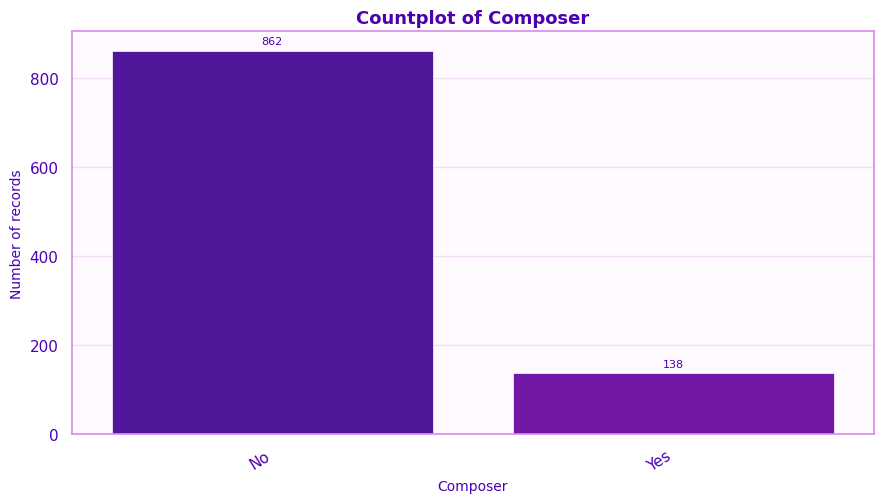

Saved: /content/plots/univ_08_composer.png
Observation: Composer has 2 observed categories. Most common: No (n=862); least common: Yes (n=138). Counts reflect the number of records in each category.


In [33]:
# Feature: Composer — countplot. It shows the number of records in each category; the most frequent category is printed below the chart.
# OBSERVATION: No dominates with 862 records (86.2); only 138 respondents (13.8%) report composing music.
# INTERPRETATION: The Composer=Yes group is comparatively small, so relationship plots involving composers
#     should be interpreted with group size in mind. Read bar height as the number of records.
fig, observation = plot_countplot(clean_df, "composer")
save_and_show(fig, "univ_08_composer.png")
print("Observation:", observation)

#### Composer — sorted count bar chart

This second view ranks categories by **raw number of records** so common and uncommon categories are easy to spot. It displays raw category counts.

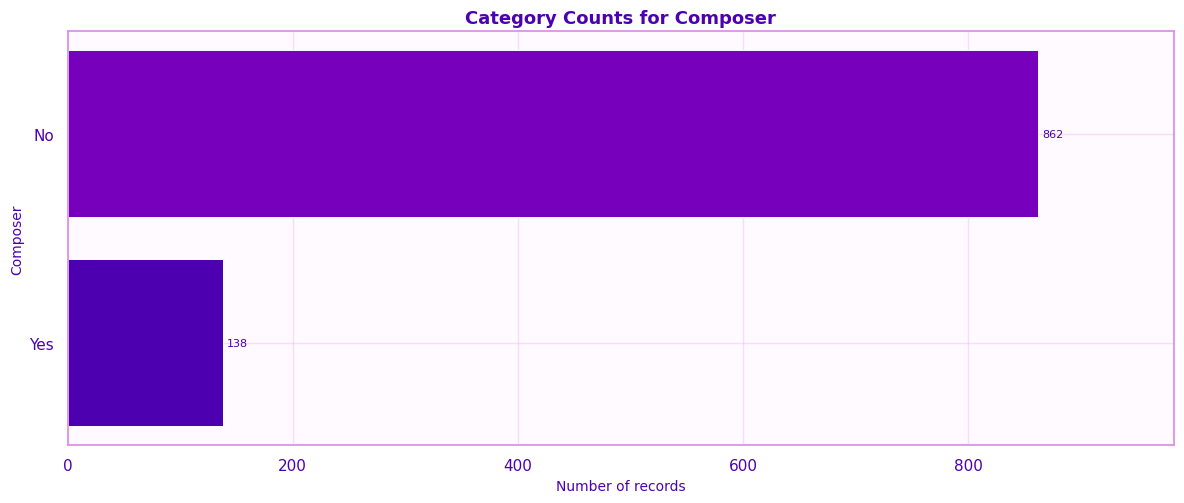

Saved: /content/plots/univ_08_composer_bar.png
Observation: The highest count is No (n=862); the lowest count is Yes (n=138). This chart shows raw counts only, raw category counts.


In [34]:
# Feature: Composer — sorted raw-count bar chart. It ranks the categories by record count without converting counts to shares.
# OBSERVATION: No dominates with 862 records (86.2); only 138 respondents (13.8%) report composing music.
# INTERPRETATION: The Composer=Yes group is comparatively small, so relationship plots involving composers
#     should be interpreted with group size in mind. The axis shows raw counts, not percentages.
fig, observation = plot_count_bar(clean_df, "composer")
save_and_show(fig, "univ_08_composer_bar.png")
print("Observation:", observation)

<a id="u09"></a>

### Univariate 09 — Exploratory

Exploratory indicates whether a respondent actively explores music beyond familiar choices.

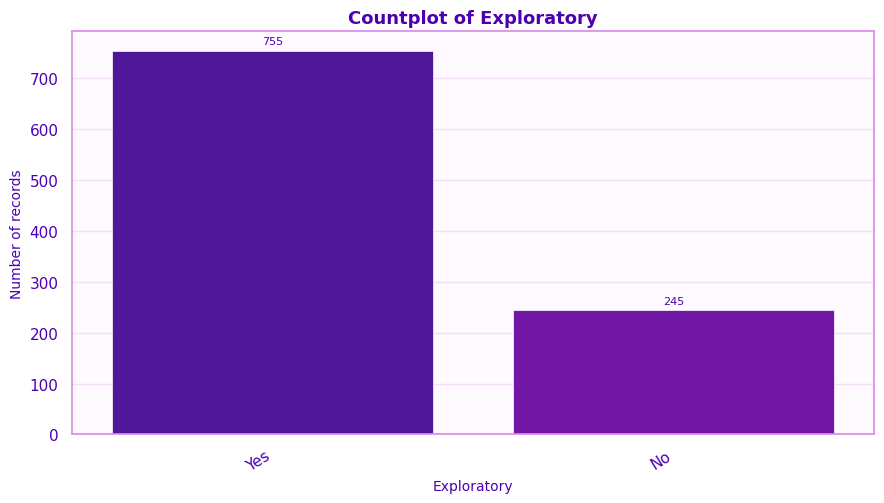

Saved: /content/plots/univ_09_exploratory.png
Observation: Exploratory has 2 observed categories. Most common: Yes (n=755); least common: No (n=245). Counts reflect the number of records in each category.


In [35]:
# Feature: Exploratory — countplot. It shows the number of records in each category; the most frequent category is printed below the chart.
# OBSERVATION: Exploratory=Yes is common (755 records, 75.5), while No represents 245 records (24.5%).
# INTERPRETATION: The substantial imbalance means raw counts in cross-tabulations can be driven partly by the
#     larger Yes group. Read bar height as the number of records.
fig, observation = plot_countplot(clean_df, "exploratory")
save_and_show(fig, "univ_09_exploratory.png")
print("Observation:", observation)

#### Exploratory — sorted count bar chart

This second view ranks categories by **raw number of records** so common and uncommon categories are easy to spot. It displays raw category counts.

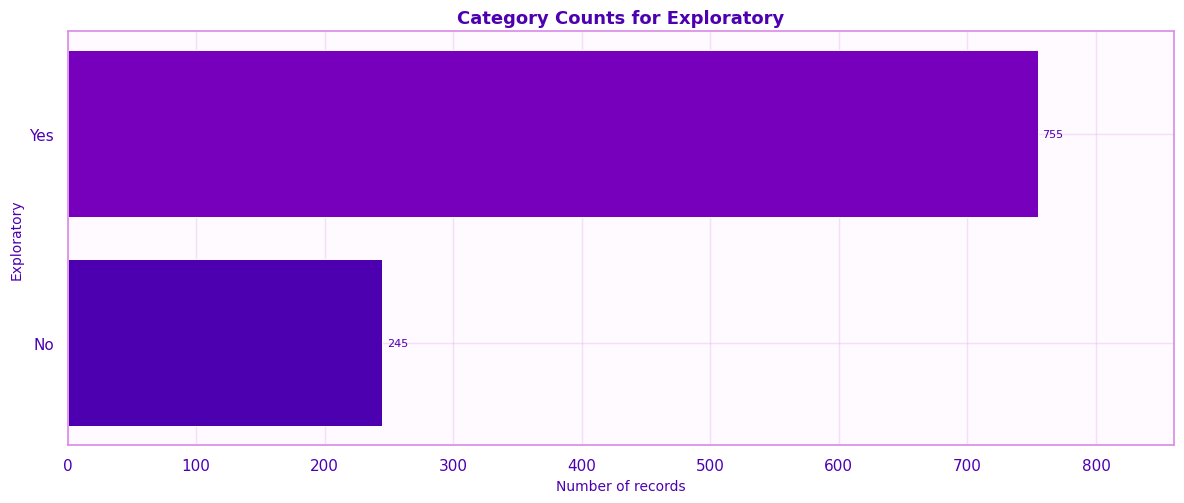

Saved: /content/plots/univ_09_exploratory_bar.png
Observation: The highest count is Yes (n=755); the lowest count is No (n=245). This chart shows raw counts only, raw category counts.


In [36]:
# Feature: Exploratory — sorted raw-count bar chart. It ranks the categories by record count without converting counts to shares.
# OBSERVATION: Exploratory=Yes is common (755 records, 75.5), while No represents 245 records (24.5%).
# INTERPRETATION: The substantial imbalance means raw counts in cross-tabulations can be driven partly by the
#     larger Yes group. The axis shows raw counts, not percentages.
fig, observation = plot_count_bar(clean_df, "exploratory")
save_and_show(fig, "univ_09_exploratory_bar.png")
print("Observation:", observation)

<a id="u10"></a>

### Univariate 10 — Foreign languages

Foreign languages records whether respondents report listening to or engaging with music in foreign languages, as represented in the dataset.

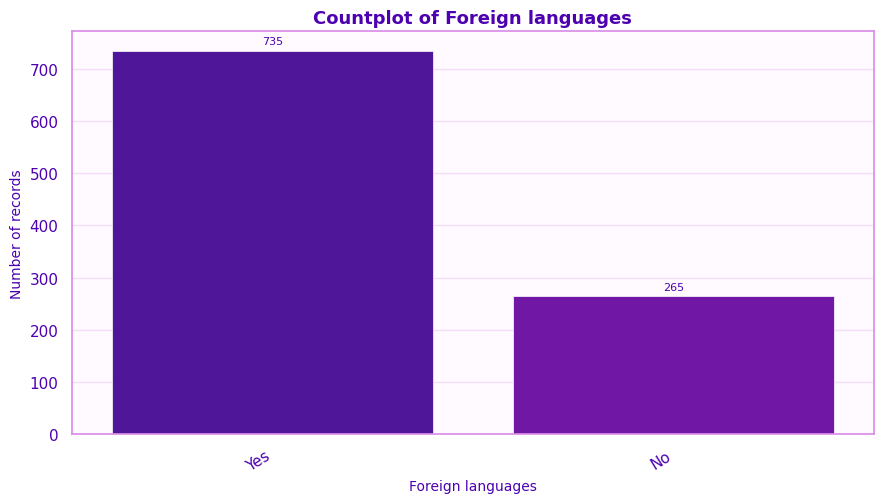

Saved: /content/plots/univ_10_foreign_languages.png
Observation: Foreign languages has 2 observed categories. Most common: Yes (n=735); least common: No (n=265). Counts reflect the number of records in each category.


In [37]:
# Feature: Foreign languages — countplot. It shows the number of records in each category; the most frequent category is printed below the chart.
# OBSERVATION: Foreign languages=Yes appears in 735 records (73.5%), versus 265 No records (26.5%).
# INTERPRETATION: Because this variable was modified to align with other behavior variables, the high Yes share
#     should be described as a property of this engineered dataset. Read bar height as the
#     number of records.
fig, observation = plot_countplot(clean_df, "foreign_languages")
save_and_show(fig, "univ_10_foreign_languages.png")
print("Observation:", observation)

#### Foreign languages — sorted count bar chart

This second view ranks categories by **raw number of records** so common and uncommon categories are easy to spot. It displays raw category counts.

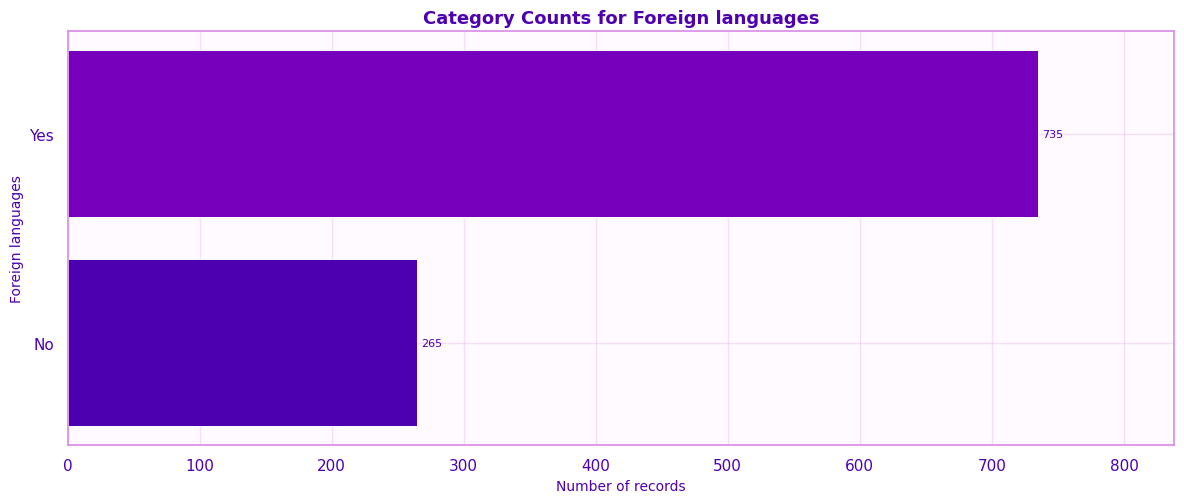

Saved: /content/plots/univ_10_foreign_languages_bar.png
Observation: The highest count is Yes (n=735); the lowest count is No (n=265). This chart shows raw counts only, raw category counts.


In [38]:
# Feature: Foreign languages — sorted raw-count bar chart. It ranks the categories by record count without converting counts to shares.
# OBSERVATION: Foreign languages=Yes appears in 735 records (73.5%), versus 265 No records (26.5%).
# INTERPRETATION: Because this variable was modified to align with other behavior variables, the high Yes share
#     should be described as a property of this engineered dataset. The axis shows raw counts,
#     not percentages.
fig, observation = plot_count_bar(clean_df, "foreign_languages")
save_and_show(fig, "univ_10_foreign_languages_bar.png")
print("Observation:", observation)

<a id="u11"></a>

### Univariate 11 — Music effects

Music effects is the reported outcome category: Improve, No effect, or Worsen.

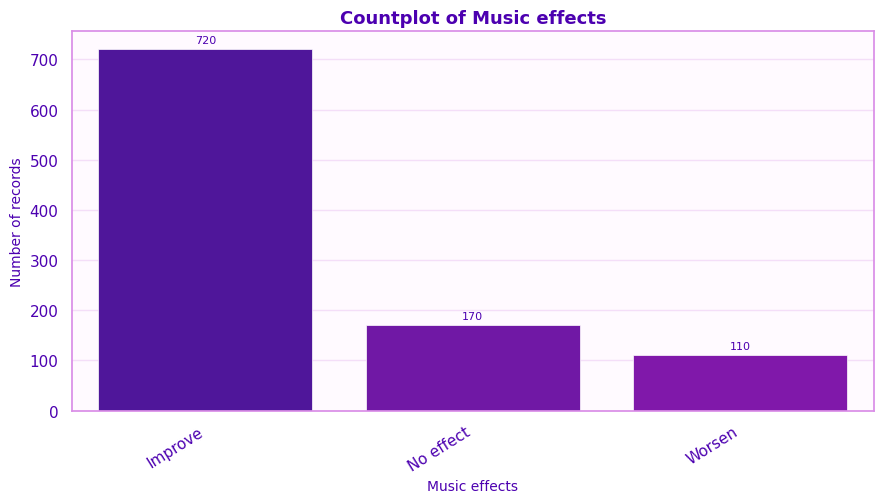

Saved: /content/plots/univ_11_music_effects.png
Observation: Music effects has 3 observed categories. Most common: Improve (n=720); least common: Worsen (n=110). Counts reflect the number of records in each category.


In [39]:
# Feature: Music effects — countplot. It shows the number of records in each category; the most frequent category is printed below the chart.
# OBSERVATION: Improve is the majority response (720 records, 72.0%); No effect has 170, and Worsen has 110.
# INTERPRETATION: The target is imbalanced toward Improve, so later comparisons should report within-group
#     percentages as well as raw counts. Read bar height as the number of records.
fig, observation = plot_countplot(clean_df, "music_effects")
save_and_show(fig, "univ_11_music_effects.png")
print("Observation:", observation)

#### Music effects — sorted count bar chart

This second view ranks categories by **raw number of records** so common and uncommon categories are easy to spot. It displays raw category counts.

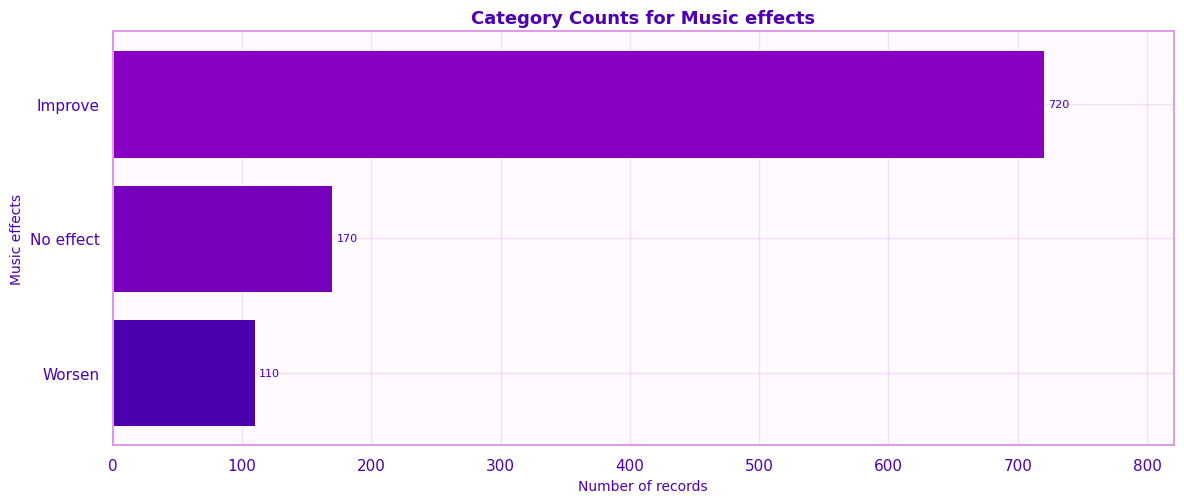

Saved: /content/plots/univ_11_music_effects_bar.png
Observation: The highest count is Improve (n=720); the lowest count is Worsen (n=110). This chart shows raw counts only, raw category counts.


In [40]:
# Feature: Music effects — sorted raw-count bar chart. It ranks the categories by record count without converting counts to shares.
# OBSERVATION: Improve is the majority response (720 records, 72.0%); No effect has 170, and Worsen has 110.
# INTERPRETATION: The target is imbalanced toward Improve, so later comparisons should report within-group
#     percentages as well as raw counts. The axis shows raw counts, not percentages.
fig, observation = plot_count_bar(clean_df, "music_effects")
save_and_show(fig, "univ_11_music_effects_bar.png")
print("Observation:", observation)

<a id="u12"></a>

### Univariate 12 — Mental disorder

Mental disorder is a mental-health-related label in this engineered dataset. Treat it as simulated or derived where applicable, not as a verified diagnosis.

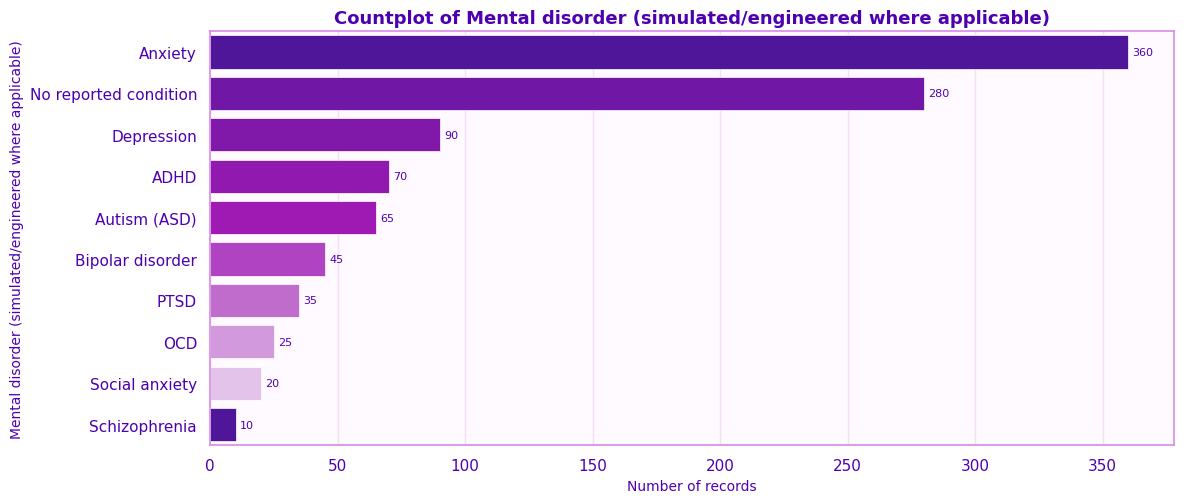

Saved: /content/plots/univ_12_mental_disorder.png
Observation: Mental disorder (simulated/engineered where applicable) has 10 observed categories. Most common: Anxiety (n=360); least common: Schizophrenia (n=10). Counts reflect the number of records in each category.


In [41]:
# Feature: Mental disorder — countplot. It shows the number of records in each category; the most frequent category is printed below the chart.
# OBSERVATION: Anxiety is the largest label group (360 records, 36.0%), followed by No reported condition
#     (280, 28.0%).
# INTERPRETATION: Schizophrenia has only 10 records (1.0%), so its apparent patterns are highly uncertain;
#     labels are engineered/simulated, not clinical evidence. Read bar height as the number of
#     records.
fig, observation = plot_countplot(clean_df, "mental_disorder")
save_and_show(fig, "univ_12_mental_disorder.png")
print("Observation:", observation)

#### Mental disorder — sorted count bar chart

This second view ranks categories by **raw number of records** so common and uncommon categories are easy to spot. It displays raw category counts.

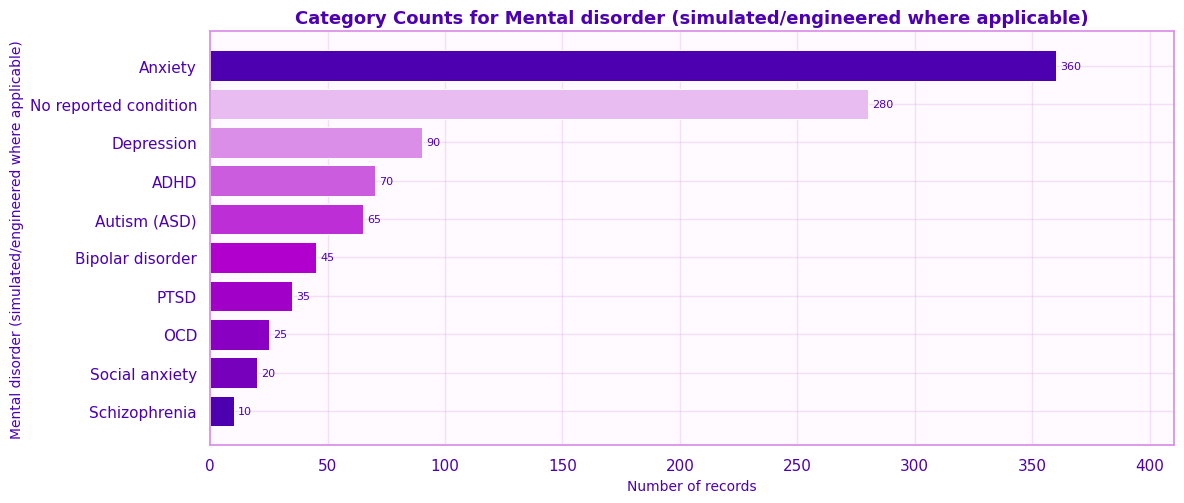

Saved: /content/plots/univ_12_mental_disorder_bar.png
Observation: The highest count is Anxiety (n=360); the lowest count is Schizophrenia (n=10). This chart shows raw counts only, raw category counts.


In [42]:
# Feature: Mental disorder — sorted raw-count bar chart. It ranks the categories by record count without converting counts to shares.
# OBSERVATION: Anxiety is the largest label group (360 records, 36.0%), followed by No reported condition
#     (280, 28.0%).
# INTERPRETATION: Schizophrenia has only 10 records (1.0%), so its apparent patterns are highly uncertain;
#     labels are engineered/simulated, not clinical evidence. The axis shows raw counts, not
#     percentages.
fig, observation = plot_count_bar(clean_df, "mental_disorder")
save_and_show(fig, "univ_12_mental_disorder_bar.png")
print("Observation:", observation)

<a id="u13"></a>

### Univariate 13 — Music genre

Music genre records respondents' preferred genre, such as Pop, Rock, Classical, EDM, or other listed categories.

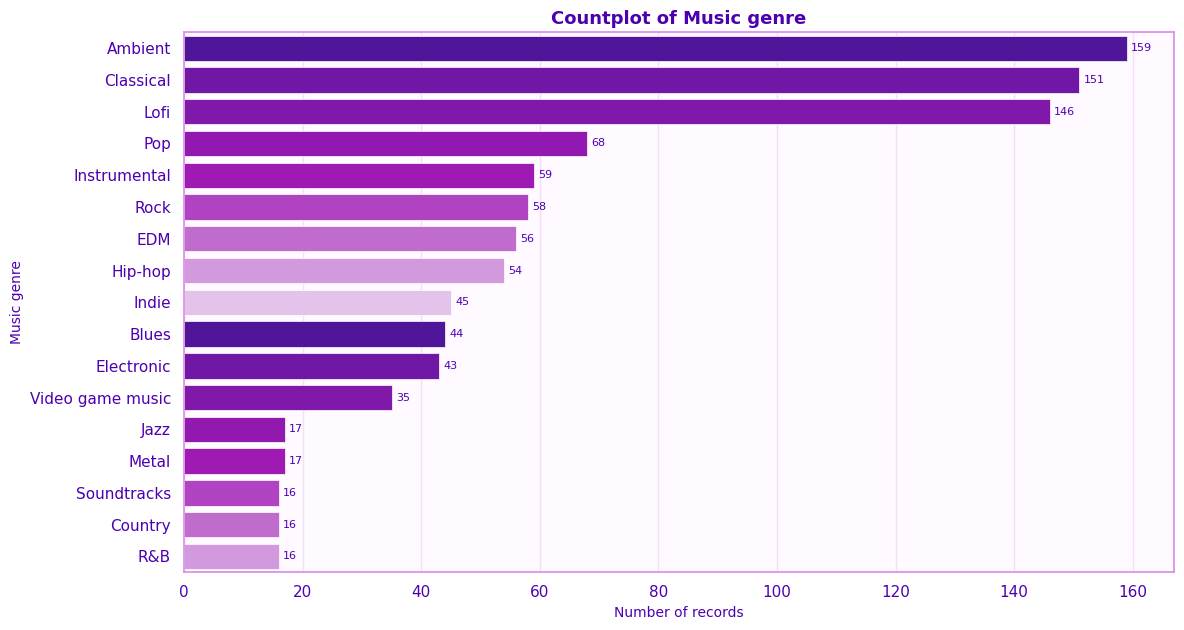

Saved: /content/plots/univ_13_music_genre.png
Observation: Music genre has 17 observed categories. Most common: Ambient (n=159); least common: R&B (n=16). Counts reflect the number of records in each category.


In [43]:
# Feature: Music genre — countplot. It shows the number of records in each category; the most frequent category is printed below the chart.
# OBSERVATION: The three most common genres are Ambient 159 (15.9%), Classical 151 (15.1%), Lofi 146 (14.6%),
#     together 456 records (45.6%).
# INTERPRETATION: Least-common categories include Soundtracks, Country, R&B (16 records each). Many genres have
#     small groups, so compare within-genre proportions carefully. Read bar height as the number
#     of records.
fig, observation = plot_countplot(clean_df, "music_genre")
save_and_show(fig, "univ_13_music_genre.png")
print("Observation:", observation)

#### Music genre — sorted count bar chart

This second view ranks categories by **raw number of records** so common and uncommon categories are easy to spot. It displays raw category counts.

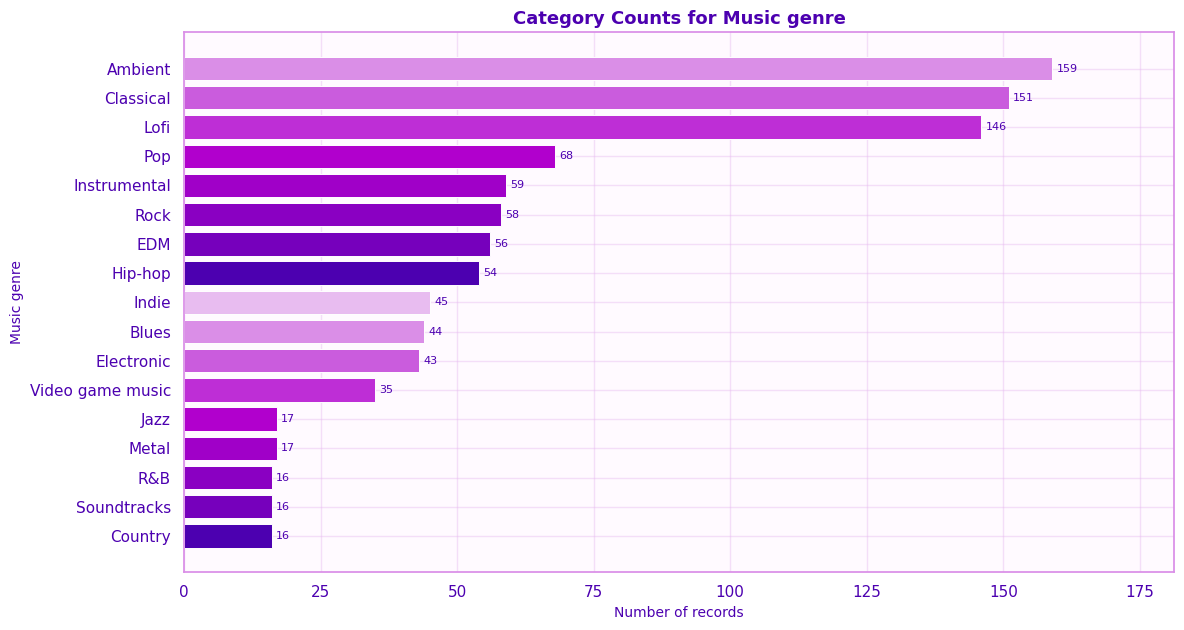

Saved: /content/plots/univ_13_music_genre_bar.png
Observation: The highest count is Ambient (n=159); the lowest count is Country (n=16). This chart shows raw counts only, raw category counts.


In [44]:
# Feature: Music genre — sorted raw-count bar chart. It ranks the categories by record count without converting counts to shares.
# OBSERVATION: The ranked bar confirms that the three most common genres are Ambient 159 (15.9%), Classical
#     151 (15.1%), Lofi 146 (14.6%), together 456 records (45.6%).
# INTERPRETATION: Least-common categories include Soundtracks, Country, R&B (16 records each). Many genres have
#     small groups, so compare within-genre proportions carefully. The axis shows raw counts,
#     not percentages.
fig, observation = plot_count_bar(clean_df, "music_genre")
save_and_show(fig, "univ_13_music_genre_bar.png")
print("Observation:", observation)

<a id="u14"></a>

### Univariate 14 — Vibe reason

Vibe reason describes why respondents choose music, such as relaxation, rhythm, nostalgia, or emotional connection.

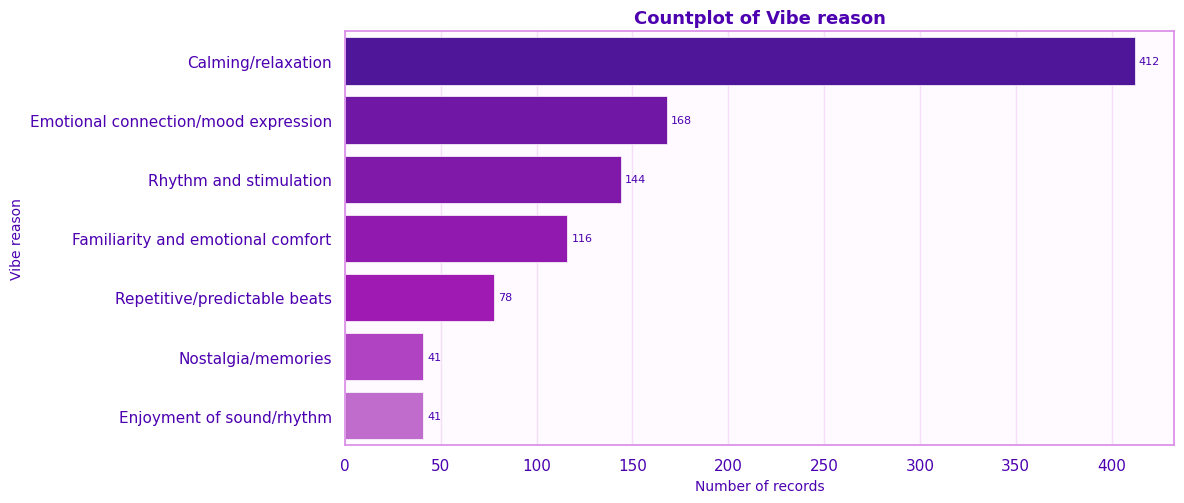

Saved: /content/plots/univ_14_vibe_reason.png
Observation: Vibe reason has 7 observed categories. Most common: Calming/relaxation (n=412); least common: Enjoyment of sound/rhythm (n=41). Counts reflect the number of records in each category.


In [45]:
# Feature: Vibe reason — countplot. It shows the number of records in each category; the most frequent category is printed below the chart.
# OBSERVATION: The leading reasons are Calming/relaxation 412 (41.2%), Emotional connection/mood expression
#     168 (16.8%), Rhythm and stimulation 144 (14.4%); Calming/relaxation alone accounts for 412
#     records (41.2%).
# INTERPRETATION: Enjoyment of sound/rhythm is least common (41 records, 4.1%). This is a concentration in the
#     current dataset, not necessarily in all music listeners. Read bar height as the number of
#     records.
fig, observation = plot_countplot(clean_df, "vibe_reason")
save_and_show(fig, "univ_14_vibe_reason.png")
print("Observation:", observation)

#### Vibe reason — sorted count bar chart

This second view ranks categories by **raw number of records** so common and uncommon categories are easy to spot. It displays raw category counts.

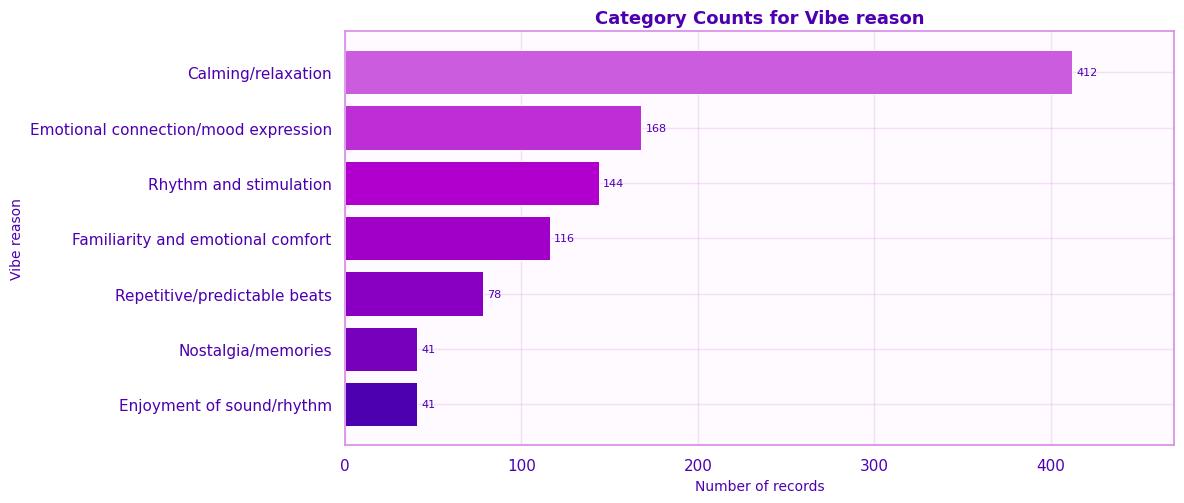

Saved: /content/plots/univ_14_vibe_reason_bar.png
Observation: The highest count is Calming/relaxation (n=412); the lowest count is Enjoyment of sound/rhythm (n=41). This chart shows raw counts only, raw category counts.


In [46]:
# Feature: Vibe reason — sorted raw-count bar chart. It ranks the categories by record count without converting counts to shares.
# OBSERVATION: The leading reasons are Calming/relaxation 412 (41.2%), Emotional connection/mood expression
#     168 (16.8%), Rhythm and stimulation 144 (14.4%); Calming/relaxation alone accounts for 412
#     records (41.2%).
# INTERPRETATION: Enjoyment of sound/rhythm is least common (41 records, 4.1%). This is a concentration in the
#     current dataset, not necessarily in all music listeners. The axis shows raw counts, not
#     percentages.
fig, observation = plot_count_bar(clean_df, "vibe_reason")
save_and_show(fig, "univ_14_vibe_reason_bar.png")
print("Observation:", observation)

<a id="u15"></a>

### Univariate 15 — Repeats songs often

Repeats songs often indicates whether respondents commonly listen to the same songs repeatedly.

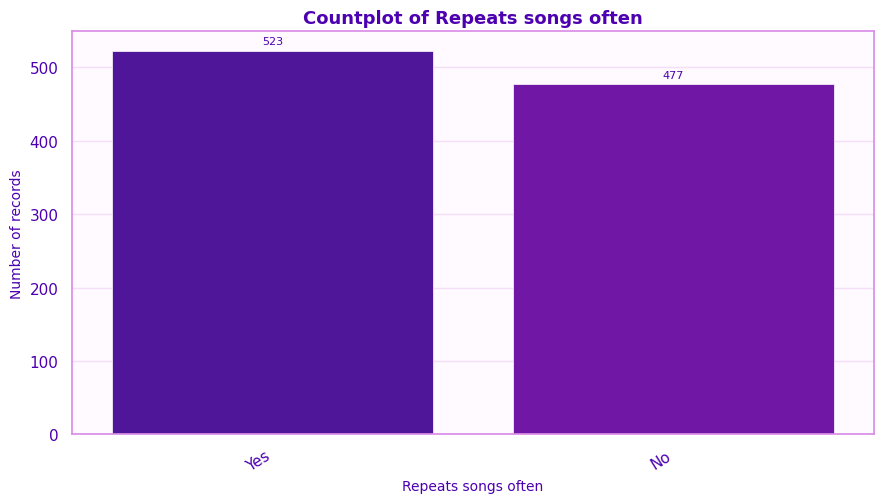

Saved: /content/plots/univ_15_repeats_songs_often.png
Observation: Repeats songs often has 2 observed categories. Most common: Yes (n=523); least common: No (n=477). Counts reflect the number of records in each category.


In [47]:
# Feature: Repeats songs often — countplot. It shows the number of records in each category; the most frequent category is printed below the chart.
# OBSERVATION: Responses are fairly balanced: Yes=523 (52.3%) and No=477 (47.7%).
# INTERPRETATION: Because neither category overwhelms the other, later comparisons of repetition are less
#     dominated by a single overall class. Read bar height as the number of records.
fig, observation = plot_countplot(clean_df, "repeats_songs_often")
save_and_show(fig, "univ_15_repeats_songs_often.png")
print("Observation:", observation)

#### Repeats songs often — sorted count bar chart

This second view ranks categories by **raw number of records** so common and uncommon categories are easy to spot. It displays raw category counts.

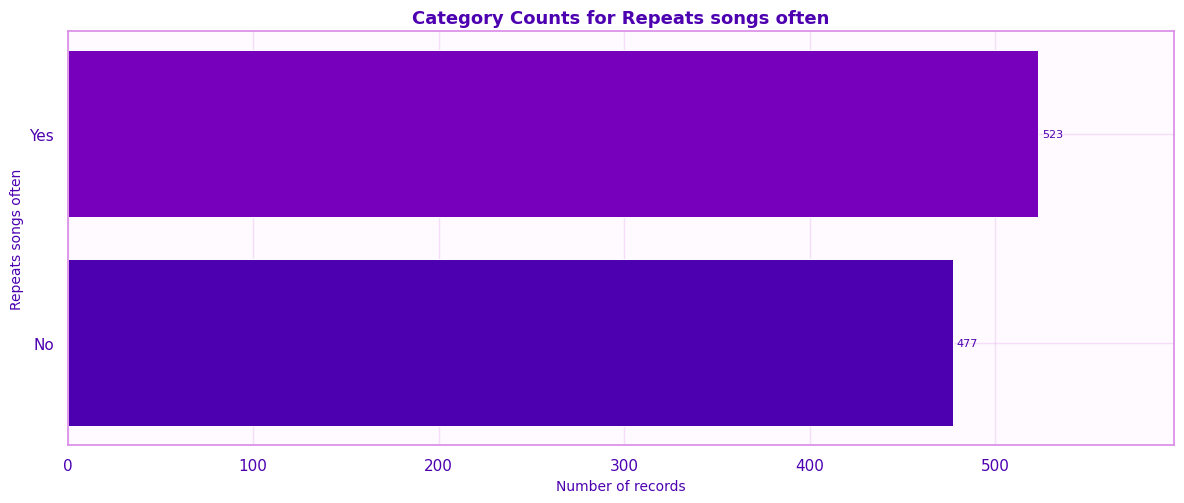

Saved: /content/plots/univ_15_repeats_songs_often_bar.png
Observation: The highest count is Yes (n=523); the lowest count is No (n=477). This chart shows raw counts only, raw category counts.


In [48]:
# Feature: Repeats songs often — sorted raw-count bar chart. It ranks the categories by record count without converting counts to shares.
# OBSERVATION: Responses are fairly balanced: Yes=523 (52.3%) and No=477 (47.7%).
# INTERPRETATION: Because neither category overwhelms the other, later comparisons of repetition are less
#     dominated by a single overall class. The axis shows raw counts, not percentages.
fig, observation = plot_count_bar(clean_df, "repeats_songs_often")
save_and_show(fig, "univ_15_repeats_songs_often_bar.png")
print("Observation:", observation)

<a id="eda-bivariate"></a>

## 5.2 Bivariate and multivariate analysis — relationships between variables

These plots compare two variables at a time. Numerical–numerical relationships use a scatterplot and a pairwise correlation heatmap; categorical–numerical relationships use boxplots; categorical–categorical relationships use grouped **count** bars and count heatmaps. Count-based charts show the number of records, so remember that group sizes can differ.

<a id="r01"></a>

### Relationship 01 — Age vs. hours per day

Age and daily listening duration are both numeric. The scatterplot displays individual records and a fitted linear trend; the heatmap reports Pearson correlation for the same pair.

#### Bivar Age Vs Hours Per Day

scatterplot with regression trend. Examine direction, strength, spread, and possible outliers.

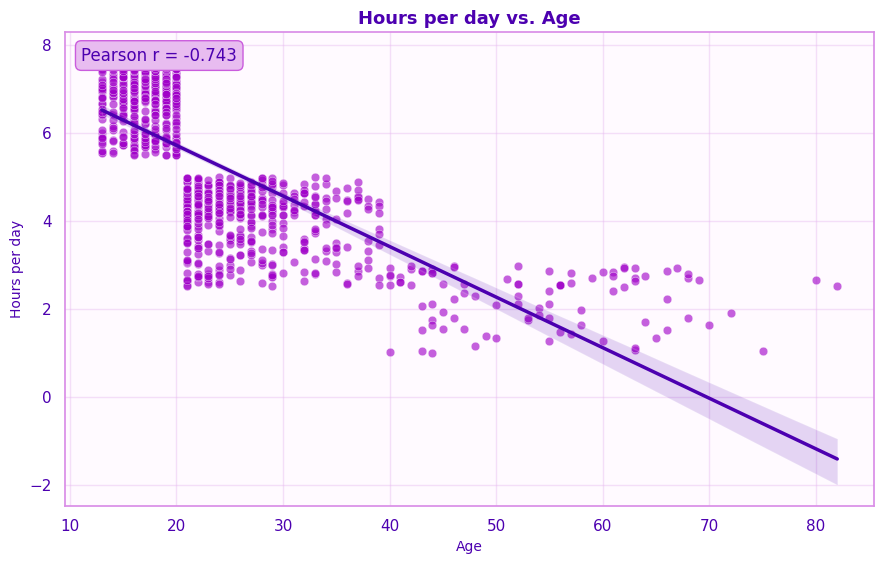

Saved: /content/plots/bivar_age_vs_hours_per_day.png
Observation: Age and hours per day have a strong negative linear association (Pearson r=-0.743, n=1,000). Correlation does not imply causation.


In [49]:
# Relationship: Age vs. hours per day — scatterplot with regression trend. Examine direction, strength, spread, and possible outliers.
# OBSERVATION: Age and listening hours show a strong negative Pearson correlation (r=-0.743; n=1000): older
#     records generally sit lower on the hours axis.
# INTERPRETATION: Respondents aged 13–20 average 6.83 hours/day (median 6.92), compared with mean 2.26 hours for
#     ages 40–49 and 2.25 for ages 50–70. This strong pattern is built into the engineered
#     dataset and should not be generalized as a real-world causal effect.
fig, observation = plot_numeric_pair_scatter(clean_df, "age", "hours_per_day")
save_and_show(fig, "bivar_age_vs_hours_per_day.png")
print("Observation:", observation)

#### Bivar Age Vs Hours Per Day Correlation Heatmap

pairwise correlation heatmap. The annotated value quantifies the linear relationship.

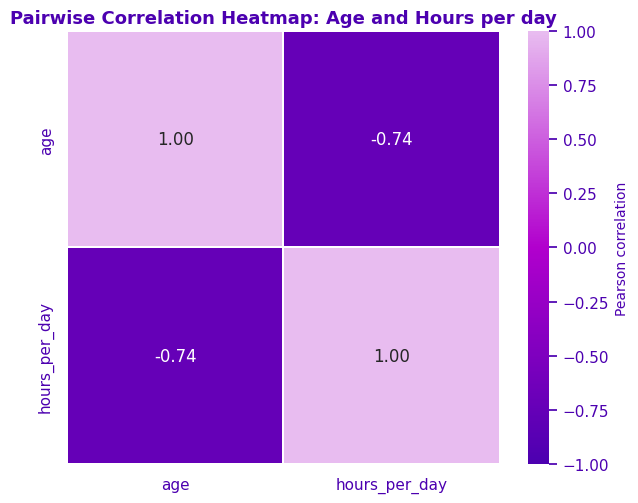

Saved: /content/plots/bivar_age_vs_hours_per_day_correlation_heatmap.png
Observation: Pearson correlation between age and hours per day is r=-0.743 based on 1,000 complete pairs. This measures linear association, not causation.


In [50]:
# Relationship: Age vs. hours per day — pairwise correlation heatmap. The annotated value quantifies the linear relationship.
# OBSERVATION: The age–hours cell is the strongest numeric association (r=-0.743); age–BPM is only r=0.032,
#     and hours–BPM is r=-0.001.
# INTERPRETATION: The heatmap therefore highlights an age/listening-duration relationship, while BPM has almost
#     no linear correlation with either variable in this dataset.
#
fig, observation = plot_pair_corr_heatmap(clean_df, "age", "hours_per_day")
save_and_show(fig, "bivar_age_vs_hours_per_day_correlation_heatmap.png")
print("Observation:", observation)

<a id="r02"></a>

### Relationship 02 — Age vs. listening time

Listening time is categorical and age is numeric. Comparing age boxplots across listening-time groups shows differences in medians, spread, and potential outliers.

#### Bivar Age Vs Listening Time

categorical–numeric boxplot. Compare age medians and ranges across time-of-day groups.

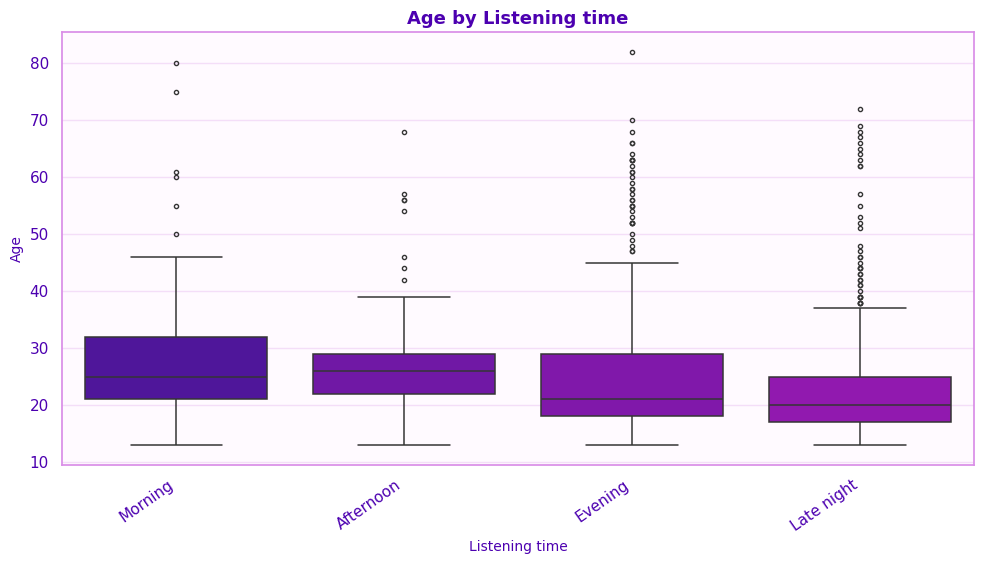

Saved: /content/plots/bivar_age_vs_listening_time.png
Observation: Median age ranges from Late night (20.00) to Afternoon (26.00) across 4 listening time groups. Compare spread and group sizes as well as medians.


In [51]:
# Relationship: Age by listening time — categorical–numeric boxplot. Compare age medians and ranges across time-of-day groups.
# OBSERVATION: Median ages differ by time: Late night=20 (n=501), Evening=21 (n=339), Morning=25,
#     Afternoon=26.
# INTERPRETATION: Late-night listening is both the largest group (501 records) and younger by median age than
#     afternoon listening (median 26). This age/time pattern was engineered for the project and
#     is descriptive, not causal.
fig, observation = plot_numeric_by_category_box(clean_df, "listening_time", "age")
save_and_show(fig, "bivar_age_vs_listening_time.png")
print("Observation:", observation)

<a id="r03"></a>

### Relationship 03 — Age vs. listening setting

Listening setting is categorical and age is numeric. Boxplots help compare age distributions across home, study, exercise, transport, social, gaming, and other settings.

#### Bivar Age Vs Listening Setting

categorical–numeric boxplot. Compare the median age, spread, and outliers for each setting.

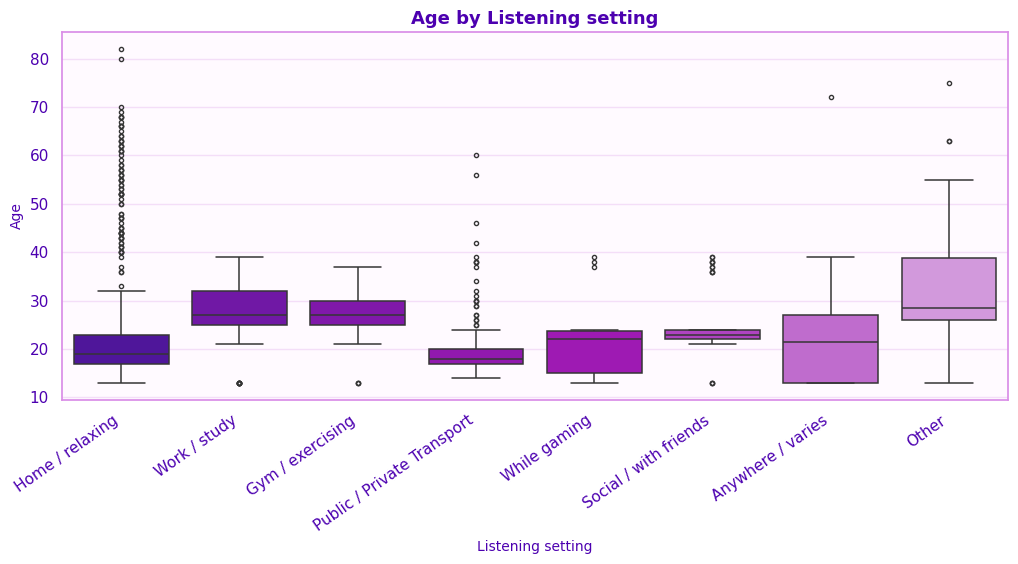

Saved: /content/plots/bivar_age_vs_listening_setting.png
Observation: Median age ranges from Public / Private Transport (18.00) to Other (28.50) across 8 listening setting groups. Compare spread and group sizes as well as medians.


In [52]:
# Relationship: Age by listening setting — categorical–numeric boxplot. Compare the median age, spread, and outliers for each setting.
# OBSERVATION: Median age is lowest for Public / Private Transport (18; n=213) and Home / relaxing (19;
#     n=418).
# INTERPRETATION: Other has the highest median age (28.5) but only 38 records, so its estimate is less stable.
#     The setting-by-age pattern is part of the engineered dataset design.
fig, observation = plot_numeric_by_category_box(clean_df, "listening_setting", "age")
save_and_show(fig, "bivar_age_vs_listening_setting.png")
print("Observation:", observation)

<a id="r04"></a>

### Relationship 04 — Instrumentalist vs. foreign languages

Both variables are categorical. The grouped bars compare raw counts of foreign-language responses by instrumentalist status; the heatmap displays every combination.

#### Bivar Instrumentalist Vs Foreign Languages

grouped count bar chart. Compare raw counts across Yes/No groups.

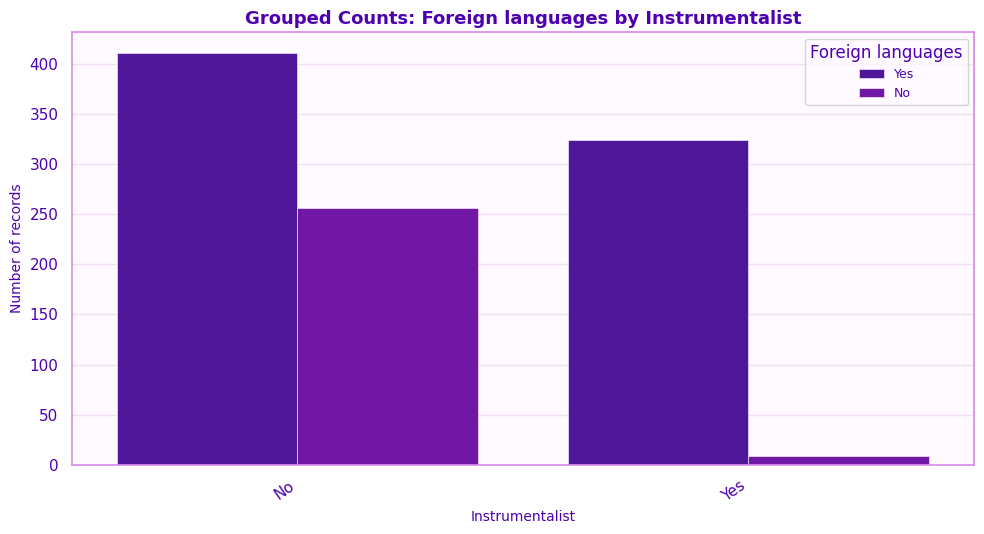

Saved: /content/plots/bivar_instrumentalist_vs_foreign_languages.png
Observation: Most frequent pair: No × Yes (n=411). Raw counts are influenced by the number of records in each group.


In [53]:
# Relationship: Instrumentalist vs. foreign languages — grouped count bar chart. Compare raw counts across Yes/No groups.
# OBSERVATION: Among instrumentalists, 324/333 (97.3%) are marked Foreign languages=Yes; among non-
#     instrumentalists, 411/667 (61.6%) are Yes.
# INTERPRETATION: The Yes-rate gap is 35.7 percentage points. This association is very strong in the engineered
#     file and should be reported as a constructed dataset pattern, not evidence that playing
#     instruments predicts language ability.
fig, observation = plot_category_pair_bar(clean_df, "instrumentalist", "foreign_languages")
save_and_show(fig, "bivar_instrumentalist_vs_foreign_languages.png")
print("Observation:", observation)

#### Bivar Instrumentalist Vs Foreign Languages Heatmap

count heatmap. Darker cells represent more records in that category combination.

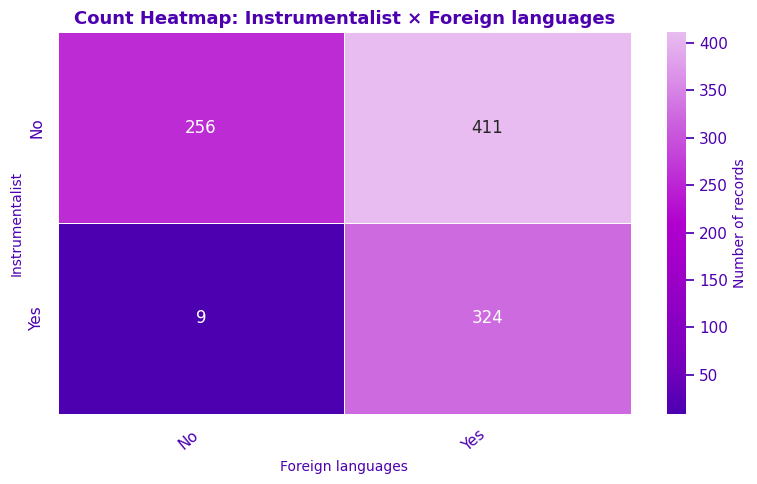

Saved: /content/plots/bivar_instrumentalist_vs_foreign_languages_heatmap.png
Observation: Highest-count cell: No × Yes (n=411). The heatmap shows raw counts for every category pair; group size matters when interpreting differences.


In [54]:
# Relationship: Instrumentalist vs. foreign languages — count heatmap. Darker cells represent more records in that category combination.
# OBSERVATION: Among instrumentalists, 324/333 (97.3%) are marked Foreign languages=Yes; among non-
#     instrumentalists, 411/667 (61.6%) are Yes.
# INTERPRETATION: The Yes-rate gap is 35.7 percentage points. This association is very strong in the engineered
#     file and should be reported as a constructed dataset pattern, not evidence that playing
#     instruments predicts language ability.
fig, observation = plot_category_pair_heatmap(clean_df, "instrumentalist", "foreign_languages")
save_and_show(fig, "bivar_instrumentalist_vs_foreign_languages_heatmap.png")
print("Observation:", observation)

<a id="r05"></a>

### Relationship 05 — Exploratory vs. foreign languages

Both variables are categorical. Compare the number of foreign-language responses for exploratory and non-exploratory listeners.

#### Bivar Exploratory Vs Foreign Languages

grouped count bar chart. Compare category counts across exploratory status.

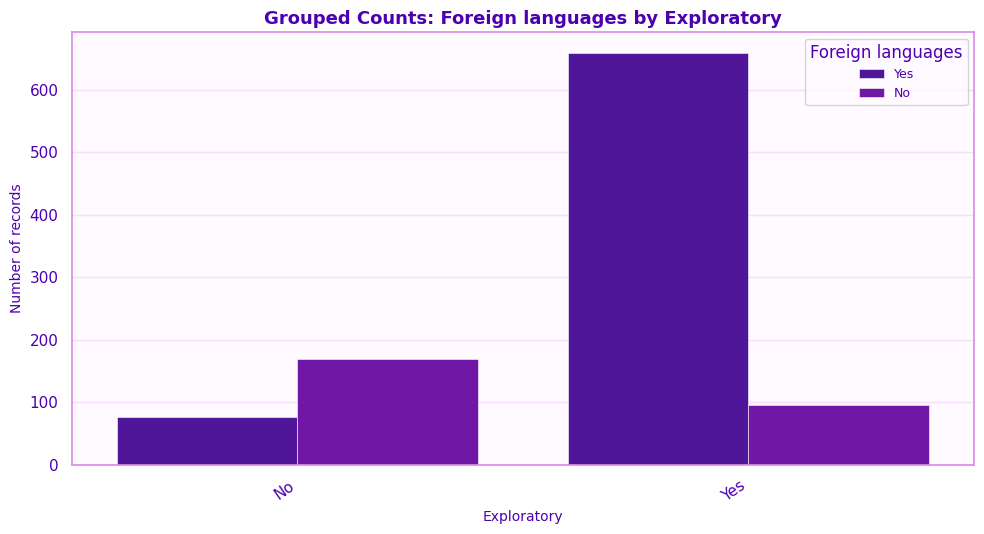

Saved: /content/plots/bivar_exploratory_vs_foreign_languages.png
Observation: Most frequent pair: Yes × Yes (n=659). Raw counts are influenced by the number of records in each group.


In [55]:
# Relationship: Exploratory vs. foreign languages — grouped count bar chart. Compare category counts across exploratory status.
# OBSERVATION: Exploratory=Yes has 659/755 Foreign languages=Yes (87.3%), while Exploratory=No has 76/245
#     (31.0%).
# INTERPRETATION: The 56.3 percentage-point gap is prominent in both the grouped bars and heatmap. These
#     variables were deliberately aligned during editing, so avoid treating the relationship as
#     an independent discovery.
fig, observation = plot_category_pair_bar(clean_df, "exploratory", "foreign_languages")
save_and_show(fig, "bivar_exploratory_vs_foreign_languages.png")
print("Observation:", observation)

#### Bivar Exploratory Vs Foreign Languages Heatmap

count heatmap. The cell values show the number of records for each combination.

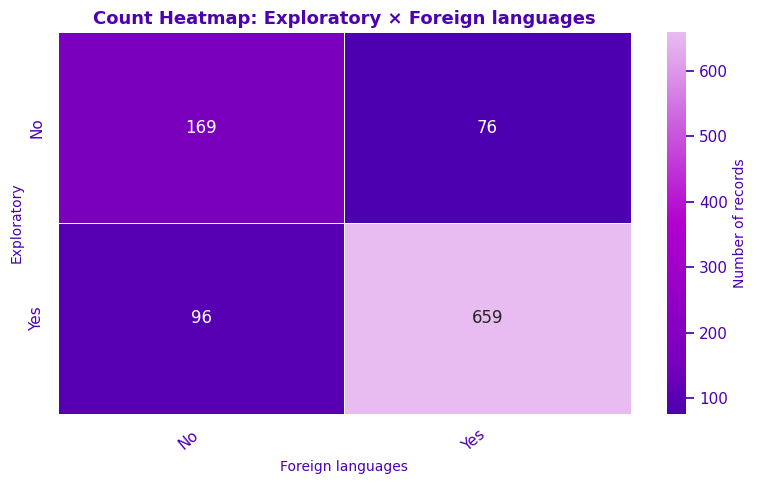

Saved: /content/plots/bivar_exploratory_vs_foreign_languages_heatmap.png
Observation: Highest-count cell: Yes × Yes (n=659). The heatmap shows raw counts for every category pair; group size matters when interpreting differences.


In [56]:
# Relationship: Exploratory vs. foreign languages — count heatmap. The cell values show the number of records for each combination.
# OBSERVATION: Exploratory=Yes has 659/755 Foreign languages=Yes (87.3%), while Exploratory=No has 76/245
#     (31.0%).
# INTERPRETATION: The 56.3 percentage-point gap is prominent in both the grouped bars and heatmap. These
#     variables were deliberately aligned during editing, so avoid treating the relationship as
#     an independent discovery.
fig, observation = plot_category_pair_heatmap(clean_df, "exploratory", "foreign_languages")
save_and_show(fig, "bivar_exploratory_vs_foreign_languages_heatmap.png")
print("Observation:", observation)

<a id="r06"></a>

### Relationship 06 — Composer vs. listening setting

Both variables are categorical. These plots compare the settings reported by composers and non-composers.

#### Bivar Composer Vs Listening Setting

grouped count bar chart. This view helps compare reported settings by composer status.

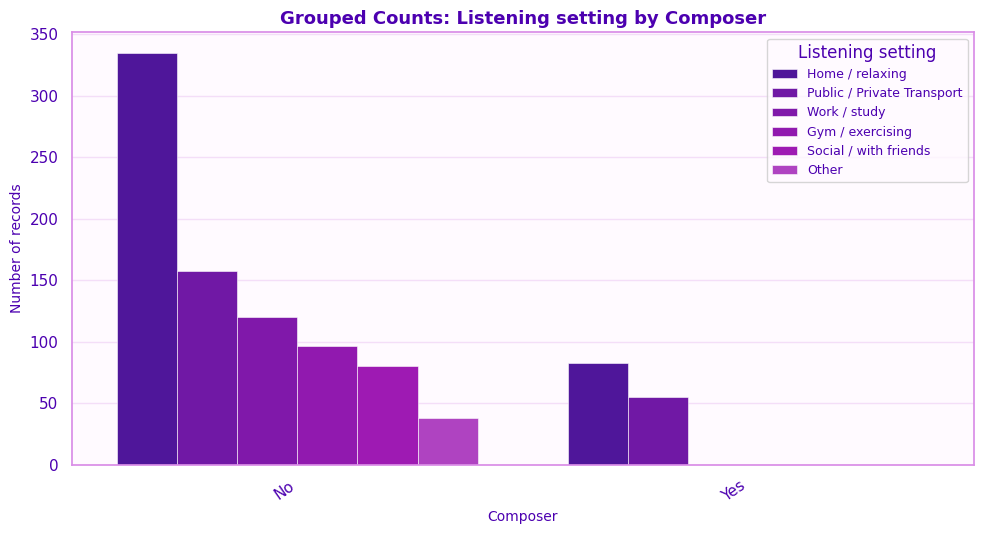

Saved: /content/plots/bivar_composer_vs_listening_setting.png
Observation: Most frequent pair: No × Home / relaxing (n=335). Raw counts are influenced by the number of records in each group. The grouped bar chart displays the 6 most common listening setting categories for readability; the heatmap retains all observed categories.


In [57]:
# Relationship: Composer vs. listening setting — grouped count bar chart. This view helps compare reported settings by composer status.
# OBSERVATION: Among composers, 83/138 (60.1%) report Home / relaxing and 55/138 (39.9%) Public / Private
#     Transport; no composers fall in the other six settings.
# INTERPRETATION: Non-composers are more distributed: 38.9% Home / relaxing and 18.3% transport, with records
#     also in work/study, gym and social settings. The near-exclusive composer pattern was
#     engineered.
fig, observation = plot_category_pair_bar(clean_df, "composer", "listening_setting")
save_and_show(fig, "bivar_composer_vs_listening_setting.png")
print("Observation:", observation)

#### Bivar Composer Vs Listening Setting Heatmap

count heatmap. All observed setting/status combinations are shown.

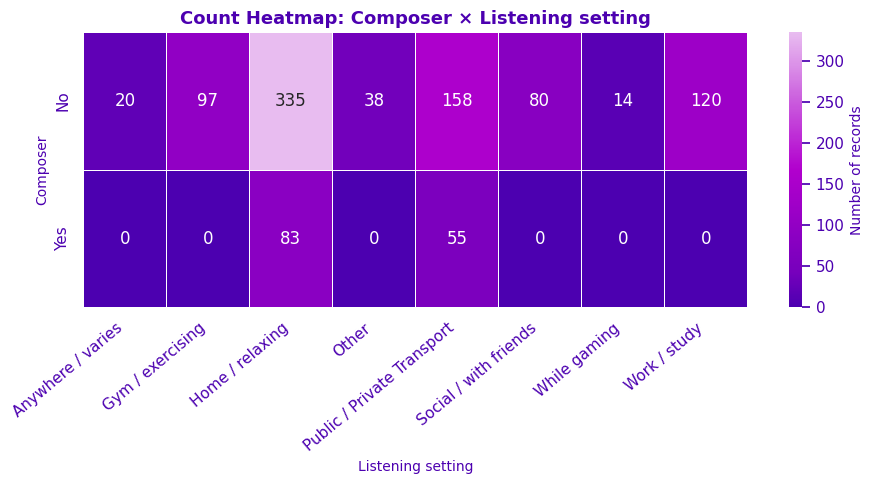

Saved: /content/plots/bivar_composer_vs_listening_setting_heatmap.png
Observation: Highest-count cell: No × Home / relaxing (n=335). The heatmap shows raw counts for every category pair; group size matters when interpreting differences.


In [58]:
# Relationship: Composer vs. listening setting — count heatmap. All observed setting/status combinations are shown.
# OBSERVATION: Among composers, 83/138 (60.1%) report Home / relaxing and 55/138 (39.9%) Public / Private
#     Transport; no composers fall in the other six settings.
# INTERPRETATION: Non-composers are more distributed: 38.9% Home / relaxing and 18.3% transport, with records
#     also in work/study, gym and social settings.

fig, observation = plot_category_pair_heatmap(clean_df, "composer", "listening_setting")
save_and_show(fig, "bivar_composer_vs_listening_setting_heatmap.png")
print("Observation:", observation)

<a id="r07"></a>

### Relationship 07 — Instrumentalist vs. hours per day

Instrumentalist status is categorical and listening hours are numeric. The boxplot compares medians, spread, and potential extreme values by status.

#### Bivar Instrumentalist Vs Hours Per Day

categorical–numeric boxplot. Compare median listening duration and spread for Yes and No.

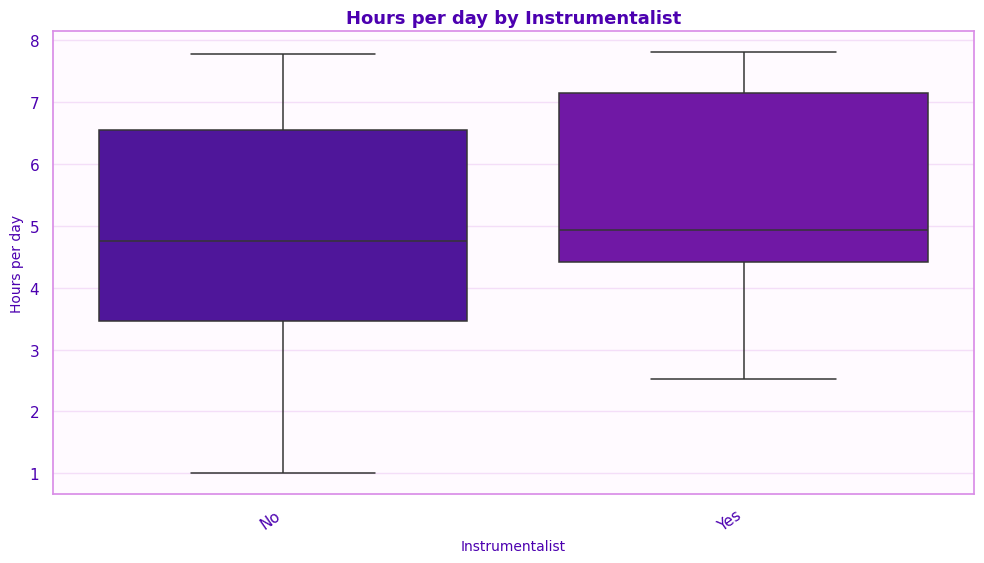

Saved: /content/plots/bivar_instrumentalist_vs_hours_per_day.png
Observation: Median hours per day ranges from No (4.75) to Yes (4.93) across 2 instrumentalist groups. Compare spread and group sizes as well as medians.


In [59]:
# Relationship: Instrumentalist vs. hours per day — categorical–numeric boxplot. Compare median listening duration and spread for Yes and No.
# OBSERVATION: Instrumentalists average 5.68 listening hours/day (median 4.93; n=333), versus 4.94 hours/day
#     (median 4.75; n=667) for non-instrumentalists.
# INTERPRETATION: The mean differs by 0.74 hours, but medians differ by only 0.18 hours and the observed ranges
#     overlap broadly. The plot suggests a modest descriptive difference, not proof that being
#     an instrumentalist causes longer listening.
fig, observation = plot_numeric_by_category_box(clean_df, "instrumentalist", "hours_per_day")
save_and_show(fig, "bivar_instrumentalist_vs_hours_per_day.png")
print("Observation:", observation)

<a id="r08"></a>

### Relationship 08 — Composer vs. listening time

Both variables are categorical. Compare counts across composer status and preferred listening time.

#### Bivar Composer Vs Listening Time

grouped count bar chart. Compare observed listening-time counts across composer status.

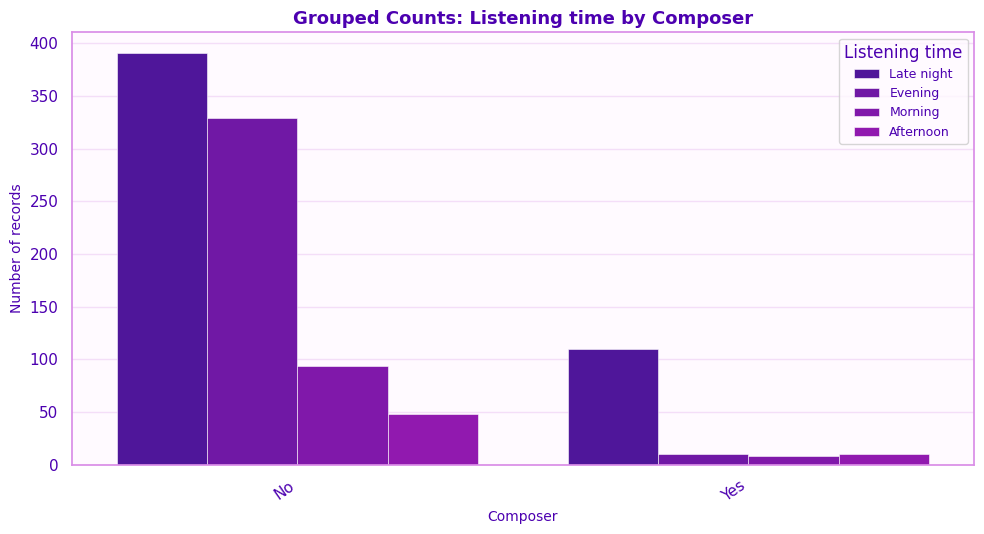

Saved: /content/plots/bivar_composer_vs_listening_time.png
Observation: Most frequent pair: No × Late night (n=391). Raw counts are influenced by the number of records in each group.


In [60]:
# Relationship: Composer vs. listening time — grouped count bar chart. Compare observed listening-time counts across composer status.
# OBSERVATION: Late night is reported by 110/138 composers (79.7%), compared with 391/862 non-composers
#     (45.4%).
# INTERPRETATION: Composers show a 34.3 percentage-point higher late-night share; Evening is the next large non-
#     composer group (38.2%).
fig, observation = plot_category_pair_bar(clean_df, "composer", "listening_time")
save_and_show(fig, "bivar_composer_vs_listening_time.png")
print("Observation:", observation)

#### Bivar Composer Vs Listening Time Heatmap

count heatmap. The cells show raw counts for all combinations.

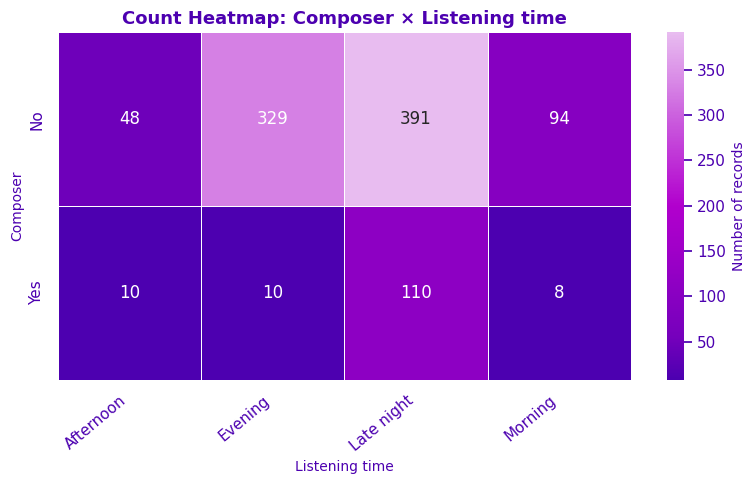

Saved: /content/plots/bivar_composer_vs_listening_time_heatmap.png
Observation: Highest-count cell: No × Late night (n=391). The heatmap shows raw counts for every category pair; group size matters when interpreting differences.


In [61]:
# Relationship: Composer vs. listening time — count heatmap. The cells show raw counts for all combinations.
# OBSERVATION: Late night is reported by 110/138 composers (79.7%), compared with 391/862 non-composers
#     (45.4%).
# INTERPRETATION: Composers show a 34.3 percentage-point higher late-night share; Evening is the next large non-
#     composer group (38.2%).
fig, observation = plot_category_pair_heatmap(clean_df, "composer", "listening_time")
save_and_show(fig, "bivar_composer_vs_listening_time_heatmap.png")
print("Observation:", observation)

<a id="r09"></a>

### Relationship 09 — Mental disorder vs. music genre

Both variables are categorical. These charts explore the structure of the working dataset's labels and reported genres. The mental-disorder field is simulated/engineered where applicable and does not support clinical conclusions.

#### Bivar Mental Disorder Vs Music Genre

grouped count bar chart. Compare raw counts; high-cardinality genres may be limited in this view for readability.

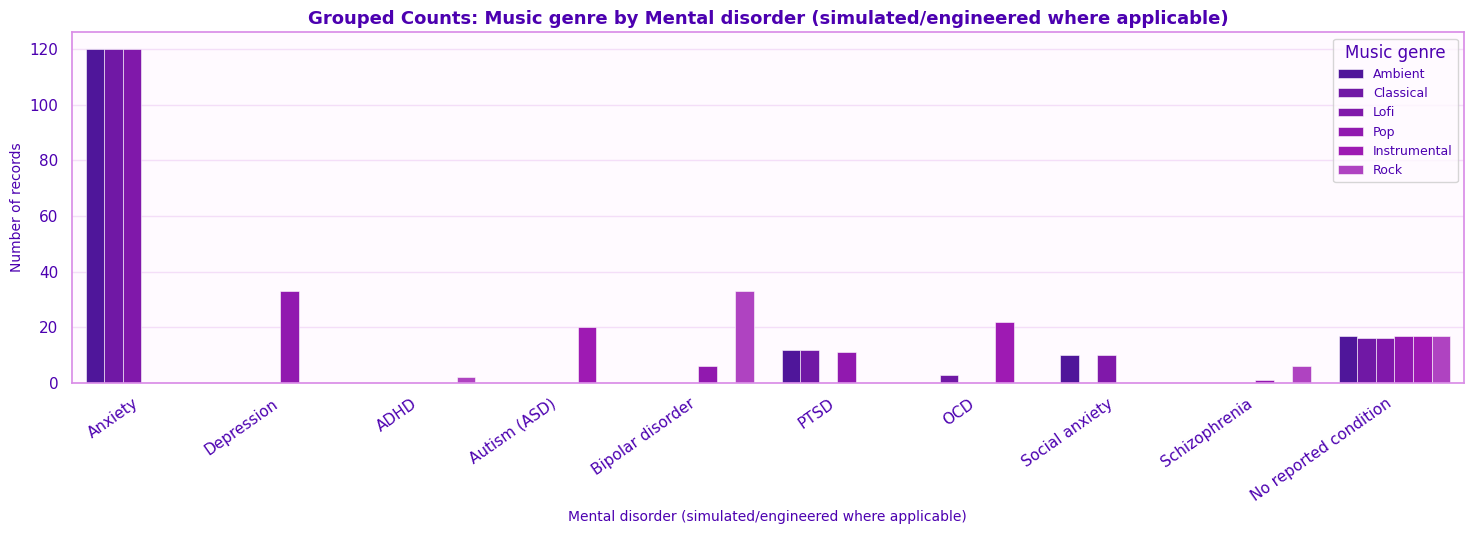

Saved: /content/plots/bivar_mental_disorder_vs_music_genre.png
Observation: Most frequent pair: Anxiety × Ambient (n=120). Raw counts are influenced by the number of records in each group. The grouped bar chart displays the 6 most common music genre categories for readability; the heatmap retains all observed categories.


In [62]:
# Relationship: Mental disorder vs. music genre — grouped count bar chart. Compare raw counts; high-cardinality genres may be limited in this view for readability.
# OBSERVATION: Anxiety has the largest row (n=360), split evenly across Ambient, Classical and Lofi (120
#     each; 33.3% each). ADHD is split between EDM and Hip-hop (34 each; 48.6% each).
# INTERPRETATION: Autism (ASD) is distributed across Electronic (26; 40.0%), Instrumental (20; 30.8%) and Video
#     game music (19; 29.2%); No reported condition is close to balanced across genres.
fig, observation = plot_category_pair_bar(clean_df, "mental_disorder", "music_genre")
save_and_show(fig, "bivar_mental_disorder_vs_music_genre.png")
print("Observation:", observation)

#### Bivar Mental Disorder Vs Music Genre Heatmap

count heatmap. All observed genre/label combinations remain visible.

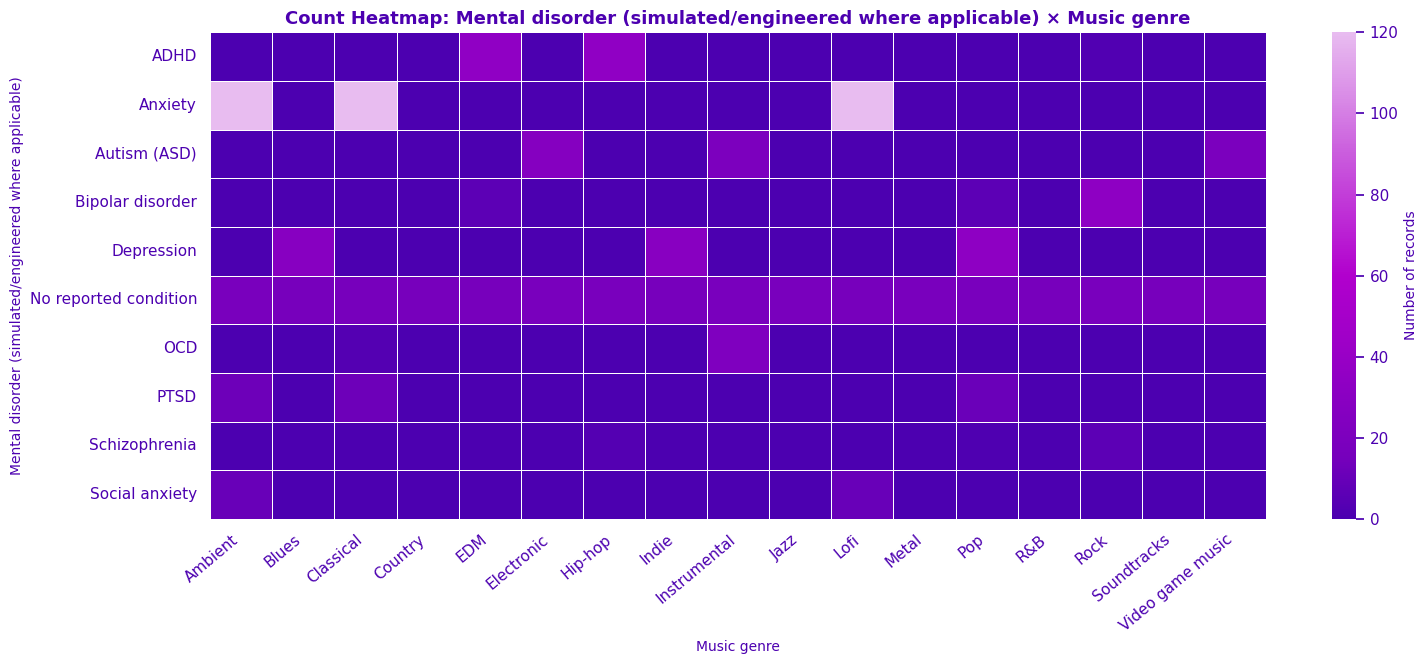

Saved: /content/plots/bivar_mental_disorder_vs_music_genre_heatmap.png
Observation: Highest-count cell: Anxiety × Ambient (n=120). The heatmap shows raw counts for every category pair; group size matters when interpreting differences.


In [63]:
# Relationship: Mental disorder vs. music genre — count heatmap. All observed genre/label combinations remain visible.
# OBSERVATION: Anxiety has the largest row (n=360), split evenly across Ambient, Classical and Lofi (120
#     each; 33.3% each). ADHD is split between EDM and Hip-hop (34 each; 48.6% each).
# INTERPRETATION: Autism (ASD) is distributed across Electronic (26; 40.0%), Instrumental (20; 30.8%) and Video
#     game music (19; 29.2%); No reported condition is close to balanced across genres.
fig, observation = plot_category_pair_heatmap(clean_df, "mental_disorder", "music_genre")
save_and_show(fig, "bivar_mental_disorder_vs_music_genre_heatmap.png")
print("Observation:", observation)

<a id="r10"></a>

### Relationship 10 — Mental disorder vs. vibe reason

Both variables are categorical. Compare raw counts for music-choice motivations across the mental-health-related labels; interpret this as an engineered-data pattern, not diagnosis-related evidence.

#### Bivar Mental Disorder Vs Vibe Reason

grouped count bar chart. Compare the count of each reason across labels.

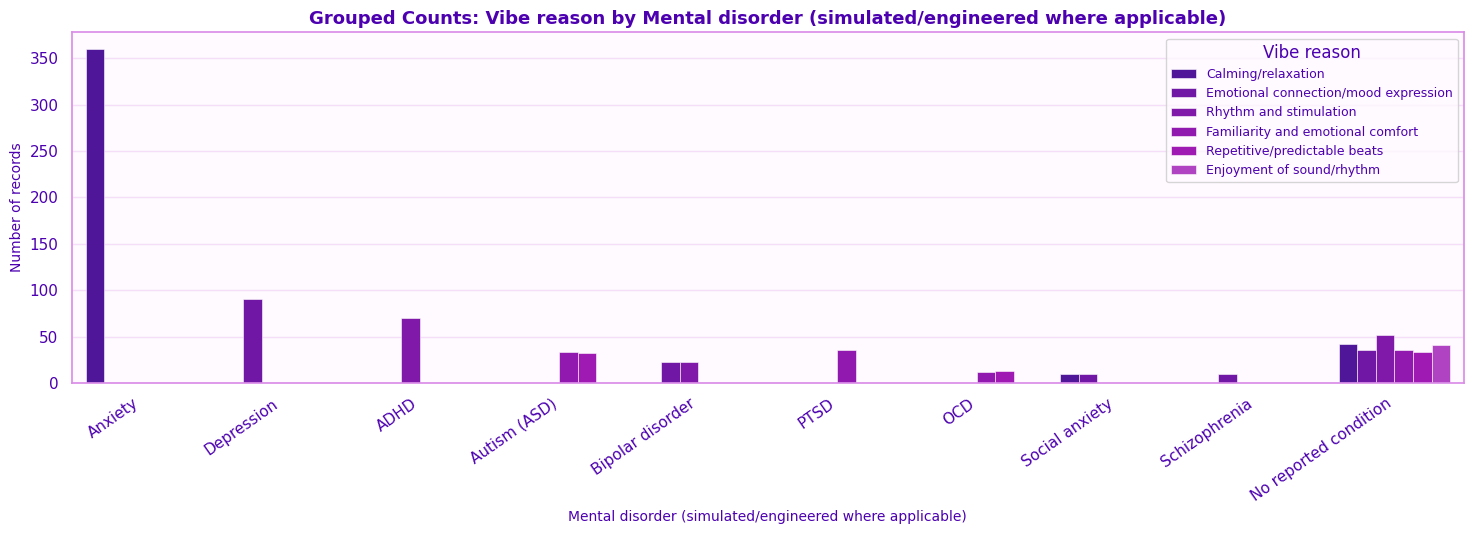

Saved: /content/plots/bivar_mental_disorder_vs_vibe_reason.png
Observation: Most frequent pair: Anxiety × Calming/relaxation (n=360). Raw counts are influenced by the number of records in each group. The grouped bar chart displays the 6 most common vibe reason categories for readability; the heatmap retains all observed categories.


In [64]:
# Relationship: Mental disorder vs. vibe reason — grouped count bar chart. Compare the count of each reason across labels.
# OBSERVATION: The designed mapping is visible: all Anxiety records (360/360) choose Calming/relaxation, all
#     Depression records (90/90) choose Emotional connection/mood expression, and all ADHD
#     records (70/70) choose Rhythm and stimulation.
# INTERPRETATION: Autism (ASD) is almost evenly split between Familiarity/comfort (33; 50.8%) and
#     Repetitive/predictable beats (32; 49.2%). This reflects engineered labels rather than a
#     clinical finding.
fig, observation = plot_category_pair_bar(clean_df, "mental_disorder", "vibe_reason")
save_and_show(fig, "bivar_mental_disorder_vs_vibe_reason.png")
print("Observation:", observation)

#### Bivar Mental Disorder Vs Vibe Reason Heatmap

count heatmap. The heatmap displays every label/reason pair.

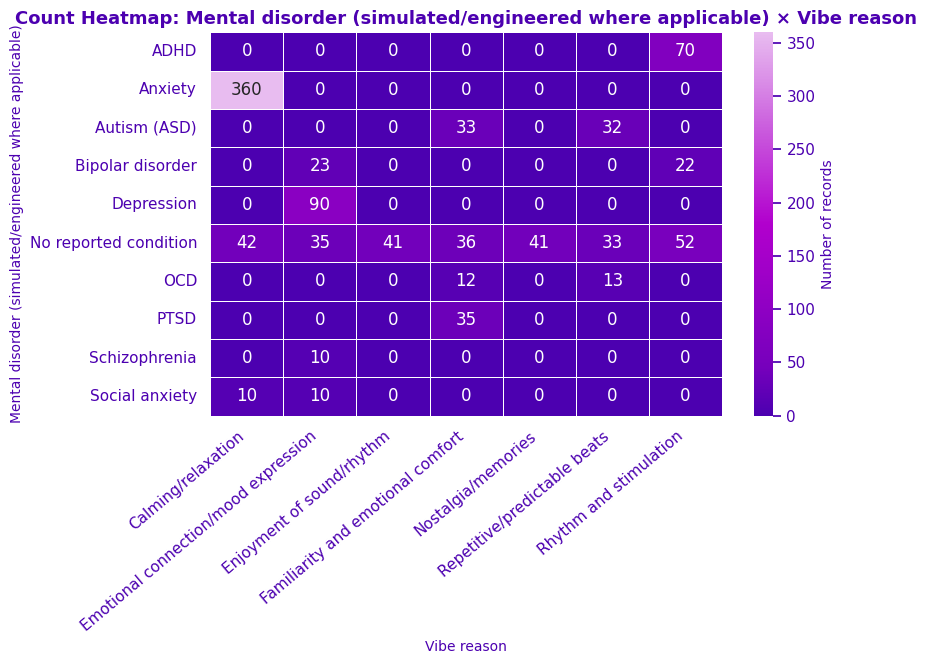

Saved: /content/plots/bivar_mental_disorder_vs_vibe_reason_heatmap.png
Observation: Highest-count cell: Anxiety × Calming/relaxation (n=360). The heatmap shows raw counts for every category pair; group size matters when interpreting differences.


In [65]:
# Relationship: Mental disorder vs. vibe reason — count heatmap. The heatmap displays every label/reason pair.
# OBSERVATION: The designed mapping is visible: all Anxiety records (360/360) choose Calming/relaxation, all
#     Depression records (90/90) choose Emotional connection/mood expression, and all ADHD
#     records (70/70) choose Rhythm and stimulation.
# INTERPRETATION: Autism (ASD) is almost evenly split between Familiarity/comfort (33; 50.8%) and
#     Repetitive/predictable beats (32; 49.2%).
fig, observation = plot_category_pair_heatmap(clean_df, "mental_disorder", "vibe_reason")
save_and_show(fig, "bivar_mental_disorder_vs_vibe_reason_heatmap.png")
print("Observation:", observation)

<a id="r11"></a>

### Relationship 11 — Mental disorder vs. repeats songs often

Both variables are categorical. Compare how many Yes/No repetition responses appear within each label, while remembering group sizes may differ.

#### Bivar Mental Disorder Vs Repeats Songs

grouped count bar chart. Compare the recorded Yes/No counts by label.

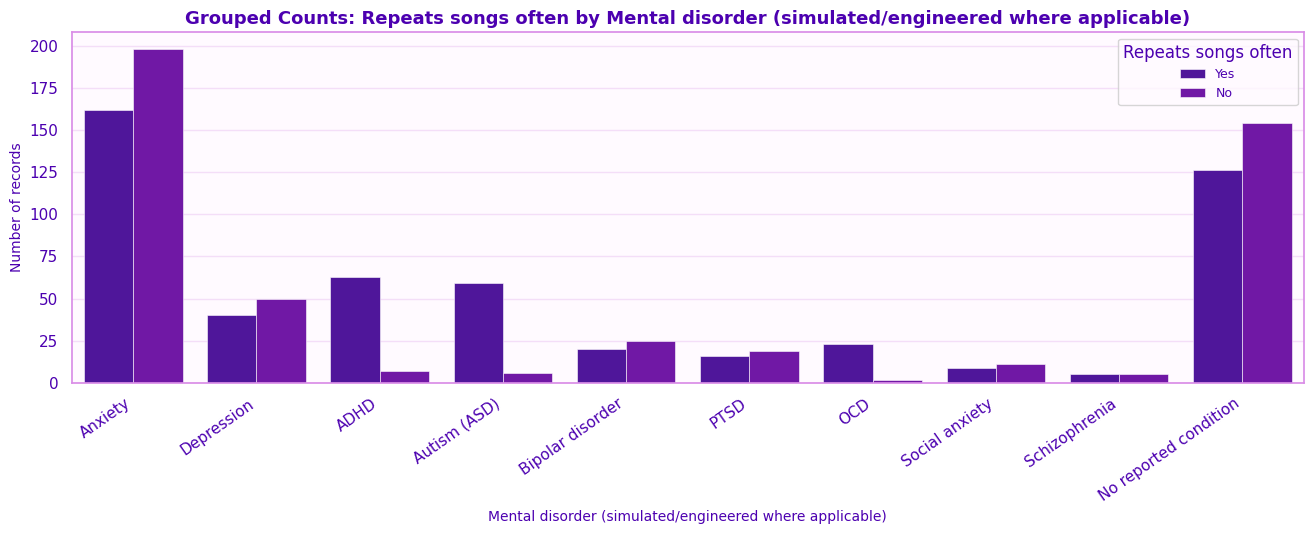

Saved: /content/plots/bivar_mental_disorder_vs_repeats_songs.png
Observation: Most frequent pair: Anxiety × No (n=198). Raw counts are influenced by the number of records in each group.


In [66]:
# Relationship: Mental disorder vs. repeats songs often — grouped count bar chart. Compare the recorded Yes/No counts by label.
# OBSERVATION: Repeat-song Yes rates are ADHD 90.0% (63/70), Autism (ASD) 90.8% (59/65), and OCD 92.0%
#     (23/25), versus 45.0% (126/280) for No reported condition.
# INTERPRETATION: The contrast is strong, but several group sizes are small (Schizophrenia n=10, Social anxiety
#     n=20, OCD n=25).
fig, observation = plot_category_pair_bar(clean_df, "mental_disorder", "repeats_songs_often")
save_and_show(fig, "bivar_mental_disorder_vs_repeats_songs.png")
print("Observation:", observation)

#### Bivar Mental Disorder Vs Repeats Songs Heatmap

count heatmap. Counts for each label and repeat-response combination are shown.

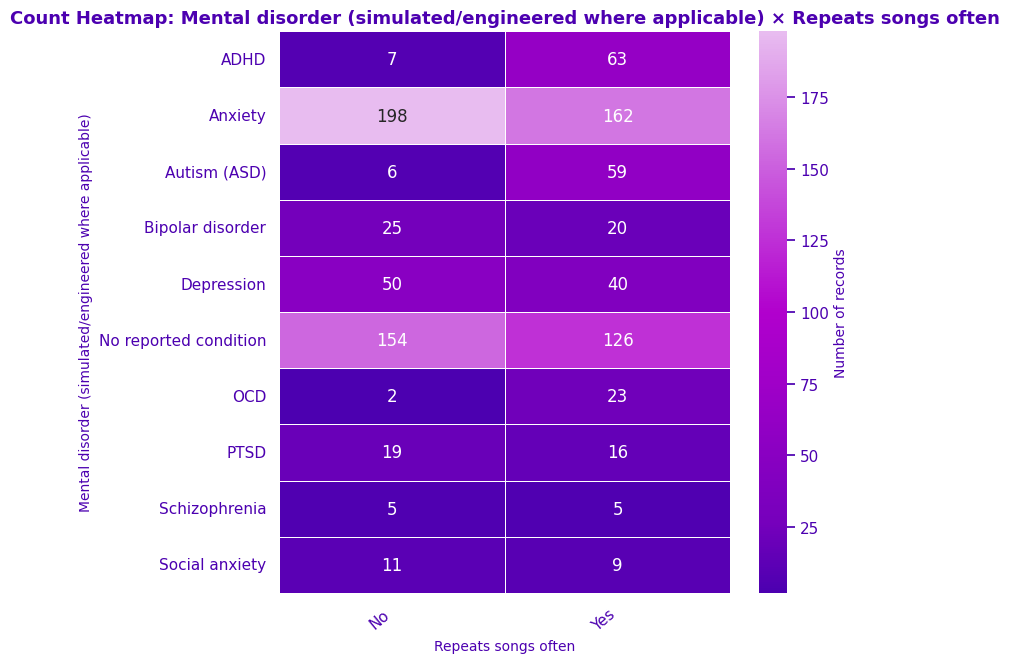

Saved: /content/plots/bivar_mental_disorder_vs_repeats_songs_heatmap.png
Observation: Highest-count cell: Anxiety × No (n=198). The heatmap shows raw counts for every category pair; group size matters when interpreting differences.


In [67]:
# Relationship: Mental disorder vs. repeats songs often — count heatmap. Counts for each label and repeat-response combination are shown.
# OBSERVATION: Repeat-song Yes rates are ADHD 90.0% (63/70), Autism (ASD) 90.8% (59/65), and OCD 92.0%
#     (23/25), versus 45.0% (126/280) for No reported condition.
# INTERPRETATION: The contrast is strong, but several group sizes are small (Schizophrenia n=10, Social anxiety
#     n=20, OCD n=25).
fig, observation = plot_category_pair_heatmap(clean_df, "mental_disorder", "repeats_songs_often")
save_and_show(fig, "bivar_mental_disorder_vs_repeats_songs_heatmap.png")
print("Observation:", observation)

<a id="r12"></a>

### Relationship 12 — Mental disorder vs. BPM

Mental-health-related label is categorical and BPM is numeric. Boxplots compare reported tempo distributions across labels, but should not be interpreted as clinical differences.

#### Bivar Mental Disorder Vs Bpm

categorical–numeric boxplot. Compare BPM medians, ranges, and outliers by simulated/engineered label.

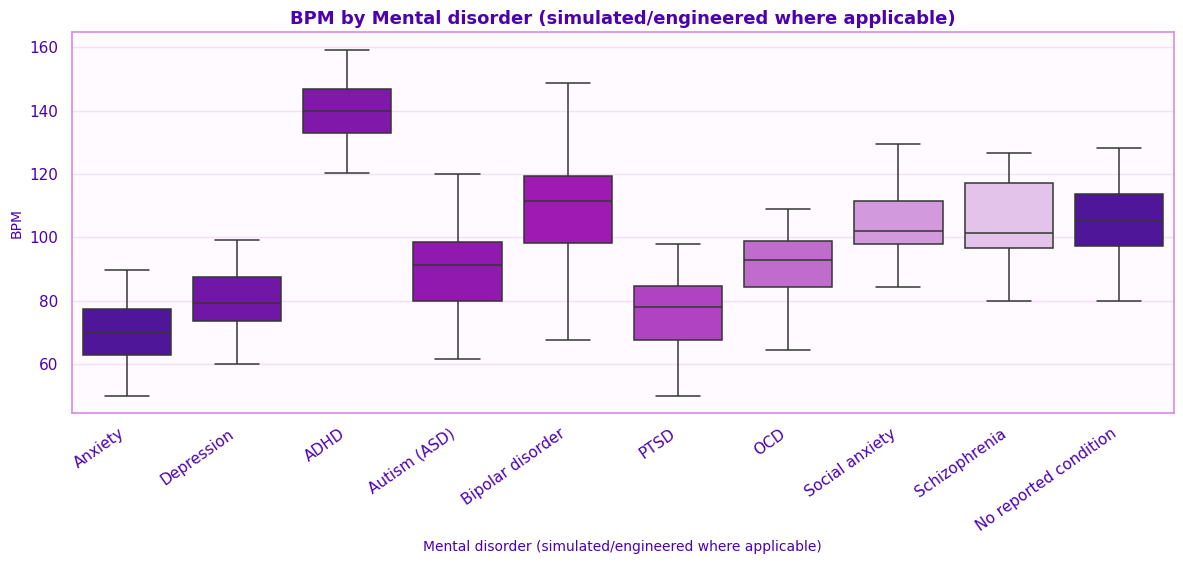

Saved: /content/plots/bivar_mental_disorder_vs_bpm.png
Observation: Median bpm ranges from Anxiety (70.10) to ADHD (139.80) across 10 mental disorder (simulated/engineered where applicable) groups. Compare spread and group sizes as well as medians.


In [68]:
# Relationship: Mental disorder vs. BPM — categorical–numeric boxplot. Compare BPM medians, ranges, and outliers by simulated/engineered label.
# OBSERVATION: ADHD has the highest median BPM (139.8; n=70), while Anxiety has the lowest (70.1; n=360).
#     Depression median is 79.3 BPM.
# INTERPRETATION: The condition groups show distinct tempo ranges in this dataset (e.g., ADHD 120.2–159.3 BPM;
#     Anxiety 50.0–89.8 BPM).
fig, observation = plot_numeric_by_category_box(clean_df, "mental_disorder", "bpm")
save_and_show(fig, "bivar_mental_disorder_vs_bpm.png")
print("Observation:", observation)

<a id="r13"></a>

### Relationship 13 — Mental disorder vs. listening time

Both variables are categorical. Compare raw record counts for morning, afternoon, evening, and late-night listening across the dataset's labels.

#### Bivar Mental Disorder Vs Listening Time

grouped count bar chart. Compare the raw number of each listening-time category.

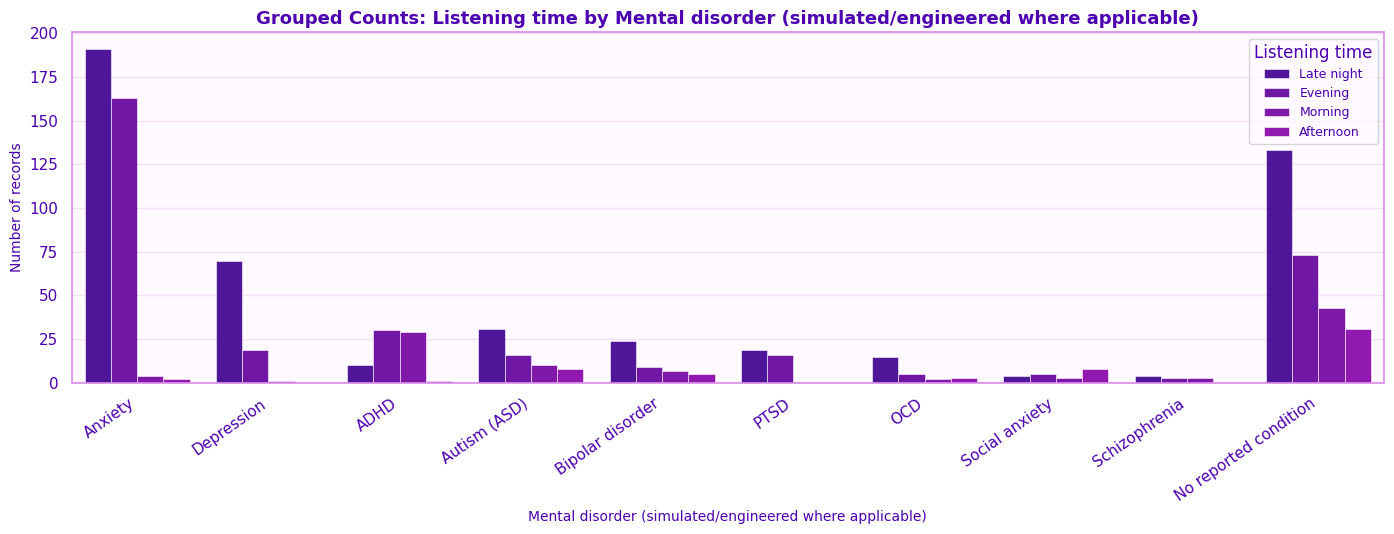

Saved: /content/plots/bivar_mental_disorder_vs_listening_time.png
Observation: Most frequent pair: Anxiety × Late night (n=191). Raw counts are influenced by the number of records in each group.


In [69]:
# Relationship: Mental disorder vs. listening time — grouped count bar chart. Compare the raw number of each listening-time category.
# OBSERVATION: Depression has 70/90 late-night records (77.8%); Anxiety has 191/360 late night (53.1%) and
#     163/360 evening (45.3%). PTSD is split 19 late night (54.3%) and 16 evening (45.7%).
# INTERPRETATION: ADHD is more evenly divided between Evening (30; 42.9%) and Morning (29; 41.4%).
fig, observation = plot_category_pair_bar(clean_df, "mental_disorder", "listening_time")
save_and_show(fig, "bivar_mental_disorder_vs_listening_time.png")
print("Observation:", observation)

#### Bivar Mental Disorder Vs Listening Time Heatmap

count heatmap. The heatmap includes all observed time/label combinations.

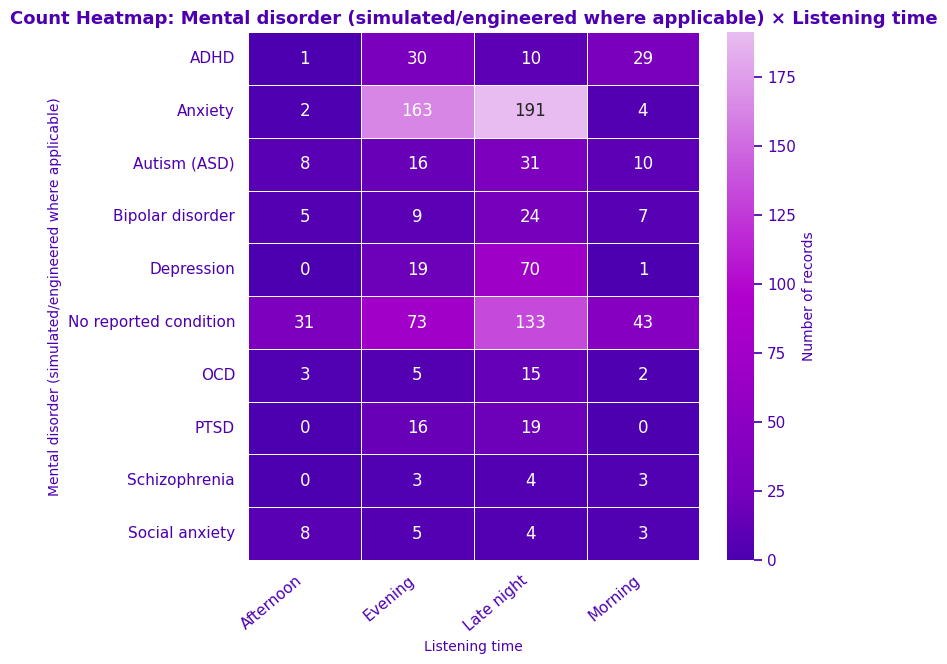

Saved: /content/plots/bivar_mental_disorder_vs_listening_time_heatmap.png
Observation: Highest-count cell: Anxiety × Late night (n=191). The heatmap shows raw counts for every category pair; group size matters when interpreting differences.


In [70]:
# Relationship: Mental disorder vs. listening time — count heatmap. The heatmap includes all observed time/label combinations.
# ACTUAL DATA OBSERVATION: Depression has 70/90 late-night records (77.8%); Anxiety has 191/360 late night (53.1%) and
#     163/360 evening (45.3%). PTSD is split 19 late night (54.3%) and 16 evening (45.7%).
# INTERPRETATION: ADHD is more evenly divided between Evening (30; 42.9%) and Morning (29; 41.4%).
fig, observation = plot_category_pair_heatmap(clean_df, "mental_disorder", "listening_time")
save_and_show(fig, "bivar_mental_disorder_vs_listening_time_heatmap.png")
print("Observation:", observation)

<a id="r14"></a>

### Relationship 14 — Mental disorder vs. music effects

Both variables are categorical. Compare the number of Improve, No effect, and Worsen records within each label. This is not evidence of clinical effects.

#### Bivar Mental Disorder Vs Music Effects

grouped count bar chart. Compare the observed effect counts across labels.

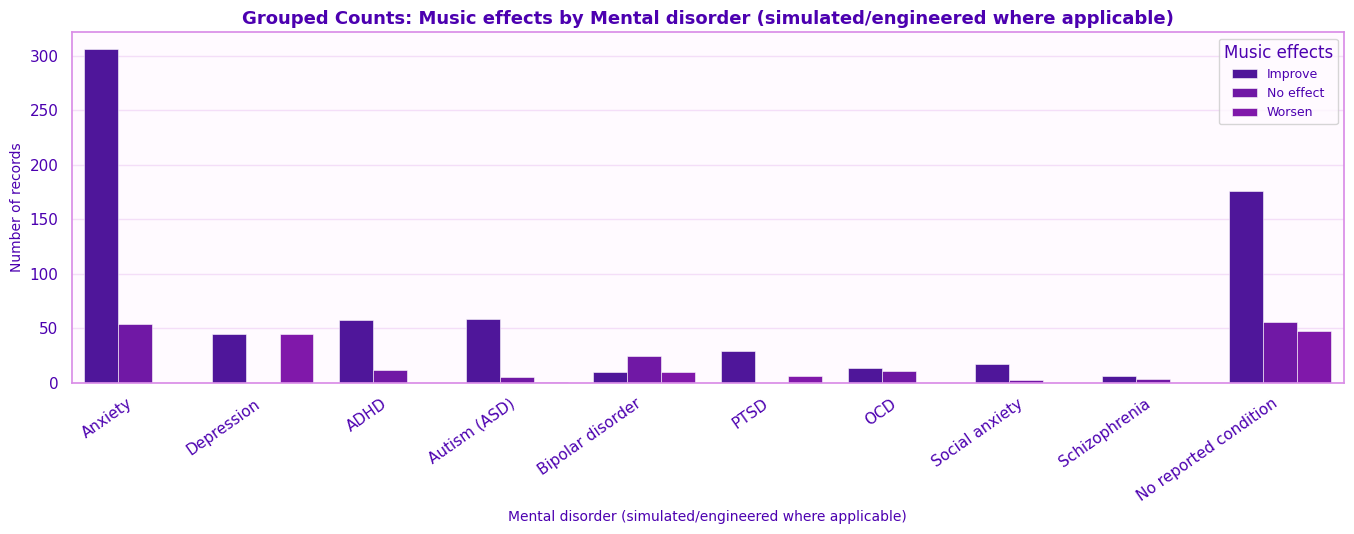

Saved: /content/plots/bivar_mental_disorder_vs_music_effects.png
Observation: Most frequent pair: Anxiety × Improve (n=306). Raw counts are influenced by the number of records in each group.


In [71]:
# Relationship: Mental disorder vs. music effects — grouped count bar chart. Compare the observed effect counts across labels.
# ACTUAL DATA OBSERVATION: Improve is common for Anxiety (306/360; 85.0%), Autism (ASD) (59/65; 90.8%), ADHD (58/70;
#     82.9%) and Social anxiety (17/20; 85.0%). Depression is exactly split between Improve and
#     Worsen (45 each; 50.0%).
# INTERPRETATION: Bipolar disorder has No effect as its largest category (25/45; 55.6%), and PTSD is 29/35
#     Improve (82.9%).
fig, observation = plot_category_pair_bar(clean_df, "mental_disorder", "music_effects")
save_and_show(fig, "bivar_mental_disorder_vs_music_effects.png")
print("Observation:", observation)

#### Bivar Mental Disorder Vs Music Effects Heatmap

count heatmap. All label/effect combinations are included.

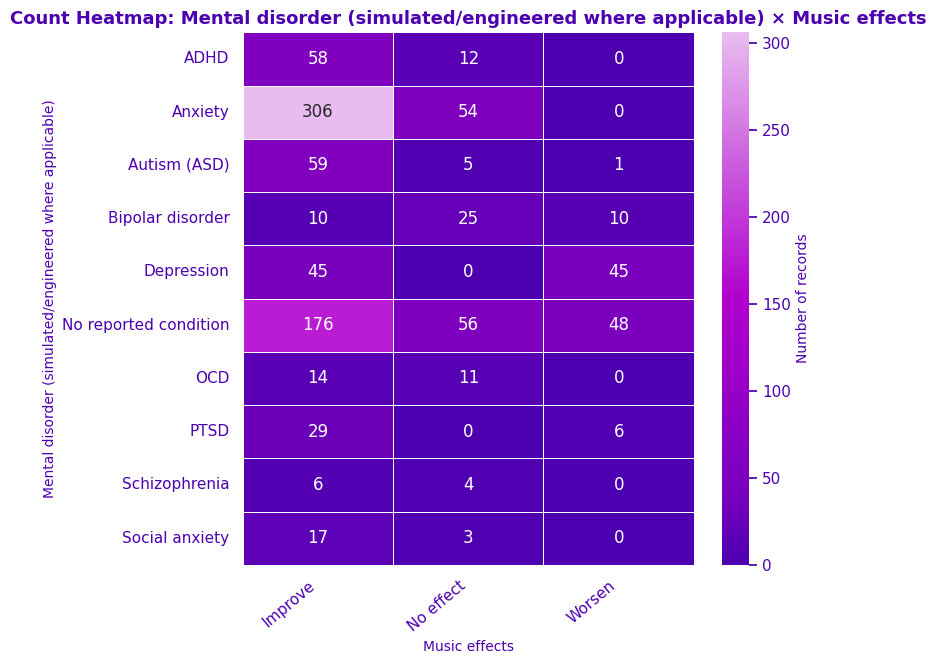

Saved: /content/plots/bivar_mental_disorder_vs_music_effects_heatmap.png
Observation: Highest-count cell: Anxiety × Improve (n=306). The heatmap shows raw counts for every category pair; group size matters when interpreting differences.


In [72]:
# Relationship: Mental disorder vs. music effects — count heatmap. All label/effect combinations are included.
# ACTUAL DATA OBSERVATION: Improve is common for Anxiety (306/360; 85.0%), Autism (ASD) (59/65; 90.8%), ADHD (58/70;
#     82.9%) and Social anxiety (17/20; 85.0%). Depression is exactly split between Improve and
#     Worsen (45 each; 50.0%).
# INTERPRETATION: Bipolar disorder has No effect as its largest category (25/45; 55.6%), and PTSD is 29/35
#     Improve (82.9%).
fig, observation = plot_category_pair_heatmap(clean_df, "mental_disorder", "music_effects")
save_and_show(fig, "bivar_mental_disorder_vs_music_effects_heatmap.png")
print("Observation:", observation)

<a id="r15"></a>

### Relationship 15 — Music effects vs. music genre

Both variables are categorical. Compare raw counts of reported effects across genres; genre groups can differ in size, so avoid interpreting raw count differences as rates.

#### Bivar Music Effect Vs Music Genre

grouped count bar chart. Compare the counts of Improve, No effect, and Worsen across genres.

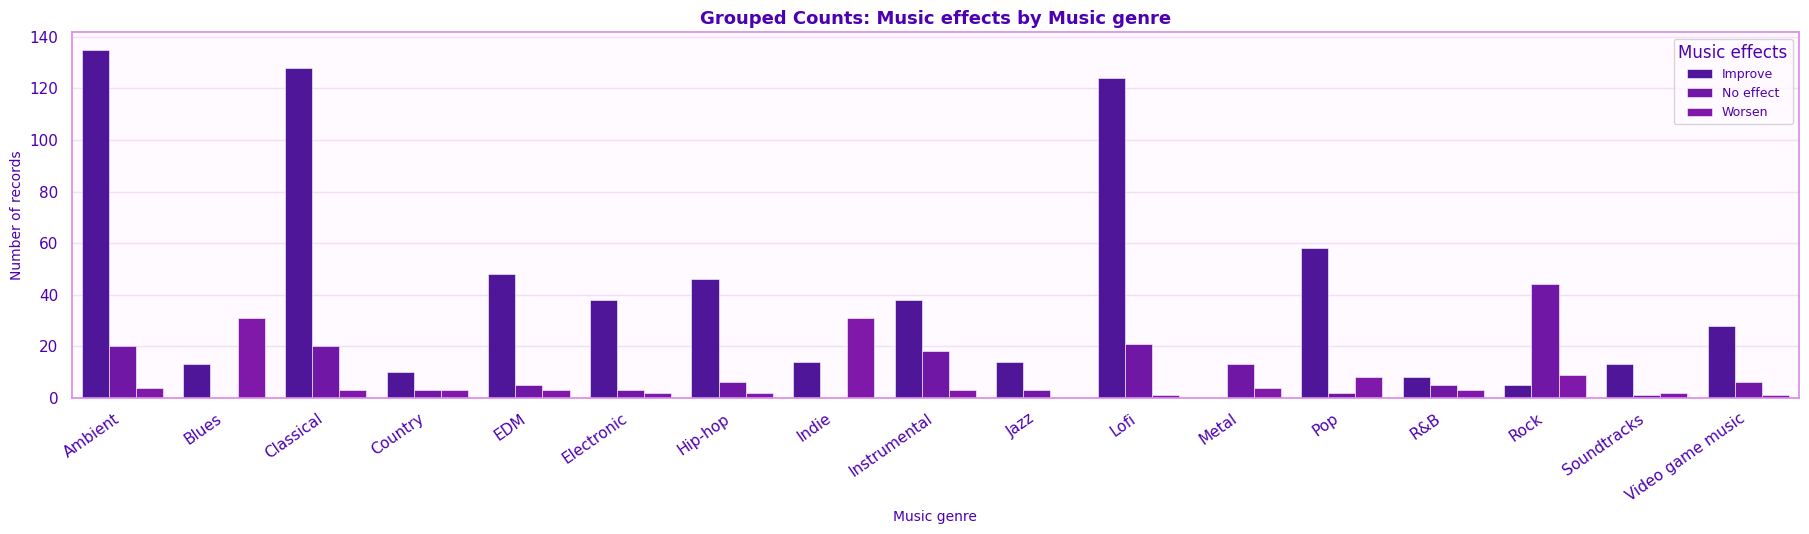

Saved: /content/plots/bivar_music_effect_vs_music_genre.png
Observation: Most frequent pair: Ambient × Improve (n=135). Raw counts are influenced by the number of records in each group.


In [73]:
# Relationship: Music effects vs. music genre — grouped count bar chart. Compare the counts of Improve, No effect, and Worsen across genres.
# OBSERVATION: Improve dominates Ambient (135/159; 84.9%), Classical (128/151; 84.8%), and Lofi (124/146;
#     84.9%). Rock is mainly No effect (44/58; 75.9%), as is Metal (13/17; 76.5%).
# INTERPRETATION: Worsen is most common in Blues (31/44; 70.5%) and Indie (31/45; 68.9%). Some genre groups are
#     small (e.g., Metal n=17).
fig, observation = plot_category_pair_bar(clean_df, "music_genre", "music_effects", top_n=17)
save_and_show(fig, "bivar_music_effect_vs_music_genre.png")
print("Observation:", observation)

#### Bivar Music Effect Vs Music Genre Heatmap

count heatmap. Every observed genre/effect combination is shown as a raw count.

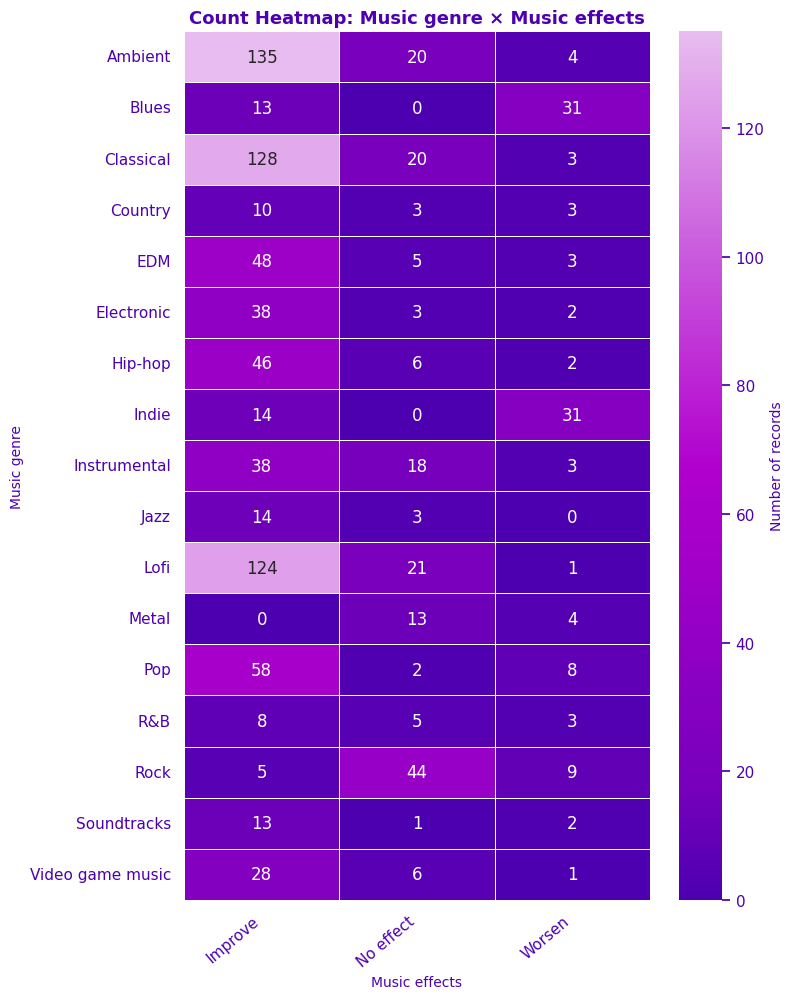

Saved: /content/plots/bivar_music_effect_vs_music_genre_heatmap.png
Observation: Highest-count cell: Ambient × Improve (n=135). The heatmap shows raw counts for every category pair; group size matters when interpreting differences.


In [74]:
# Relationship: Music effects vs. music genre — count heatmap. Every observed genre/effect combination is shown as a raw count.
# ACTUAL DATA OBSERVATION: Improve dominates Ambient (135/159; 84.9%), Classical (128/151; 84.8%), and Lofi (124/146;
#     84.9%). Rock is mainly No effect (44/58; 75.9%), as is Metal (13/17; 76.5%).
# INTERPRETATION: Worsen is most common in Blues (31/44; 70.5%) and Indie (31/45; 68.9%). Some genre groups are
#     small (e.g., Metal n=17).
fig, observation = plot_category_pair_heatmap(clean_df, "music_genre", "music_effects")
save_and_show(fig, "bivar_music_effect_vs_music_genre_heatmap.png")
print("Observation:", observation)

<a id="r-corr"></a>

### Overall numeric correlation matrix

This heatmap compares Pearson correlations for Age, Hours per day, and BPM. Values near +1 indicate a strong positive linear association, values near −1 indicate a strong negative linear association, and values near 0 indicate a weak linear association. Correlation does not establish causation.

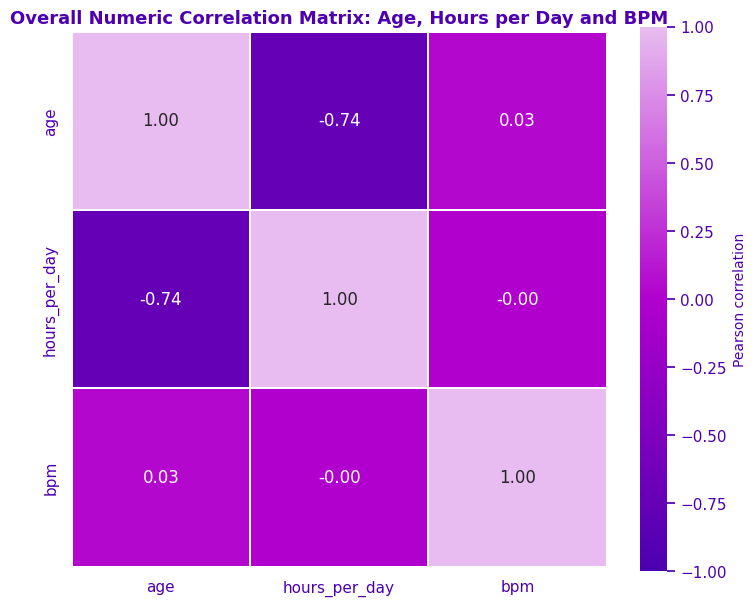

Saved: /content/plots/bivar_numeric_correlation_heatmap.png
Observation: Largest absolute correlation among numeric variables: Age × Hours per day (r=-0.743). Correlations summarize linear association, not causation.


In [75]:
# Overall numeric correlation: heatmap for age, hours per day, and BPM. Review the coefficients and identify the strongest absolute off-diagonal association.
# OBSERVATION: Among the numeric variables, Age vs Hours per day has r=-0.743; Age vs BPM has r=0.032; Hours
#     per day vs BPM has r=-0.001.
# INTERPRETATION: Age and listening hours have a strong negative linear association; the other two pairs are
#     close to zero.
fig, observation = plot_numeric_corr_heatmap(clean_df)
save_and_show(fig, "bivar_numeric_correlation_heatmap.png")
print("Observation:", observation)

<a id="step6"></a>

# Step 6 — Insights Summary
 The code below generates a few descriptive facts automatically.


In [76]:
# Key distribution tables for the report and dashboard.
insight_lines = []

if "music_effects" in clean_df.columns:
    effect_counts = clean_df["music_effects"].value_counts(dropna=False)
    effect_pct = (clean_df["music_effects"].value_counts(normalize=True, dropna=False) * 100).round(1)
    insight_lines.append("Reported music effects: " + "; ".join(
        f"{cat}: {count} ({effect_pct.get(cat, 0)}%)" for cat, count in effect_counts.items()
    ))

if "age" in clean_df.columns:
    insight_lines.append(
        f"Age: median {clean_df['age'].median():.1f}; mean {clean_df['age'].mean():.1f}; "
        f"range {clean_df['age'].min():.1f}–{clean_df['age'].max():.1f}."
    )
if "hours_per_day" in clean_df.columns:
    insight_lines.append(
        f"Daily listening hours: median {clean_df['hours_per_day'].median():.2f}; "
        f"mean {clean_df['hours_per_day'].mean():.2f}; "
        f"range {clean_df['hours_per_day'].min():.2f}–{clean_df['hours_per_day'].max():.2f}."
    )
if "bpm" in clean_df.columns:
    insight_lines.append(
        f"BPM: median {clean_df['bpm'].median():.1f}; mean {clean_df['bpm'].mean():.1f}; "
        f"range {clean_df['bpm'].min():.1f}–{clean_df['bpm'].max():.1f}."
    )
if "music_genre" in clean_df.columns and not clean_df["music_genre"].dropna().empty:
    top_genre = clean_df["music_genre"].value_counts().idxmax()
    top_genre_n = int(clean_df["music_genre"].value_counts().max())
    insight_lines.append(f"Most frequent music genre in this file: {top_genre} ({top_genre_n} records).")
if {"hours_per_day", "music_effects"}.issubset(clean_df.columns):
    medians = clean_df.groupby("music_effects", dropna=False)["hours_per_day"].median().sort_values(ascending=False)
    insight_lines.append("Median listening hours by reported effect: " + "; ".join(
        f"{cat}: {val:.2f} h/day" for cat, val in medians.items()
    ))

print("DESCRIPTIVE INSIGHTS:")
for line in insight_lines:
    print("•", line)

print("\nLIMITATIONS TO INCLUDE:")
print("• Observed associations may be affected by sample composition, data construction, confounding variables, and missing context.")

DESCRIPTIVE INSIGHTS:
• Reported music effects: Improve: 720 (72.0%); No effect: 170 (17.0%); Worsen: 110 (11.0%)
• Age: median 21.0; mean 24.7; range 13.0–82.0.
• Daily listening hours: median 4.85; mean 5.18; range 1.01–7.80.
• BPM: median 86.2; mean 90.4; range 50.0–159.3.
• Most frequent music genre in this file: Ambient (159 records).
• Median listening hours by reported effect: No effect: 4.96 h/day; Worsen: 4.90 h/day; Improve: 4.81 h/day

LIMITATIONS TO INCLUDE:
• Observed associations may be affected by sample composition, data construction, confounding variables, and missing context.


## 6.1 Final insights:

- **Patterns:** Which categories are most common? How are the numerical variables distributed?
- **Relationships:** Do median listening hours or counts differ between the reported effect groups? What does the scatterplot suggest?
- **Outliers:** Which values were flagged by the IQR method? Are they plausible or data-entry errors?
- **Key takeaways:** What are the two or three most important observations in this file?

In [77]:
# Final summary points from the current cleaned dataset so the conclusions remain in sync with the plots.
final_insights = {}

if "music_effects" in clean_df.columns:
    effect_counts = clean_df["music_effects"].value_counts(dropna=False)
    effect_summary = "; ".join(f"{category}: {int(count)} records" for category, count in effect_counts.items())
else:
    effect_summary = "The music_effects field is unavailable."

numeric_descriptions = []
for col in ["age", "hours_per_day", "bpm"]:
    if col in clean_df.columns:
        values = pd.to_numeric(clean_df[col], errors="coerce").dropna()
        if not values.empty:
            numeric_descriptions.append(f"{col}: median {values.median():.2f}, mean {values.mean():.2f}, range {values.min():.2f}–{values.max():.2f}")

top_category_summaries = []
for col in ["music_genre", "listening_time", "listening_setting", "vibe_reason"]:
    if col in clean_df.columns and not clean_df[col].dropna().empty:
        counts = clean_df[col].value_counts()
        top_category_summaries.append(f"{col}: {counts.index[0]} (n={int(counts.iloc[0])})")

corr_summary = ""
if {"age", "hours_per_day"}.issubset(clean_df.columns):
    numeric_pair = clean_df[["age", "hours_per_day"]].apply(pd.to_numeric, errors="coerce").dropna()
    if len(numeric_pair) > 1 and numeric_pair.nunique().min() > 1:
        corr_summary = f"Pearson correlation between age and daily listening hours: r={numeric_pair['age'].corr(numeric_pair['hours_per_day']):.3f}."

outlier_summary = []
for col in ["age", "hours_per_day", "bpm"]:
    if col in clean_df.columns:
        values = pd.to_numeric(clean_df[col], errors="coerce").dropna()
        if not values.empty:
            q1, q3 = values.quantile([.25, .75]); iqr = q3 - q1
            n_out = int(((values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)).sum())
            outlier_summary.append(f"{col}: {n_out}")

final_insights["patterns"] = f"Reported music effects: {effect_summary}. " + ("Numeric summaries: " + "; ".join(numeric_descriptions) + ". " if numeric_descriptions else "")
final_insights["category_patterns"] = "Most frequent categories: " + ("; ".join(top_category_summaries) if top_category_summaries else "no category summaries available") + "."
final_insights["relationships"] = corr_summary or "A numeric correlation summary could not be calculated from the current data."
final_insights["outliers"] = "Potential observations flagged by the IQR rule: " + ("; ".join(outlier_summary) if outlier_summary else "none calculated") + ". These flags are not proof of data errors."
final_insights["key_takeaways"] = "Use histograms and boxplots to describe numeric distributions, countplots and count bar charts to identify frequent categories, and relationship charts to compare variable pairs. Raw counts depend on group sizes; associations are not causal."
final_insights["limitations"] = "The working dataset has been modified/engineered. Mental-disorder categories may be simulated and must not be treated as verified diagnoses. Music-effect labels are subjective, and analysis is descriptive rather than causal."

for section, content in final_insights.items():
    print(f"{section.replace('_', ' ').title()}: {content}\n")

Patterns: Reported music effects: Improve: 720 records; No effect: 170 records; Worsen: 110 records. Numeric summaries: age: median 21.00, mean 24.68, range 13.00–82.00; hours_per_day: median 4.85, mean 5.18, range 1.01–7.80; bpm: median 86.20, mean 90.43, range 50.00–159.30. 

Category Patterns: Most frequent categories: music_genre: Ambient (n=159); listening_time: Late night (n=501); listening_setting: Home / relaxing (n=418); vibe_reason: Calming/relaxation (n=412).

Relationships: Pearson correlation between age and daily listening hours: r=-0.743.

Outliers: Potential observations flagged by the IQR rule: age: 87; hours_per_day: 0; bpm: 2. These flags are not proof of data errors.

Key Takeaways: Use histograms and boxplots to describe numeric distributions, countplots and count bar charts to identify frequent categories, and relationship charts to compare variable pairs. Raw counts depend on group sizes; associations are not causal.

Limitations: The working dataset has been mod

<a id="step7"></a>

# Step 7 — Final Summary

## Main insights

**1. Most people say music helps.** 720 of 1,000 respondents (72%) say music improves how they feel, 170 (17%) report no effect and 110 (11%) say it makes them feel worse. Because the groups are so unequal, I compared percentages within groups and not just raw counts.

**2. The sample is young and listens a lot.**
- Age runs from 13 to 82, but the median is only 21. The distribution is strongly right-skewed (skew 2.07), and 46.8% of respondents are 13–20.
- People listen 5.18 hours a day on average (median 4.85); the middle half listen between 4.0 and 6.9 hours.
- Spotify is the main platform for 61.2% of respondents.

**3. Late night at home is the typical listening situation.**
- Half the respondents (50.1%) listen mostly late at night and a third (33.9%) in the evening; afternoon is rare (5.8%).
- Home / relaxing is the most common setting (41.8%), followed by transport (21.3%).
- Calming/relaxation is the most common reason for listening (41.2%).

**4. Genre separates the reported effect much more than listening time does.**
- Ambient, Classical and Lofi listeners report *Improve* about 85% of the time.
- Rock (75.9%) and Metal (76.5%) listeners mostly report *No effect*.
- Blues (70.5%) and Indie (68.9%) listeners mostly report *Worsen*.
- By contrast, median listening hours are almost the same across the three effect groups (4.81–4.96 h), so *how much* people listen doesn't distinguish them.

**5. Younger respondents listen much more.**
- Age and daily hours have a strong negative correlation (r = −0.74): people aged 13–20 average 6.8 hours a day, compared with about 2.3 hours for people aged 40 and over.
- Younger people are also the ones listening late at night (median age 20, against 25–26 for morning and afternoon) and on transport or at home (median ages 18–19).
- BPM is unrelated to both age and listening hours (r ≈ 0).

**6. Musical people are more open to music in other languages.**
- 97.3% of instrumentalists listen to foreign-language music, against 61.6% of non-instrumentalists.
- 87.3% of exploratory listeners do, against 31.0% of non-exploratory listeners.
- Composers are a small group (13.8%) with a very narrow profile: they only listen at home (60%) or on transport (40%), and 80% of them mostly listen late at night.

**7. The mental-health groups have very distinct music profiles.**
- Anxiety records prefer Ambient, Classical and Lofi, slow music (median about 70 BPM) and calming/relaxation; 85% report *Improve*.
- ADHD records prefer EDM and Hip-hop and the fastest tempos (median about 140 BPM); 90% replay songs often.
- Depression is the most late-night group (77.8%) and is split exactly 50/50 between *Improve* and *Worsen*.
- Bipolar disorder is the only group where *No effect* is the most common answer (55.6%).

**8. Outliers.** The IQR rule flags 87 ages (all above 40.5), 2 tempos above about 155 BPM, and no listening-hour values. All of them are plausible answers rather than errors, so I kept them.

All of these are associations. The data shows which things go together, not what causes what.

## What I learned

Each type of chart answered a different part of the question:
- **Histograms and boxplots** showed the shape of the numbers. For example, age is heavily right-skewed while listening hours are fairly symmetric.
- **Count plots** showed how unbalanced many variables are: 72% *Improve*, 86% non-composers, 61% Spotify.
- **The scatter plot and correlation matrix** showed that age vs. listening hours is the only strong numeric relationship.
- **Grouped bars and heatmaps** showed where categories go together, such as genre and the reported effect.

I also learned to check group sizes before trusting a comparison. Anxiety (360 records) dominates every cross-tab simply because it's the largest group, while Schizophrenia (10), Metal (17) and Social anxiety (20) are too small for their percentages to be reliable. Raw counts and percentages can tell quite different stories, so I compared within-group percentages wherever the groups differed in size.

## Limitations of the dataset

- **Modified data.** The dataset is an extended version of the MXMH survey. Fields such as `music_genre`, `listening_time`, `listening_setting`, `vibe_reason` and `mental_disorder` were added through supplementary responses or derived , so the results describe this working dataset rather than the original survey.
- **Unbalanced sample.** The sample is young (median age 21, almost half under 21), and the outcome is dominated by *Improve* (72%).
- **Small groups.** Schizophrenia (10), Soundtracks, Country and R&B (16 each), Metal (17), Social anxiety (20) and OCD (25) all have fewer than 30 records, so their percentages are unstable.

## Recommendations for future analysis

- Repeat the analysis on original, fully documented real survey data.
- Where possible, collect enough independent real responses for smaller groups.
- Building a predictive model, avoiding leakage, using stratified cross-validation, and reporting per-class metrics rather than accuracy alone.